# Projeto Prático 2: Redução de Dimensionalidade no Fashion-MNIST

Relatório final. **Este notebook não treina nada**: só lê os artefactos guardados em `outputs/`
(modelos, projeções, latentes, métricas em CSV e figuras) gerados pelos scripts em `src/`
(ver `README.md` e `run_all.sh`). As decisões e justificações estão em `docs/DECISIONS.md` e o
diário de execução em `docs/LOG.md`.

Splits: 54 000 train / 6 000 val (estratificados, seed 42) / 10 000 test (intocado até à avaliação final).
A extensão de cor **não** foi usada.

**Adenda:** dois autoencoders especializados, Conv-VAE (`vae_conv`) e Conv-DAE (`dae_conv`), com a mesma
grelha de d. Estão na secção **4.4** e aparecem como linhas extra nas tabelas e figuras das Fases 3, 5, 6 e 8.

**Como ler.** Cada figura e cada tabela tem uma legenda com o script, a função e a linha onde é escrita, o cálculo,
os dados de entrada e o comando que a refaz. No início de cada fase há um bloco **Método e código**.
O `src/provenance.py` gera esta informação e falha se algum ficheiro de `outputs/` ficar sem origem ou se uma
função citada não existir.

## Índice das fases

| Fase | O que é | Pergunta a que responde | Scripts principais |
|---|---|---|---|
| [Mapa do código](#mapa) | Lista de todos os scripts e funções obrigatórias | Onde está cada coisa? | todos |
| [Fase 0](#fase-0) | Preparação: leitura dos dados, splits, normalização e teste de GPU | Os dados estão bem divididos? Que batch usar? | `src/data.py`, `src/train_ae.py` |
| [Fase 1](#fase-1) | Exploração: imagens médias, distâncias entre classes e kNN em pixels | Que classes são mais difíceis de separar? | `src/eda.py` |
| [Fase 2](#fase-2) | PCA, whitening, IncrementalPCA, KernelPCA, LDA e dimensão intrínseca (TwoNN) | Quantas dimensões são precisas? | `src/pca_lda.py`, `src/representation.py` |
| [Fase 3](#fase-3) | Mapas 2D com t-SNE e UMAP, e a sua qualidade | Que estrutura se vê em 2D, e até que ponto é fiel? | `src/viz_nonlinear.py` |
| [Fase 4](#fase-4) | Autoencoders Dense, Conv e Transformer com d de 2 a 128; na secção 4.4, o VAE e o DAE | Quanto se reconstrói com cada d? Os latentes separam as classes? O que muda com outro objetivo de treino? | `src/models.py`, `src/train_ae.py`, `src/embeddings_viz.py`, `src/specialized.py`, `src/robustness.py` |
| [Fase 5](#fase-5) | Os mesmos classificadores em todas as representações, com uma CNN como teto | Que representação classifica melhor, e a partir de que d deixa de melhorar? | `src/classification.py`, `src/train_cnn.py` |
| [Fase 6](#fase-6) | Procura de imagens parecidas em vários espaços, com e sem labels | O melhor espaço para classificar também é o melhor em semelhança visual? | `src/retrieval.py` |
| [Fase 7](#fase-7) | Extensão de cor: não realizada, porque o enunciado a exclui | | |
| [Fase 8](#fase-8) | Procura automática de erros e agrupamento por causa provável | Onde e porque falham as representações? | `src/failures.py` |
| Fase 9 | Este relatório: só lê `outputs/`, nunca treina | De onde vem cada resultado? | `notebooks/report.ipynb`, `src/provenance.py` |
| [Conclusões](#conclusoes) | Síntese dos resultados | O que usar em cada caso? | |
| [Anexos](#anexos) | Requisitos ligados ao código e índices de figuras, tabelas e modelos | Onde está cada requisito e cada ficheiro? | `src/provenance.py` |

In [1]:
import json
import re
from fnmatch import fnmatch
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

OUT = Path('..') / 'outputs' if Path('../outputs').exists() else Path('outputs')
FIG = OUT / 'figures'
MET = OUT / 'metrics'
pd.set_option('display.precision', 4)
pd.set_option('display.max_rows', 80)
pd.set_option('display.width', 200)
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

PROV = pd.read_csv(MET / 'provenance.csv').set_index('artefacto')
N = {'figura': 0, 'tabela': 0}
MOSTRADAS = {'figura': {}, 'tabela': {'outputs/metrics/provenance.csv': 'Anexos B a D'}}

def _origem(rel):
    r = PROV.loc[rel]
    return f"`{r.script}`, função `{r.funcao}()`, linha {r.linha}", r

def _dados(txt, proprio=None):
    # junta a cada ficheiro de entrada o sítio onde esse ficheiro é calculado
    def anota(m):
        tok = m.group(0)
        padrao = re.sub(r'\{[^}]*\}', '*', tok)
        hit = next((a for a in PROV.index if a != proprio and fnmatch(a, padrao)), None)
        if hit is None:
            return f'`{tok}`'
        r = PROV.loc[hit]
        return f'`{tok}` (calculado em `{r.script}`, `{r.funcao}()`, linha {r.linha})'
    return re.sub(r'outputs/(?:[^\s,{}]|\{[^}]*\})+', anota, txt)

def _texto(r):
    return f"**Cálculo:** {r.calculo}. **Dados:** {_dados(r.dados, r.name)}. **Refazer:** `{r.comando}`"

def _maiuscula(s):
    return s[:1].upper() + s[1:] if isinstance(s, str) else ''

def fig(name, width=None):
    rel = f'outputs/figures/{name}'
    p = FIG / name
    if not p.exists():
        display(Markdown(f'*figura `{name}` ainda não gerada*'))
        return
    display(Image(filename=str(p), width=width))
    N['figura'] += 1
    MOSTRADAS['figura'][name] = N['figura']
    onde, r = _origem(rel)
    display(Markdown(f"**Figura {N['figura']}.** {_maiuscula(r.descricao)}. Ficheiro `{rel}`. **Gerada em** {onde}. {_texto(r)}."))

def fig_notebook(titulo, rel):
    # legenda de uma figura desenhada aqui, a partir de um artefacto guardado
    N['figura'] += 1
    MOSTRADAS['figura'][f'(notebook) {titulo}'] = N['figura']
    onde, r = _origem(rel)
    pasta = rel.rsplit('/', 2)[0]
    display(Markdown(f"**Figura {N['figura']}.** {titulo}. **Desenhada** nesta célula, a partir de `{pasta}/*/{rel.rsplit('/', 1)[1]}`. "
                     f"**Dados escritos em** {onde}. {_texto(r)}."))

def csv(name, legenda=True, **kw):
    # lê uma tabela de outputs/metrics (ou outro caminho dentro de outputs/) e escreve a legenda
    rel = f'outputs/{name}' if '/' in name and not name.startswith('confusion/') else f'outputs/metrics/{name}'
    p = Path('..') / rel if Path('../outputs').exists() else Path(rel)
    if not p.exists():
        display(Markdown(f'*tabela `{name}` ainda não gerada*'))
        return None
    if legenda:
        N['tabela'] += 1
        MOSTRADAS['tabela'][rel] = N['tabela']
        onde, r = _origem(rel)
        desc = f'{_maiuscula(r.descricao)}. ' if isinstance(r.descricao, str) else ''
        display(Markdown(f"**Tabela {N['tabela']}.** {desc}Ficheiro `{rel}`. **Escrita em** {onde}. {_texto(r)}."))
    return pd.read_csv(p, **kw)

def largo(df):
    # campos de texto sem valor ficam em branco, não como NaN
    df = df.convert_dtypes()
    df = df.astype(object).where(df.notna(), '')
    with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
        display(df)

<a id="mapa"></a>

## Mapa do código: que script faz o quê

Todos os scripts do projeto. A coluna `papel` indica se o ficheiro foi pedido pelo nome no enunciado (`enunciado`), se
implementa uma fase do enunciado (`implementa o enunciado`), se vem da `adenda` ou se é de `apoio`. As funções
obrigatórias estão em `src/representation.py` (PCA e autoencoders) e `src/retrieval.py` (`retrieve`).

In [2]:
s = csv('scripts.csv')
largo(s[['script', 'papel', 'fase', 'descricao', 'funcoes_principais', 'comando', 'importado_por', 'linhas']])

**Tabela 1.** Mapa dos scripts: papel, fase, funções principais, comando, quem os importa. Ficheiro `outputs/metrics/scripts.csv`. **Escrita em** `src/provenance.py`, função `main()`, linha 541. **Cálculo:** mapa de `src/provenance.py::tabela_scripts`; as dependências são lidas dos imports (`src/provenance.py::_dependencias`). **Dados:** src/*.py. **Refazer:** `python -m src.provenance`.

,script,papel,fase,descricao,funcoes_principais,comando,importado_por,linhas
0,config.yaml,enunciado,Todas,"configuração central: seed, splits e hiperparâmetros de todas as fases",,lido por `src/utils.py::load_config`,,101
1,src/data.py,enunciado,Fase 0,"leitura IDX, normalização [0,1], splits estratificados","prepare, load_split, viz_indices, stratified_subset",python -m src.data,"classification, eda, embeddings_viz, failures, pca_lda, retrieval, robustness, specialized, train_ae, viz_nonlinear",111
2,src/representation.py,enunciado,Fases 4–8,funções obrigatórias: projeção/reconstrução PCA e encode/decode dos AEs,"pca_project, pca_reconstruct, ae_encode, ae_decode, ae_reconstruct",importado (sem comando próprio),"embeddings_viz, retrieval, robustness, specialized",91
3,src/models.py,enunciado,Fases 4–5,"DenseAE, ConvAE, TransformerAE, ConvVAE, CNN supervisionada","DenseAE, ConvAE, ConvVAE, TransformerAE, SupervisedCNN, build_ae",importado (sem comando próprio),"representation, retrieval, train_ae, train_cnn",202
4,src/train_ae.py,enunciado,"Teste de GPU, Fase 4","script único de treino (--arch --dim), grelha, smoke test, sondagem de GPU, VAE e DAE","fit, train_one, collect, grid, smoke, probe, train_loss, kl_div, add_noise",python -m src.train_ae --grid --jobs 2 --with-cnn,train_cnn,538
5,src/retrieval.py,enunciado,Fase 6,"retrieve(query_image, space, k, metric), registo de espaços, descritores, avaliação, painéis","retrieve, available_spaces, _registry, compute_features, label_metrics, proxy_metrics, evaluate_all, panels",python -m src.retrieval,"failures, robustness",421
6,src/evaluate.py,enunciado,Todas,kNN em GPU e todas as métricas,"knn_search, knn_predict, cls_metrics, confusion, logreg, embedding_quality, clustering_metrics, twonn, ssim_pairs, SSIMGallery, silhouette_iou",importado (sem comando próprio),"classification, eda, embeddings_viz, failures, pca_lda, retrieval, robustness, specialized, train_ae, train_cnn, viz_nonlinear",200
7,src/utils.py,enunciado,Todas,"config, seeds, logs, manifesto, gravação atómica","load_config, set_seed, get_logger, register, save_npy, save_json, out",importado (sem comando próprio),"classification, data, eda, embeddings_viz, evaluate, failures, pca_lda, plots, provenance, representation, retrieval, robustness, specialized, train_ae, train_cnn, viz_nonlinear",133
8,notebooks/report.ipynb,enunciado,Fase 9,relatório final; só lê outputs/,,jupyter nbconvert --execute --inplace notebooks/report.ipynb,,
9,README.md,enunciado,Fase 9,"como correr, estrutura, seeds, nota sobre a extensão de cor",,-,,137


**Ordem de execução** (`run_all.sh`): `src/data.py` → `src/eda.py` → `src/train_ae.py --smoke` e `--probe` → `src/pca_lda.py` →
`src/train_ae.py --grid` (com `src/train_cnn.py`) → grelha dos especializados → `src/viz_nonlinear.py` → `src/embeddings_viz.py` →
`src/classification.py` → `src/retrieval.py` → `src/failures.py` → `src/robustness.py` → `src/specialized.py` →
`src/provenance.py` → este notebook. Todos leem `config.yaml` através de `src/utils.py::load_config`; as figuras passam por
`src/plots.py::savefig`, que as regista em `outputs/manifest.json` com `src/utils.py::register`.

**Funções obrigatórias do enunciado:**

```python
from src.representation import pca_project, pca_reconstruct, ae_encode, ae_decode
Z = pca_project(X, k=64)                # src/representation.py: projeção PCA
Xr = pca_reconstruct(Z, k=64)           # src/representation.py: reconstrução PCA
z = ae_encode(X, "conv_ae", 32)         # src/representation.py: latente de qualquer AE
Xr = ae_decode(z, "conv_ae", 32)        # src/representation.py: imagem a partir do latente

from src.retrieval import retrieve, available_spaces
res = retrieve(query_image, space="conv_ae_d32", k=10, metric="cosine")   # src/retrieval.py
res["indices"], res["distances"]        # índices na galeria (split train) e distâncias
```

```bash
python src/train_ae.py --arch conv_ae --dim 32     # script único de treino, src/train_ae.py
```

Registo: `docs/DECISIONS.md` (o quê e porquê), `docs/LOG.md` (diário), `outputs/manifest.json` (índice),
`outputs/logs/` (um log por script ou treino), `docs/PROVENIENCIA.md` (estas tabelas fora do notebook).

<a id='fase-0'></a>

## Fase 0: Preparação dos dados e da GPU

### 0.1 Divisão dos dados e normalização

**Método e código.**
- **Leitura:** ficheiros IDX `.gz` de `dados/`, lidos por `src/data.py::_read_idx` e `src/data.py::load_raw`. A pasta `dados/` nunca é alterada.
- **Splits:** `src/data.py::prepare` usa `train_test_split` estratificado (seed 42) para 54 000 train e 6 000 val; o test são os 10 000 originais, usado só nas tabelas finais. Os índices ficam em `outputs/splits/`.
- **Normalização:** divisão por 255, float32, em duas versões: flatten (784) e imagem (1×28×28). Todos os scripts as leem com `src/data.py::load_split`.
- **Subconjunto de visualização:** 10 000 índices estratificados do train, lidos com `src/data.py::viz_indices`, usados nas Fases 3 e 4.
- **Reprodutibilidade:** `src/utils.py::set_seed` fixa as seeds de Python, NumPy e PyTorch; `config.yaml` guarda todos os parâmetros. Os artefactos são escritos de forma atómica por `src/utils.py::save_npy` e `src/utils.py::save_json`.

In [3]:
ambiente = (OUT / 'env.txt').read_text().splitlines()
chave = ('torch==', 'scikit-learn==', 'umap-learn==', 'scikit-image==', 'numpy==', 'pandas==', 'matplotlib==')
print('Ambiente (outputs/env.txt, escrito por run_all.sh):')
print('\n'.join(ambiente[:3] + [l for l in ambiente if l.startswith(chave)]))

Ambiente (outputs/env.txt, escrito por run_all.sh):
# Ambiente (2026-10-30 00:08)
Python 3.10.12
NVIDIA GeForce RTX 2080 Ti, 11264 MiB, 580.126.09
matplotlib==3.10.9
numpy==2.2.6
pandas==2.3.3
scikit-image==0.25.2
scikit-learn==1.7.2
torch==2.6.0+cu124
umap-learn==0.5.12


In [4]:
ys = {s: np.load(OUT / 'data' / f'y_{s}.npy') for s in ('train', 'val', 'test')}
pd.DataFrame({s: np.bincount(y, minlength=10) for s, y in ys.items()}, index=CLASSES).T.assign(total=lambda d: d.sum(1))

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot,total
train,5400,5400,5400,5400,5400,5400,5400,5400,5400,5400,54000
val,600,600,600,600,600,600,600,600,600,600,6000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,10000


Os três splits estão perfeitamente balanceados (10% por classe). As imagens foram normalizadas para [0,1] e guardadas em formato flatten (784) e imagem (1×28×28); os índices dos splits estão em `outputs/splits/`.

### 0.2 Teste de GPU e escolha do batch

**Método e código.**
- **Smoke test** (`src/train_ae.py::smoke`): valida as formas de `encode`/`decode` e corre 1 época por arquitetura com d=2 e d=128.
- **Sondagem** (`src/train_ae.py::probe`): com d=128, duplica o batch desde 128 até OOM ou até ao tamanho do train. Mede 25 passos depois de 5 de aquecimento, com `torch.cuda.max_memory_allocated`. O AMP fp16 só é testado a 256 e 1024. Como a GPU é partilhada, o processo fica limitado à memória livre menos 1.5 GB.
- **Convergência:** 5 épocas de cada arquitetura com d=32, para batch de 128 a 2048 e o mesmo LR.
- **Dados em GPU:** `src/train_ae.py::GPUBatchLoader` e `src/train_ae.py::load_gpu_data` substituem o `DataLoader`, eliminando o gargalo do loader.
- **Decisão** (`docs/DECISIONS.md`, 00:20): batch 256 em todas as arquiteturas, fp32, 2 treinos em paralelo. A memória não era o limite, mas batches grandes pioram a convergência com o mesmo número de épocas. O maior batch que deixaria 15–20% livres seria cerca de 2048 no Transformer e 8192 no ConvAE.

In [5]:
display(csv('smoke_test.csv'))
display(csv('smoke_test_specialized.csv'))

**Tabela 2.** Smoke test: 1 época por arquitetura com d=2 e d=128. Ficheiro `outputs/metrics/smoke_test.csv`. **Escrita em** `src/train_ae.py`, função `smoke()`, linha 431. **Cálculo:** 1 época por arquitetura, com d=2 e d=128 (`src/train_ae.py::fit`). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_ae --smoke`.

,arch,d,params,train_mse,val_mse,epoch_time_s,peak_mem_mb
0,dense_ae,2,1068306,0.0886,0.0414,2.8320,266.4814
1,dense_ae,128,1132944,0.0886,0.0382,0.6864,268.6997
2,conv_ae,2,132131,0.0907,0.0439,2.5367,507.6719
3,conv_ae,128,922529,0.0909,0.0223,2.2453,523.9517
4,transformer_ae,2,1143954,0.1165,0.0732,12.2030,953.6333
5,transformer_ae,128,1176336,0.1072,0.0690,13.9778,954.2520


**Tabela 3.** Smoke test: 1 época por arquitetura com d=2 e d=128 (especializados). Ficheiro `outputs/metrics/smoke_test_specialized.csv`. **Escrita em** `src/train_ae.py`, função `smoke()`, linha 431. **Cálculo:** 1 época de VAE e DAE, com d=2 e d=128 (`src/train_ae.py::fit`). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_ae --smoke --specialized`.

,arch,d,params,train_loss,val_mse,epoch_time_s,peak_mem_mb
0,vae_conv,2,138405,70.9855,0.0430,3.8570,503.2007
1,vae_conv,128,1324065,78.8383,0.0277,1.8905,527.8076
2,dae_conv,2,132131,0.0912,0.0431,1.5084,532.9863
3,dae_conv,128,922529,0.0938,0.0254,1.2757,549.4849


In [6]:
g = csv('gpu_probe.csv')
print('Pico de memória (MB), sem AMP (NaN = sem memória ou batch não testado):')
sem = g[~g.amp_fp16]
display(sem.pivot(index='batch_size', columns='arch', values='peak_mem_mb').round(0))
print('Tempo por época estimado (s), sem AMP:')
display(sem.pivot(index='batch_size', columns='arch', values='epoch_time_s').round(2))
print('Com AMP vs sem AMP (ms por passo):')
display(g[g.batch_size.isin([256, 1024])].pivot_table(index=['arch', 'batch_size'], columns='amp_fp16', values='step_time_ms').round(1))
print('Casos sem memória suficiente:')
display(g[g.status != 'ok'][['arch', 'batch_size', 'amp_fp16', 'status', 'cap_gb']])

**Tabela 4.** Sondagem de batch size: pico de memória e tempo/época por arquitetura (d=128). Ficheiro `outputs/metrics/gpu_probe.csv`. **Escrita em** `src/train_ae.py`, função `probe()`, linha 495. **Cálculo:** batch size a duplicar desde 128 até OOM; 25 passos medidos, com e sem AMP a 256 e 1024; `max_memory_allocated`. **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_ae --probe`.

Pico de memória (MB), sem AMP (NaN = sem memória ou batch não testado):


arch,conv_ae,dense_ae,transformer_ae
batch_size,,,
128,436.0,249.0,630.0
256,357.0,250.0,939.0
512,476.0,255.0,1638.0
1024,717.0,267.0,3046.0
2048,1195.0,291.0,5807.0
4096,2197.0,337.0,NaN
8192,4142.0,419.0,NaN
16384,8043.0,598.0,NaN
32768,NaN,942.0,NaN


Tempo por época estimado (s), sem AMP:


arch,conv_ae,dense_ae,transformer_ae
batch_size,,,
128,6.55,2.53,18.96
256,1.46,0.77,9.53
512,1.39,0.36,7.53
1024,1.14,0.14,7.29
2048,1.14,0.08,7.20
4096,0.99,0.06,NaN
8192,1.03,0.05,NaN
16384,1.62,0.06,NaN
32768,NaN,0.06,NaN


Com AMP vs sem AMP (ms por passo):


amp_fp16                   False  True 
arch           batch_size              
conv_ae        256           6.9    8.8
               1024         21.4   16.1
dense_ae       256           3.7    6.4
               1024          2.7    4.1
transformer_ae 256          45.2   66.7
               1024        137.5   80.5

Casos sem memória suficiente:


,arch,batch_size,amp_fp16,status,cap_gb
21,conv_ae,32768,False,OOM,8.0276
29,transformer_ae,4096,False,OOM,8.0276


In [7]:
bc = csv('batch_convergence.csv')
print('Val MSE após 5 épocas (d=32):')
display(bc.pivot(index='batch_size', columns='arch', values='val_mse_5ep').round(4))

**Tabela 5.** Convergência (val MSE após 5 épocas) em função do batch size, d=32. Ficheiro `outputs/metrics/batch_convergence.csv`. **Escrita em** `src/train_ae.py`, função `probe()`, linha 507. **Cálculo:** val MSE após 5 épocas (d=32) para batch 128 a 2048, com o mesmo LR. **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_ae --probe`.

Val MSE após 5 épocas (d=32):


arch,conv_ae,dense_ae,transformer_ae
batch_size,,,
128,0.0079,0.0126,0.0132
256,0.0090,0.0154,0.0165
512,0.0117,0.0194,0.0288
1024,0.0176,0.0284,0.0689
2048,0.0411,0.0519,0.1062


<a id='fase-1'></a>

## Fase 1: Exploração dos dados

**Método e código** (tudo em `src/eda.py::main`).
- **Imagem média:** média pixel a pixel das imagens de cada classe do train.
- **Distâncias:** `src/eda.py::class_distance_matrix` calcula, com `torch.cdist` em blocos, a distância euclidiana média entre todos os pares de imagens das classes a e b, sem contar cada imagem consigo própria. A diagonal é a distância intra-classe.
- **kNN em pixels:** k=5, galeria = train, queries = val (`src/evaluate.py::knn_predict`). Mede-se a accuracy (`src/evaluate.py::cls_metrics`) e a matriz de confusão (`src/evaluate.py::confusion`).
- **Critério da hipótese:** confirma-se se os 4 pares de classes mais confundidos forem todos entre T-shirt, Pullover, Coat e Shirt.

### 1.1 Imagem média por classe

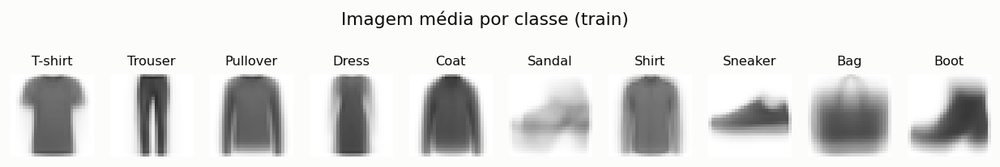

**Figura 1.** Imagem média por classe. Ficheiro `outputs/figures/eda_mean_images.png`. **Gerada em** `src/eda.py`, função `main()`, linha 55. **Cálculo:** média pixel a pixel das imagens de cada classe. **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.eda`.

In [8]:
fig('eda_mean_images.png')

### 1.2 Distâncias dentro de cada classe e entre classes

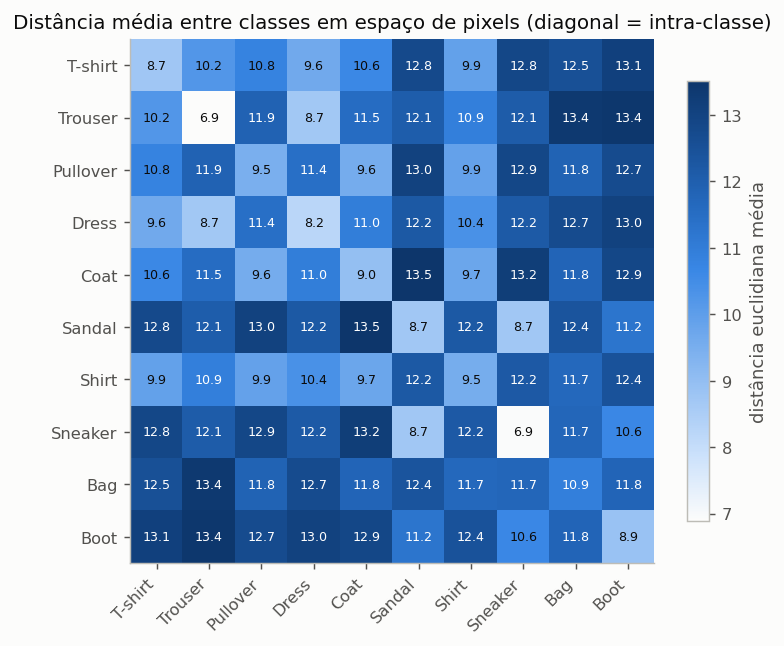

**Figura 2.** Matriz 10x10 de distâncias médias intra/inter-classe (pixels). Ficheiro `outputs/figures/eda_class_distances.png`. **Gerada em** `src/eda.py`, função `main()`, linha 68. **Cálculo:** média das distâncias euclidianas entre todos os pares de cada par de classes (`src/eda.py::class_distance_matrix`). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.eda`.

**Tabela 6.** EDA: distâncias intra/inter, confusão do kNN raw, pares mais confundidos, resumo. Ficheiro `outputs/metrics/eda_class_distances.csv`. **Escrita em** `src/eda.py`, função `main()`, linha 59. **Cálculo:** média das distâncias euclidianas entre todos os pares de cada par de classes (`src/eda.py::class_distance_matrix`). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.eda`.

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,8.73,10.22,10.77,9.64,10.63,12.78,9.89,12.85,12.51,13.09
Trouser,10.22,6.89,11.86,8.69,11.53,12.06,10.90,12.10,13.36,13.45
Pullover,10.77,11.86,9.47,11.43,9.57,13.03,9.88,12.87,11.84,12.69
Dress,9.64,8.69,11.43,8.22,10.95,12.22,10.37,12.16,12.69,13.04
Coat,10.63,11.53,9.57,10.95,8.96,13.52,9.74,13.19,11.80,12.86
Sandal,12.78,12.06,13.03,12.22,13.52,8.71,12.20,8.72,12.36,11.24
Shirt,9.89,10.90,9.88,10.37,9.74,12.20,9.53,12.17,11.66,12.43
Sneaker,12.85,12.10,12.87,12.16,13.19,8.72,12.17,6.91,11.73,10.64
Bag,12.51,13.36,11.84,12.69,11.80,12.36,11.66,11.73,10.92,11.80
Ankle boot,13.09,13.45,12.69,13.04,12.86,11.24,12.43,10.64,11.80,8.87


In [9]:
fig('eda_class_distances.png', width=560)
display(csv('eda_class_distances.csv', index_col=0).round(2))

### 1.3 kNN em pixels e classes mais confundidas

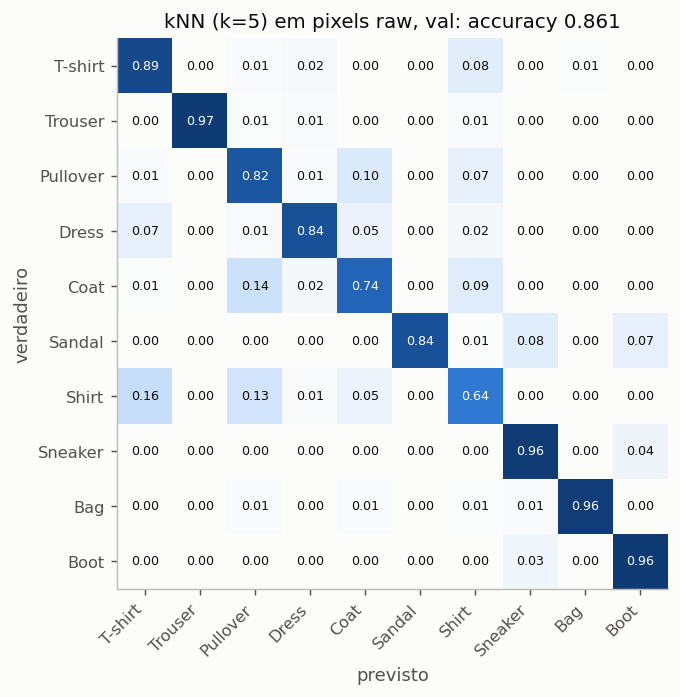

**Figura 3.** Matriz de confusão normalizada do kNN em pixels raw (val). Ficheiro `outputs/figures/eda_knn_raw_confusion.png`. **Gerada em** `src/eda.py`, função `main()`, linha 91. **Cálculo:** kNN k=5 em pixels (`src/evaluate.py::knn_predict`) e matriz de confusão normalizada (`src/evaluate.py::confusion`). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.eda`.

Resumo em `outputs/metrics/eda_summary.json` (`src/eda.py`, função `main()`, linha 107): accuracy 0.861; hipótese confirmada: True.

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
accuracy kNN raw (val),0.8883,0.9667,0.8167,0.8433,0.7367,0.84,0.64,0.96,0.9567,0.965


**Tabela 7.** EDA: distâncias intra/inter, confusão do kNN raw, pares mais confundidos, resumo. Ficheiro `outputs/metrics/eda_knn_raw_confusion.csv`. **Escrita em** `src/eda.py`, função `main()`, linha 74. **Cálculo:** contagens da confusão do kNN k=5 em pixels (`src/evaluate.py::confusion`). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.eda`.

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,533,0,5,10,1,0,47,1,3,0
Trouser,2,580,4,8,1,0,5,0,0,0
Pullover,7,0,490,5,59,0,39,0,0,0
Dress,39,1,8,506,32,0,12,0,2,0
Coat,3,0,87,14,442,0,53,0,1,0
Sandal,0,0,0,0,0,504,3,50,1,42
Shirt,97,0,79,8,30,0,384,0,2,0
Sneaker,0,0,0,0,0,0,0,576,0,24
Bag,2,1,7,1,6,0,4,5,574,0
Ankle boot,0,0,0,1,0,1,0,19,0,579


**Tabela 8.** EDA: distâncias intra/inter, confusão do kNN raw, pares mais confundidos, resumo. Ficheiro `outputs/metrics/eda_confused_pairs.csv`. **Escrita em** `src/eda.py`, função `main()`, linha 82. **Cálculo:** 10 pares de classes com mais confusões, somando as duas direções. **Dados:** eda_knn_raw_confusion.csv. **Refazer:** `python -m src.eda`.

,classe_a,classe_b,confusoes,ambas_tronco
0,Pullover,Coat,146,True
1,T-shirt/top,Shirt,144,True
2,Pullover,Shirt,118,True
3,Coat,Shirt,83,True
4,Sandal,Sneaker,50,False
5,T-shirt/top,Dress,49,False
6,Dress,Coat,46,False
7,Sneaker,Ankle boot,43,False
8,Sandal,Ankle boot,43,False
9,Dress,Shirt,20,False


In [10]:
fig('eda_knn_raw_confusion.png', width=560)
s = json.loads((MET / 'eda_summary.json').read_text())
MOSTRADAS['tabela']['outputs/metrics/eda_summary.json'] = 'resumo acima'
display(Markdown(f"Resumo em `outputs/metrics/eda_summary.json` (`src/eda.py`, função `main()`, linha {PROV.loc['outputs/metrics/eda_summary.json'].linha}): accuracy {s['knn_raw_val']['accuracy']:.3f}; hipótese confirmada: {s['hipotese_tronco_confirmada']}."))
display(pd.Series(s['acc_por_classe'], name='accuracy kNN raw (val)').to_frame().T)
display(csv('eda_knn_raw_confusion.csv', index_col=0))
csv('eda_confused_pairs.csv')

### 1.4 Interpretação

As imagens médias mostram que as classes de tronco (T-shirt, Pullover, Coat, Shirt) têm silhuetas médias muito parecidas: diferem sobretudo nas mangas e no comprimento, e Pullover/Coat/Shirt são quase indistinguíveis em média. Na matriz de distâncias, a distância intra-classe é sempre menor do que a inter-classe média, mas a margem é pequena para Shirt (intra 9.5 contra inter média 11.0), que é também a classe com distância inter-classe mais baixa: está "no meio" das outras classes de tronco.

O kNN (k=5) em pixels raw atinge 0.861 no val. **A hipótese confirma-se**: os 4 pares mais confundidos são todos entre classes de tronco (Pullover↔Coat 146, T-shirt↔Shirt 144, Pullover↔Shirt 118, Coat↔Shirt 83), e 61% de todos os erros são trocas entre estas quatro classes. Shirt é a pior classe (0.64), seguida de Coat (0.74) e Pullover (0.82). O 5.º par (Sandal↔Sneaker) mostra a segunda fonte de confusão, o calçado de perfil baixo.

<a id='fase-2'></a>

## Fase 2: PCA, LDA e dimensão intrínseca

**Método e código** (`src/pca_lda.py`; todos os modelos são ajustados só no train).
- **PCA completo** (`src/pca_lda.py::step_full`, `src/pca_lda.py::fit_pca`): solver `covariance_eigh`, exato e rápido com 54 000 × 784. Daqui saem a variância explicada e os limiares de 80/90/95/99%.
- **Reconstrução** (`src/pca_lda.py::step_reconstruction`, `src/pca_lda.py::recon_mse`): X̂ = (X − μ)WᵀW + μ, com W os k primeiros componentes; MSE por pixel em val e test.
- **Whitening** (`src/pca_lda.py::step_whitening`): para k ∈ {2, 8, 16, 32, 64, 128}, com e sem whitening, guarda o modelo em `outputs/pca/` e as projeções em `outputs/pca/proj/`; mede kNN k=5 no val.
- **Curva fina** (`src/pca_lda.py::step_knn_curve`): kNN em 21 valores de k; um k está saturado se ficar até 0.5 p.p. do máximo.
- **IncrementalPCA** (`src/pca_lda.py::step_ipca`): 128 componentes, `partial_fit` em blocos de 2048; comparado com o PCA exato pela variância, pelo MSE, pelo ângulo máximo entre subespaços e pelo kNN.
- **KernelPCA RBF** (`src/pca_lda.py::step_kpca`): 128 componentes em 10 000 pontos estratificados; γ = 1/mediana(‖xᵢ−xⱼ‖²) em 20 000 pares; solver aleatorizado.
- **LDA** (`src/pca_lda.py::step_lda`): solver SVD, 9 componentes, comparado com o PCA de 1 a 9 dimensões em kNN e regressão logística (`src/evaluate.py::logreg`: `StandardScaler` + `LogisticRegression`, C=1).
- **TwoNN** (`src/evaluate.py::twonn`, `src/pca_lda.py::step_twonn`): μ = r₂/r₁ (distâncias ao 2.º e ao 1.º vizinho, sem duplicados exatos). A dimensão é o declive, pela origem, de −log(1−F(μ)) em função de log(μ), sem os 10% de μ mais altos. Guarda-se também a estimativa de máxima verosimilhança (n−1)/Σlog μ.
- **Funções obrigatórias:** `src/representation.py::pca_project` e `src/representation.py::pca_reconstruct` usam estes modelos; `src/representation.py::load_pca` trunca o PCA completo se k estiver fora da grelha.

### 2.1 Variância explicada

**Tabela 9.** Variância explicada/acumulada e nº de componentes para 80/90/95/99%. Ficheiro `outputs/metrics/pca_components_thresholds.csv`. **Escrita em** `src/pca_lda.py`, função `step_full()`, linha 62. **Cálculo:** menor nº de componentes com variância acumulada ≥ 80/90/95/99%. **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.pca_lda`.

,limiar,n_componentes
0,0.80,24
1,0.90,84
2,0.95,188
3,0.99,459


**Tabela 10.** Variância explicada/acumulada e nº de componentes para 80/90/95/99%. Ficheiro `outputs/metrics/pca_explained_variance.csv`. **Escrita em** `src/pca_lda.py`, função `step_full()`, linha 60. **Cálculo:** `explained_variance_ratio_` do PCA completo e a sua soma acumulada. **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.pca_lda`.

,componente,variancia_explicada,variancia_acumulada
0,1,0.2899,0.2899
1,2,0.1777,0.4676
2,3,0.0603,0.5279
3,4,0.0494,0.5773
4,5,0.0386,0.6159
5,6,0.0345,0.6505
6,7,0.0235,0.6739
7,8,0.0191,0.6930
8,9,0.0136,0.7066
9,10,0.0132,0.7197


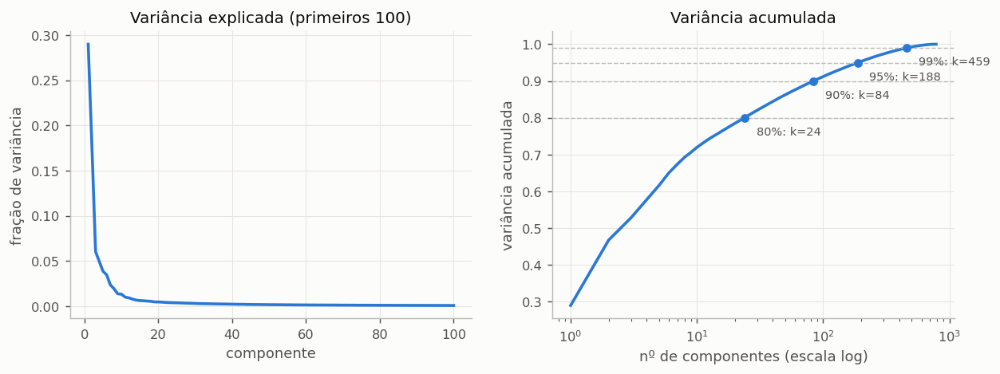

**Figura 4.** Variância explicada e acumulada do PCA. Ficheiro `outputs/figures/pca_variance.png`. **Gerada em** `src/pca_lda.py`, função `step_full()`, linha 80. **Cálculo:** `explained_variance_ratio_` do PCA completo e a sua soma acumulada. **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.pca_lda`.

In [11]:
display(csv('pca_components_thresholds.csv'))
ev = csv('pca_explained_variance.csv')
display(ev.head(10))
fig('pca_variance.png')

### 2.2 Erro de reconstrução e eigen-fashion

**Tabela 11.** MSE de reconstrução PCA (val/test) para k em {2,...,128}. Ficheiro `outputs/metrics/pca_reconstruction.csv`. **Escrita em** `src/pca_lda.py`, função `step_reconstruction()`, linha 97. **Cálculo:** MSE por pixel entre X e X reconstruído com k componentes (`src/pca_lda.py::recon_mse`). **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.pca_lda`.

,k,val_mse,test_mse
0,2,0.0459,0.0461
1,8,0.0264,0.0266
2,16,0.0203,0.0204
3,32,0.0150,0.0151
4,64,0.0102,0.0104
5,128,0.0062,0.0063


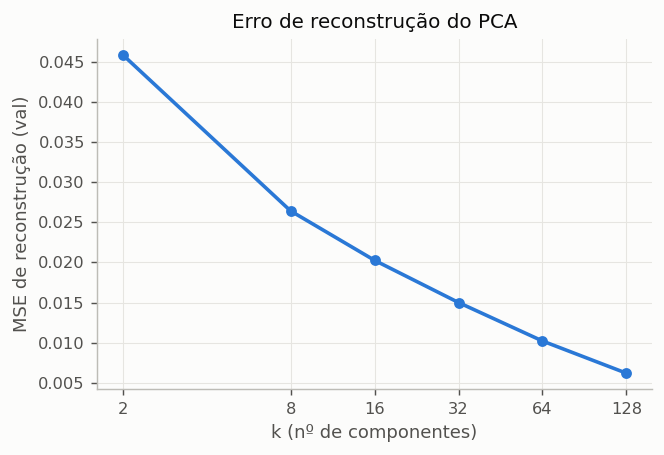

**Figura 5.** MSE de reconstrução do PCA em função de k. Ficheiro `outputs/figures/pca_reconstruction_mse.png`. **Gerada em** `src/pca_lda.py`, função `step_reconstruction()`, linha 129. **Cálculo:** MSE de reconstrução por k (`src/pca_lda.py::recon_mse`). **Dados:** `outputs/metrics/pca_reconstruction.csv` (calculado em `src/pca_lda.py`, `step_reconstruction()`, linha 97). **Refazer:** `python -m src.pca_lda`.

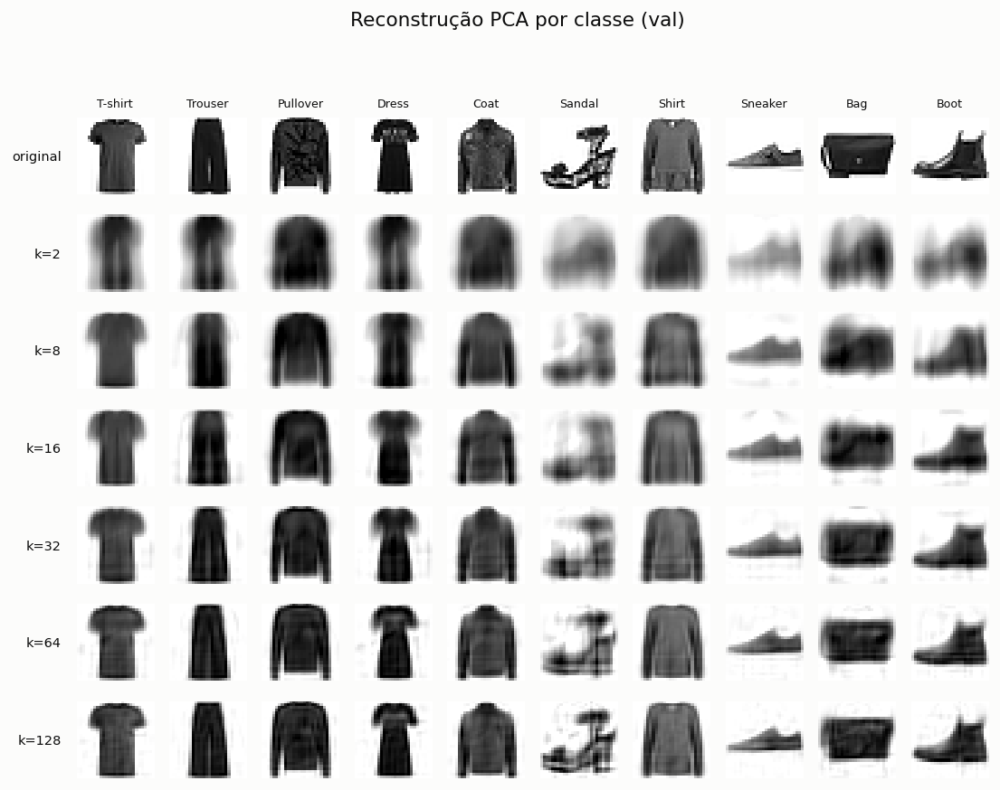

**Figura 6.** Painel de reconstruções PCA por classe para vários k. Ficheiro `outputs/figures/pca_reconstructions.png`. **Gerada em** `src/pca_lda.py`, função `step_reconstruction()`, linha 109. **Cálculo:** reconstruções por classe para cada k (`src/pca_lda.py::recon_mse`). **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.pca_lda`.

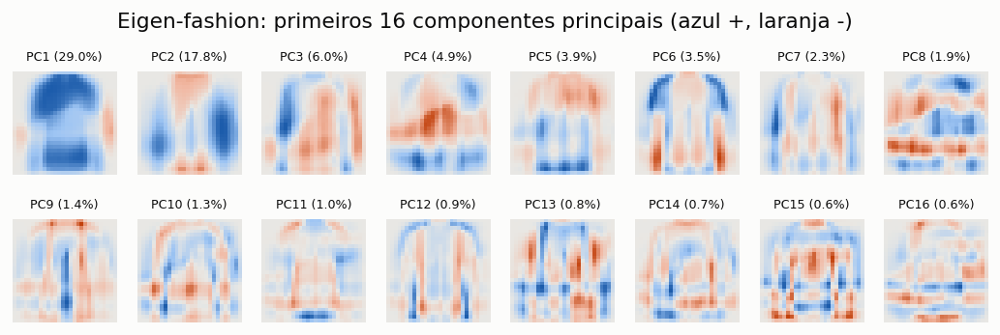

**Figura 7.** Primeiros componentes principais como imagens. Ficheiro `outputs/figures/pca_eigenfashion.png`. **Gerada em** `src/pca_lda.py`, função `step_reconstruction()`, linha 120. **Cálculo:** primeiros vetores de `components_` mostrados como imagens 28×28. **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.pca_lda`.

In [12]:
display(csv('pca_reconstruction.csv'))
fig('pca_reconstruction_mse.png', width=480)
fig('pca_reconstructions.png')
fig('pca_eigenfashion.png')

### 2.3 PCA com e sem whitening

**Tabela 12.** Accuracy kNN (k=5, val) do PCA com e sem whitening por k. Ficheiro `outputs/metrics/pca_knn_whitening.csv`. **Escrita em** `src/pca_lda.py`, função `step_whitening()`, linha 158. **Cálculo:** kNN k=5 no espaço PCA, train → val (`src/evaluate.py::knn_predict`, `src/evaluate.py::cls_metrics`). **Dados:** `outputs/pca/proj/pca_k*_{train,val}.npy` (calculado em `src/pca_lda.py`, `step_whitening()`, linha 150). **Refazer:** `python -m src.pca_lda`.

whiten,sem whitening,com whitening
k,,
2,0.5252,0.5255
8,0.7957,0.7960
16,0.8473,0.8498
32,0.8672,0.8683
64,0.8733,0.8665
128,0.8717,0.8577


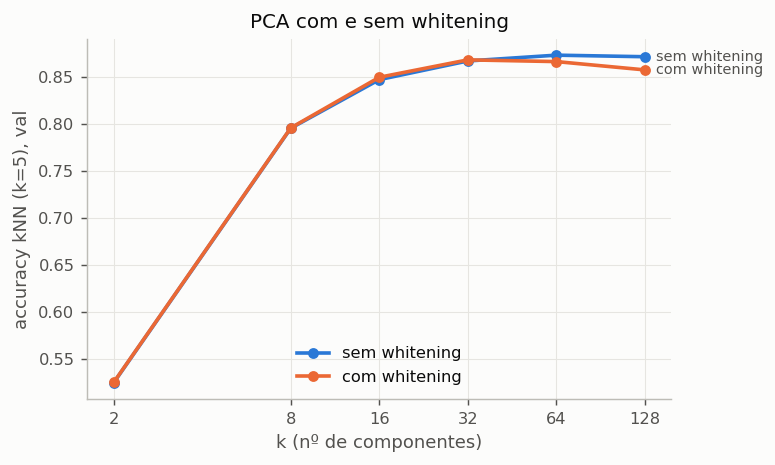

**Figura 8.** Accuracy kNN (val) do PCA com e sem whitening. Ficheiro `outputs/figures/pca_knn_whitening.png`. **Gerada em** `src/pca_lda.py`, função `step_whitening()`, linha 172. **Cálculo:** accuracy kNN por k, com e sem whitening. **Dados:** `outputs/metrics/pca_knn_whitening.csv` (calculado em `src/pca_lda.py`, `step_whitening()`, linha 158). **Refazer:** `python -m src.pca_lda`.

**Tabela 13.** Curva fina de accuracy kNN (val) vs nº de componentes PCA. Ficheiro `outputs/metrics/pca_knn_curve.csv`. **Escrita em** `src/pca_lda.py`, função `step_knn_curve()`, linha 192. **Cálculo:** kNN k=5 em 21 valores de k; saturado = até 0.5 p.p. do máximo. **Dados:** `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.pca_lda`.

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
k,1,2,3,4,6,8,10,12,16,20,...,32,40,48,64,96,128,187,256,400,784
knn_val_acc,0.24,0.5252,0.6337,0.7078,0.7677,0.7957,0.8208,0.8363,0.8473,0.8555,...,0.8672,0.869,0.869,0.8733,0.8713,0.8717,0.8717,0.8687,0.8652,0.8613
saturado,False,False,False,False,False,False,False,False,False,False,...,False,True,True,True,True,True,True,True,False,False


In [13]:
w = csv('pca_knn_whitening.csv')
display(w.pivot(index='k', columns='whiten', values='knn_val_acc').rename(columns={False: 'sem whitening', True: 'com whitening'}))
fig('pca_knn_whitening.png', width=520)
c = csv('pca_knn_curve.csv'); display(c.T)

### 2.4 IncrementalPCA e KernelPCA

In [14]:
display(csv('ipca_vs_pca.csv'))
display(csv('kpca_knn.csv'))

**Tabela 14.** Comparação IncrementalPCA vs PCA (variância, MSE, ângulos entre subespaços, kNN, tempo). Ficheiro `outputs/metrics/ipca_vs_pca.csv`. **Escrita em** `src/pca_lda.py`, função `step_ipca()`, linha 288. **Cálculo:** variância, MSE, ângulo entre subespaços (`subspace_angles`) e kNN, IPCA vs PCA. **Dados:** `outputs/pca/ipca_k128.joblib` (calculado em `src/pca_lda.py`, `step_ipca()`, linha 270), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.pca_lda`.

,k,ipca_var_acum,pca_var_acum,ipca_val_mse,pca_val_mse,angulo_max_graus,ipca_knn_val_acc,tempo_ipca_s,tempo_pca_s
0,2,0.4676,0.4676,0.0459,0.0459,0.0173,0.5252,98.0451,1.66
1,8,0.6930,0.6930,0.0264,0.0264,0.0190,0.7957,98.0451,1.66
2,16,0.7651,0.7651,0.0203,0.0203,0.0544,0.8473,98.0451,1.66
3,32,0.8260,0.8260,0.0150,0.0150,0.2007,0.8672,98.0451,1.66
4,64,0.8811,0.8811,0.0102,0.0102,1.4051,0.8733,98.0451,1.66
5,128,0.9272,0.9279,0.0062,0.0062,72.3832,0.8713,98.0451,1.66


**Tabela 15.** Accuracy kNN (val) do KernelPCA RBF por nº de componentes. Ficheiro `outputs/metrics/kpca_knn.csv`. **Escrita em** `src/pca_lda.py`, função `step_kpca()`, linha 328. **Cálculo:** kNN k=5 no espaço KernelPCA, train → val. **Dados:** `outputs/pca/proj/kpca_rbf_k128_{train,val}.npy` (calculado em `src/pca_lda.py`, `step_kpca()`, linha 321). **Refazer:** `python -m src.pca_lda`.

,k,kpca_knn_val_acc,gamma,subset,tempo_fit_s
0,2,0.5120,0.0076,10000,16.9727
1,8,0.7895,0.0076,10000,16.9727
2,16,0.8325,0.0076,10000,16.9727
3,32,0.8630,0.0076,10000,16.9727
4,64,0.8702,0.0076,10000,16.9727
5,128,0.8732,0.0076,10000,16.9727


### 2.5 LDA contra PCA

**Tabela 16.** LDA vs PCA em kNN/LogReg; variância discriminante. Ficheiro `outputs/metrics/lda_vs_pca.csv`. **Escrita em** `src/pca_lda.py`, função `step_lda()`, linha 358. **Cálculo:** kNN k=5 e LogReg (`src/evaluate.py::logreg`) com 1 a 9 dimensões, LDA vs PCA. **Dados:** `outputs/lda/lda_*.npy` (calculado em `src/pca_lda.py`, `step_lda()`, linha 347), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.pca_lda`.

knn_val_acc         logreg_val_acc        
metodo         LDA     PCA            LDA     PCA
dim                                              
1           0.4342  0.2460         0.4815  0.2727
2           0.5628  0.5252         0.6010  0.5195
3           0.6547  0.6338         0.6825  0.6210
4           0.6937  0.7078         0.7148  0.6827
5           0.7522  0.7430         0.7552  0.7125
6           0.7877  0.7677         0.7857  0.7230
7           0.7935  0.7873         0.7957  0.7288
8           0.8238  0.7957         0.8273  0.7407
9           0.8355  0.8112         0.8410  0.7625

**Tabela 17.** LDA vs PCA em kNN/LogReg; variância discriminante. Ficheiro `outputs/metrics/lda_explained_variance.csv`. **Escrita em** `src/pca_lda.py`, função `step_lda()`, linha 360. **Cálculo:** `explained_variance_ratio_` do LDA. **Dados:** `outputs/lda/lda.joblib` (calculado em `src/pca_lda.py`, `step_lda()`, linha 345). **Refazer:** `python -m src.pca_lda`.

,0,1,2,3,4,5,6,7,8
componente,1.0000,2.0000,3.000,4.0000,5.000,6.000,7.0000,8.0000,9.0000
variancia_explicada_lda,0.4458,0.2197,0.093,0.0739,0.061,0.043,0.0377,0.0162,0.0097


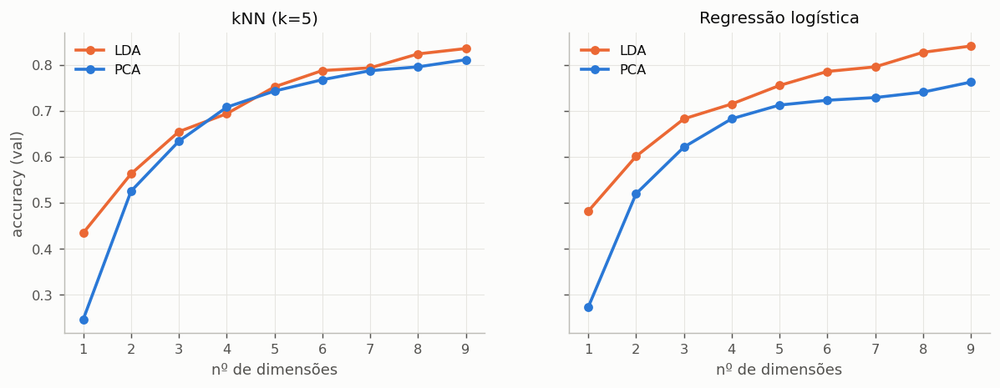

**Figura 9.** LDA vs PCA (1 a 9 dimensões) em kNN e regressão logística. Ficheiro `outputs/figures/lda_vs_pca.png`. **Gerada em** `src/pca_lda.py`, função `step_lda()`, linha 372. **Cálculo:** accuracy kNN e LogReg por dimensão, LDA vs PCA. **Dados:** `outputs/metrics/lda_vs_pca.csv` (calculado em `src/pca_lda.py`, `step_lda()`, linha 358). **Refazer:** `python -m src.pca_lda`.

In [15]:
l = csv('lda_vs_pca.csv')
display(l.pivot(index='dim', columns='metodo', values=['knn_val_acc', 'logreg_val_acc']))
display(csv('lda_explained_variance.csv').T)
fig('lda_vs_pca.png')

### 2.6 Dimensão intrínseca (TwoNN)

**Tabela 18.** Dimensão intrínseca TwoNN (ajuste e MLE) global e por classe; k de saturação do kNN-PCA. Ficheiro `outputs/metrics/twonn.csv`. **Escrita em** `src/pca_lda.py`, função `step_twonn()`, linha 390. **Cálculo:** TwoNN global e por classe (`src/evaluate.py::twonn`, Facco et al. 2017); k de saturação de `pca_knn_curve.csv`. **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/metrics/pca_knn_curve.csv` (calculado em `src/pca_lda.py`, `step_knn_curve()`, linha 192). **Refazer:** `python -m src.pca_lda`.

,conjunto,id_twonn,id_mle,n_used,n_duplicates,k_saturacao_knn_pca
0,GLOBAL (train),15.6622,14.2183,54000,0,40
1,T-shirt/top,15.8377,14.1327,5400,0,40
2,Trouser,12.7078,12.2177,5400,0,40
3,Pullover,14.6605,13.9434,5400,0,40
4,Dress,15.4306,14.5008,5400,0,40
5,Coat,15.2121,13.5580,5400,0,40
6,Sandal,13.1678,11.9100,5400,0,40
7,Shirt,16.4328,14.5581,5400,0,40
8,Sneaker,16.3713,14.8118,5400,0,40
9,Bag,15.9243,13.7179,5400,0,40


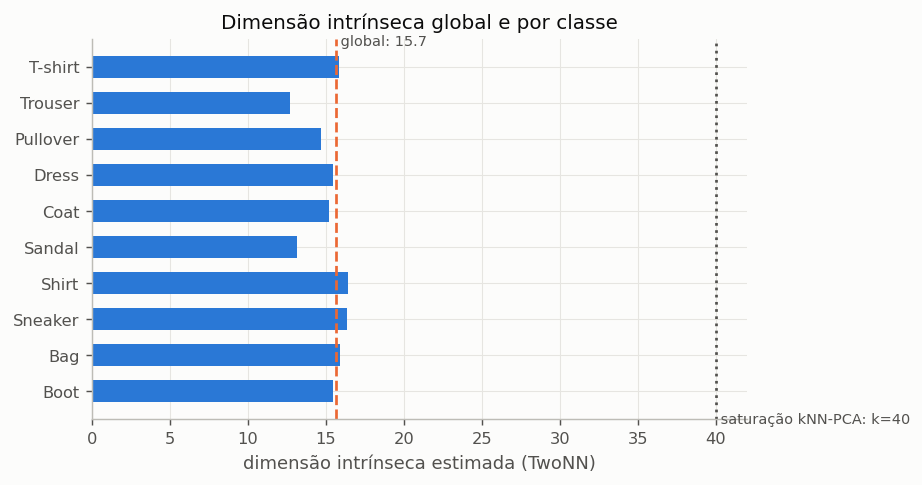

**Figura 10.** Dimensão intrínseca TwoNN global e por classe vs k de saturação. Ficheiro `outputs/figures/twonn.png`. **Gerada em** `src/pca_lda.py`, função `step_twonn()`, linha 401. **Cálculo:** dimensão intrínseca TwoNN por classe vs k de saturação. **Dados:** `outputs/metrics/twonn.csv` (calculado em `src/pca_lda.py`, `step_twonn()`, linha 390). **Refazer:** `python -m src.pca_lda`.

In [16]:
display(csv('twonn.csv'))
fig('twonn.png', width=560)

### 2.7 Interpretação

- **Variância:** a distribuição é muito concentrada no início (PC1 29%, PC2 18%) e tem uma cauda longa: bastam 24 componentes para 80%, mas são precisos 188 para 95% e 459 para 99%. Os primeiros componentes (eigen-fashion) codificam aproximadamente a forma global: PC1 mede a quantidade de "tecido" na região de uma peça de tronco, PC2 contrapõe formas estreitas e verticais (calças, vestidos) a peças largas com mangas, e os seguintes contrapõem mangas, a faixa inferior do calçado e malas. A partir do PC10, aproximadamente, aparecem padrões de alta frequência (texturas, riscas).
- **Reconstrução:** o MSE cai rapidamente até k≈32 (0.015) e depois devagar (0.006 em k=128). Visualmente, com k=8 já se reconhece a classe, mas a Sandal (estrutura fina, muitas tiras) e os padrões de textura só aparecem com k ≥ 64.
- **Saturação vs dimensão intrínseca:** a accuracy do kNN satura em **k≈40** (máximo 0.873 em k=64) e desce ligeiramente com mais componentes (0.861 com os 784, igual aos pixels): os componentes de baixa variância são sobretudo ruído para a métrica euclidiana. O TwoNN estima uma dimensão intrínseca de **cerca de 16** (12.7 em Trouser a 16.4 em Shirt), muito abaixo do k de saturação: a variedade onde as imagens vivem tem poucas dimensões, mas é curva, e um subespaço linear precisa de cerca de 2.5× mais dimensões para a conter. É o argumento para métodos não lineares (KernelPCA, AEs).
- **Whitening:** só ajuda (pouco) até k=32. Em k ≥ 64 piora o kNN (0.873 → 0.867 em k=64 e 0.872 → 0.858 em k=128), porque dar a mesma escala a componentes de baixa variância amplifica o ruído. Para a regressão logística com standardização é indiferente (é só uma escala por componente).
- **IncrementalPCA:** reproduz o PCA exato (mesma variância acumulada, mesmo MSE e mesmo kNN até k=64) com memória limitada a um batch, à custa de ser cerca de 60× mais lento aqui. O ângulo máximo de 72° em k=128 não é erro: os componentes perto da posição 120–130 têm valores próprios quase iguais, por isso a "fronteira" do subespaço de dimensão 128 é instável; os primeiros 64 coincidem (≤ 1.4°).
- **KernelPCA RBF:** com 10k pontos de ajuste chega ao mesmo máximo que o PCA (0.873 com 128 componentes), mas não o ultrapassa e precisa de mais componentes para chegar lá; o ganho não linear é anulado pelo custo (kernel 10k×10k, projeção de cada ponto contra 10k).
- **LDA:** com o mesmo número de dimensões, supera claramente o PCA (9 dims: LogReg 0.841 contra 0.763; kNN 0.836 contra 0.811), porque usa as labels para escolher direções discriminantes. Mas está limitada a 9 dimensões e o PCA-64 acaba por ultrapassá-la no kNN (0.873).

<a id='fase-3'></a>

## Fase 3: Mapas 2D com t-SNE e UMAP

**Método e código** (`src/viz_nonlinear.py`).
- **Entradas** (`src/viz_nonlinear.py::inputs`): os 10 000 pontos de `outputs/splits/viz10k_idx.npy`, em pixels, em PCA-50 e no latente do ConvAE d=32.
- **t-SNE** (`src/viz_nonlinear.py::run_tsne`): perplexity 5, 30 e 50; `init="pca"`, `learning_rate="auto"`, 1000 iterações, seed 42.
- **UMAP** (`src/viz_nonlinear.py::run_umap`): n_neighbors 5, 15 e 50; min_dist 0.1; seed 42; não supervisionado.
- **Qualidade** (`src/evaluate.py::embedding_quality`), com k=10 e relativa ao espaço de entrada:
  - *trustworthiness* T = 1 − 2/(nk(2n−3k−1)) · Σᵢ Σⱼ (r(i,j) − k), somando os vizinhos no mapa 2D que não o eram na entrada; penaliza vizinhos falsos;
  - *continuity* C é a mesma fórmula com os papéis trocados; penaliza vizinhos perdidos;
  - *preservação kNN* é a fração média de vizinhos partilhados entre a entrada e o mapa;
  - *knn_acc_2d_loo* é a accuracy do kNN k=5 no próprio mapa, leave-one-out (`src/evaluate.py::knn_predict`). É a única medida que usa labels.
- **Figuras:** `src/viz_nonlinear.py::main` e, na adenda, `src/viz_nonlinear.py::specialized_figures`. Os desenhos usam `src/plots.py::scatter_classes`.

### 3.1 Qualidade dos mapas

In [17]:
q = csv('viz_quality.csv')
display(q.sort_values(['entrada', 'metodo', 'param']).reset_index(drop=True))

**Tabela 19.** Trustworthiness, continuity, preservação kNN (k=10) e accuracy kNN 2D (leave-one-out) de cada embedding t-SNE/UMAP. Ficheiro `outputs/metrics/viz_quality.csv`. **Escrita em** `src/viz_nonlinear.py`, função `main()`, linha 86. **Cálculo:** trustworthiness, continuity e preservação kNN com k=10 (`src/evaluate.py::embedding_quality`); kNN 2D leave-one-out. **Dados:** `outputs/viz/{tsne,umap}_*.npy` (calculado em `src/embeddings_viz.py`, `embed2d()`, linha 154) e a entrada de cada um. **Refazer:** `python -m src.viz_nonlinear`.

,entrada,metodo,param,trustworthiness,continuity,knn_preservation,knn_acc_2d_loo
0,conv_ae_d16,umap,5,0.9863,0.9872,0.3302,0.8067
1,conv_ae_d16,umap,15,0.9831,0.9896,0.2826,0.7900
2,conv_ae_d16,umap,50,0.9805,0.9900,0.2328,0.7843
3,conv_ae_d32,tsne,5,0.9923,0.9831,0.4145,0.8401
4,conv_ae_d32,tsne,30,0.9938,0.9863,0.4478,0.8466
5,conv_ae_d32,tsne,50,0.9935,0.9868,0.4328,0.8397
6,conv_ae_d32,umap,5,0.9837,0.9875,0.3116,0.8163
7,conv_ae_d32,umap,15,0.9803,0.9894,0.2705,0.8112
8,conv_ae_d32,umap,50,0.9773,0.9893,0.2238,0.7955
9,conv_ae_d64,umap,5,0.9811,0.9862,0.2936,0.8077


### 3.2 Mapas de pixels, PCA-50 e ConvAE

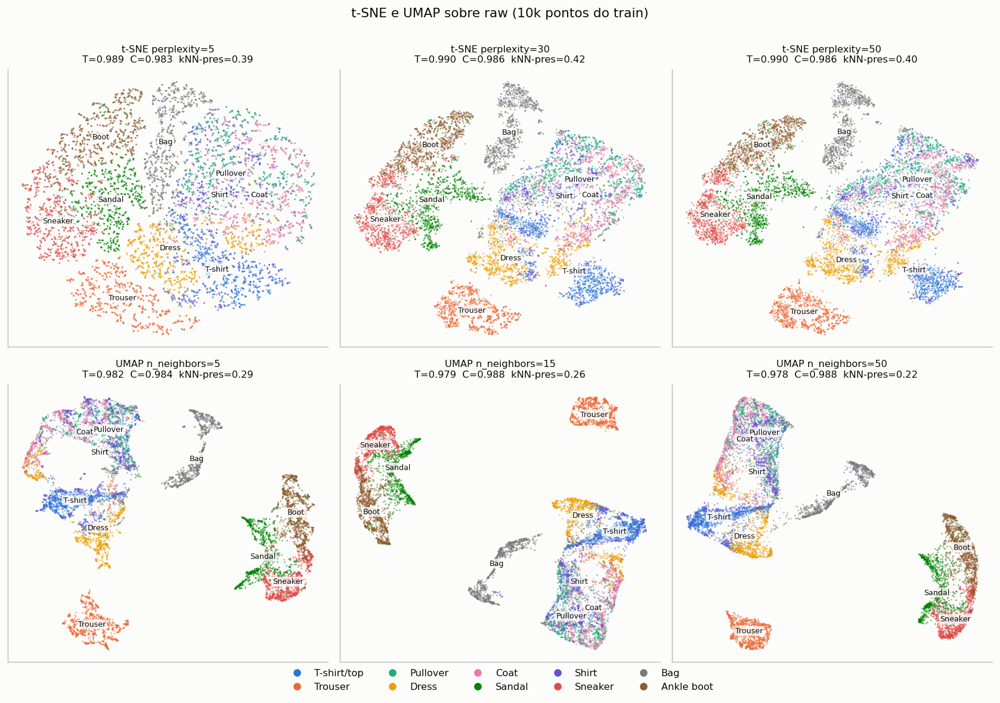

**Figura 11.** Grelha t-SNE/UMAP sobre raw. Ficheiro `outputs/figures/viz_raw.png`. **Gerada em** `src/viz_nonlinear.py`, função `main()`, linha 108. **Cálculo:** grelha t-SNE (perplexity) e UMAP (n_neighbors) de uma entrada, com T, C e preservação kNN no título. **Dados:** `outputs/viz/{tsne,umap}_*.npy` (calculado em `src/embeddings_viz.py`, `embed2d()`, linha 154), `outputs/metrics/viz_quality.csv` (calculado em `src/viz_nonlinear.py`, `main()`, linha 86). **Refazer:** `python -m src.viz_nonlinear`.

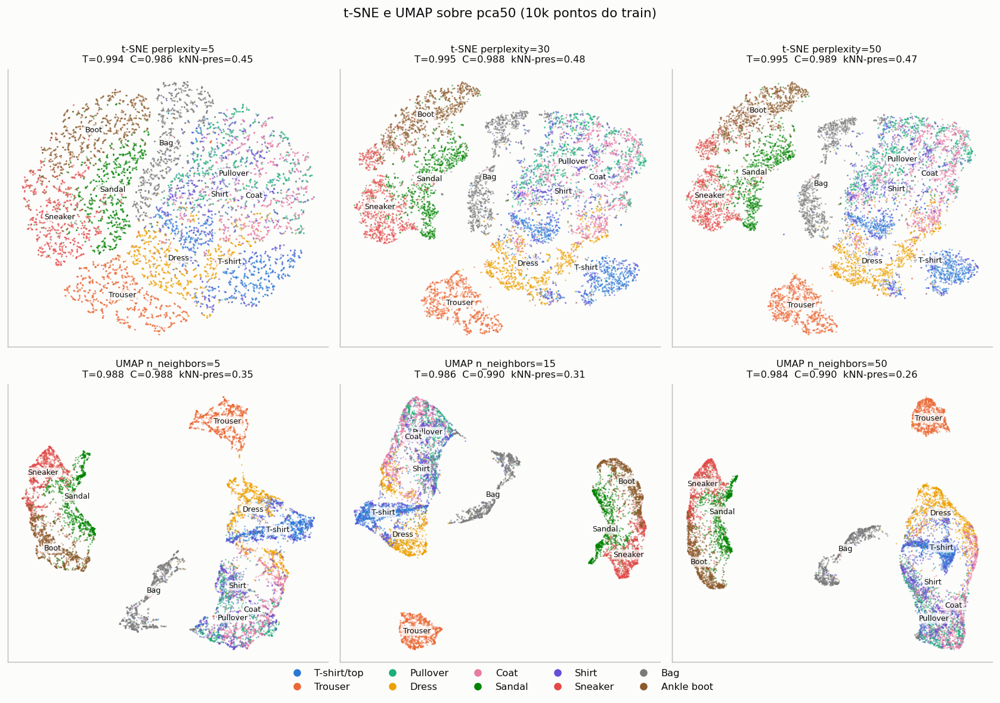

**Figura 12.** Grelha t-SNE/UMAP sobre pca50. Ficheiro `outputs/figures/viz_pca50.png`. **Gerada em** `src/viz_nonlinear.py`, função `main()`, linha 108. **Cálculo:** grelha t-SNE (perplexity) e UMAP (n_neighbors) de uma entrada, com T, C e preservação kNN no título. **Dados:** `outputs/viz/{tsne,umap}_*.npy` (calculado em `src/embeddings_viz.py`, `embed2d()`, linha 154), `outputs/metrics/viz_quality.csv` (calculado em `src/viz_nonlinear.py`, `main()`, linha 86). **Refazer:** `python -m src.viz_nonlinear`.

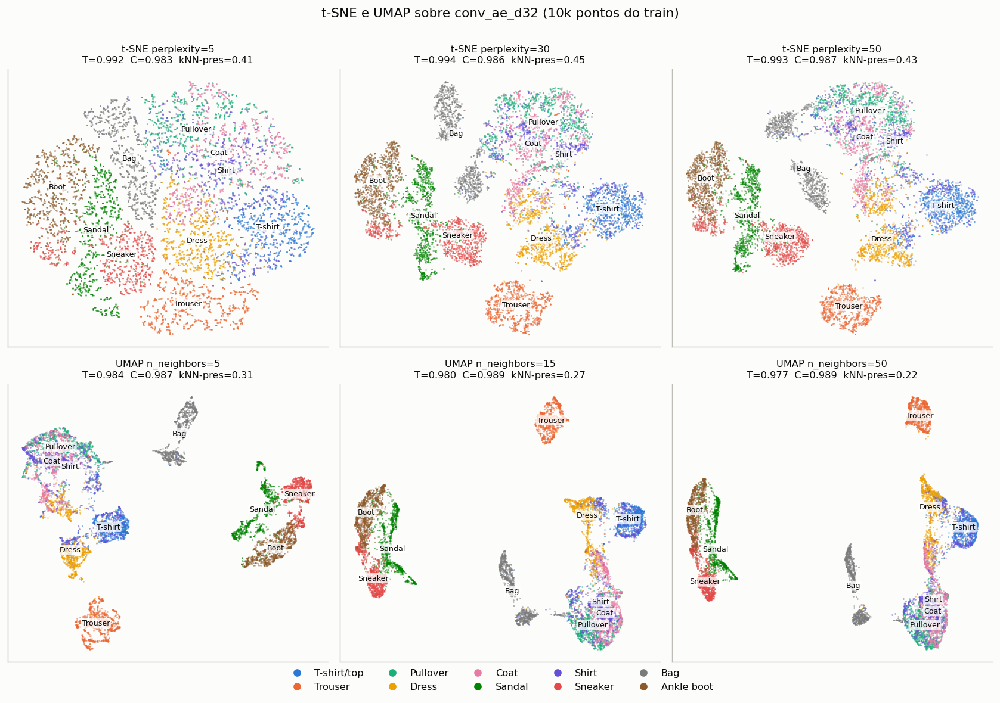

**Figura 13.** Grelha t-SNE/UMAP sobre conv_ae_d32. Ficheiro `outputs/figures/viz_conv_ae_d32.png`. **Gerada em** `src/viz_nonlinear.py`, função `main()`, linha 108. **Cálculo:** grelha t-SNE (perplexity) e UMAP (n_neighbors) de uma entrada, com T, C e preservação kNN no título. **Dados:** `outputs/viz/{tsne,umap}_*.npy` (calculado em `src/embeddings_viz.py`, `embed2d()`, linha 154), `outputs/metrics/viz_quality.csv` (calculado em `src/viz_nonlinear.py`, `main()`, linha 86). **Refazer:** `python -m src.viz_nonlinear`.

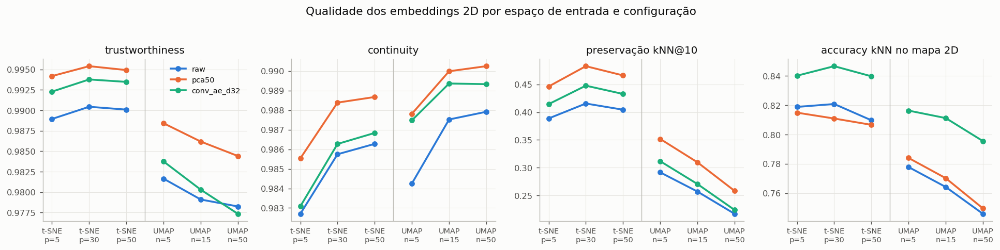

**Figura 14.** Resumo das métricas de qualidade dos embeddings 2D. Ficheiro `outputs/figures/viz_quality.png`. **Gerada em** `src/viz_nonlinear.py`, função `main()`, linha 125. **Cálculo:** resumo das métricas de qualidade por método e parâmetro. **Dados:** `outputs/metrics/viz_quality.csv` (calculado em `src/viz_nonlinear.py`, `main()`, linha 86). **Refazer:** `python -m src.viz_nonlinear`.

In [18]:
for n in ('viz_raw.png', 'viz_pca50.png', 'viz_conv_ae_d32.png', 'viz_quality.png'):
    fig(n)

### 3.3 Mapas dos latentes do VAE e do DAE

continuity                 knn_acc_2d_loo                 knn_preservation                 trustworthiness                
param                5       15      50             5       15      50               5       15      50              5       15      50
entrada                                                                                                                                
conv_ae_d16      0.9872  0.9896  0.9900         0.8067  0.7900  0.7843           0.3302  0.2826  0.2328          0.9863  0.9831  0.9805
vae_conv_d16     0.9829  0.9863  0.9867         0.7836  0.7800  0.7737           0.3578  0.3033  0.2574          0.9809  0.9715  0.9687
dae_conv_d16     0.9868  0.9886  0.9894         0.7810  0.7774  0.7603           0.3434  0.2954  0.2470          0.9860  0.9833  0.9808
conv_ae_d64      0.9862  0.9880  0.9881         0.8077  0.7955  0.7825           0.2936  0.2569  0.2120          0.9811  0.9774  0.9728
vae_conv_d64     0.9831  0.9862  0.9865         0.7862  0.7776  0.7700           0.3644  0.3140  0.2572          0.9797  0.9739  0.9698
dae_conv_d64     0.9843  0.9872  0.9878         0.7981  0.7807  0.7706           0.3185  0.2736  0.2280          0.9771  0.9715  0.9671

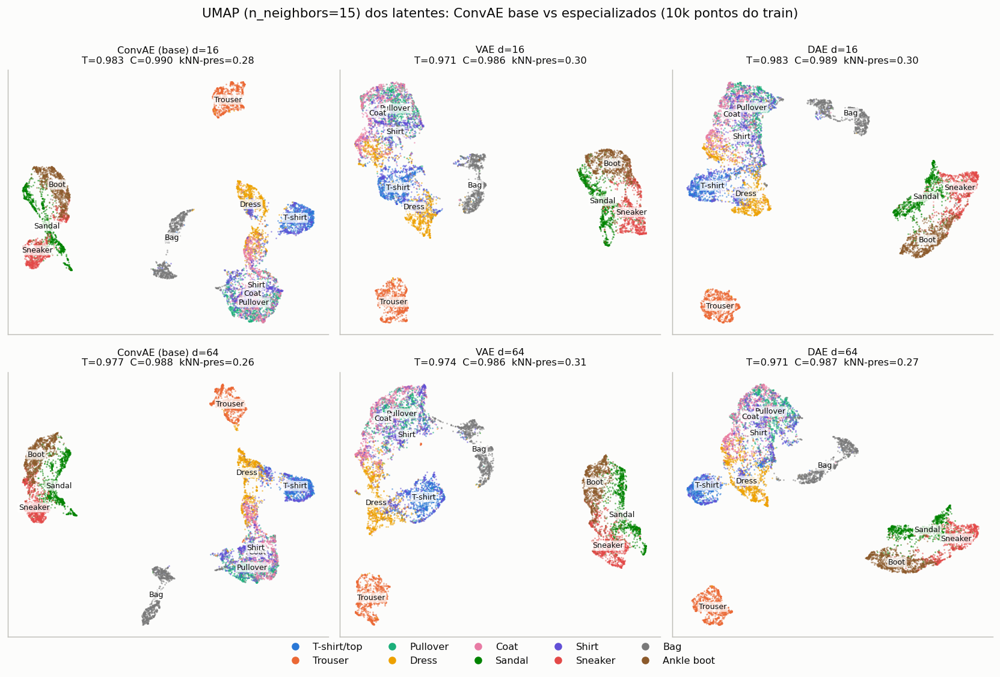

**Figura 15.** UMAP dos latentes ConvAE/VAE/DAE com d=16 e d=64. Ficheiro `outputs/figures/viz_specialized.png`. **Gerada em** `src/viz_nonlinear.py`, função `specialized_figures()`, linha 155. **Cálculo:** UMAP (n_neighbors=15) dos latentes com d=16 e d=64. **Dados:** `outputs/viz/umap_{conv_ae,vae_conv,dae_conv}_d{16,64}_n15.npy` (calculado em `src/viz_nonlinear.py`, `main()`, linha 75). **Refazer:** `python -m src.viz_nonlinear`.

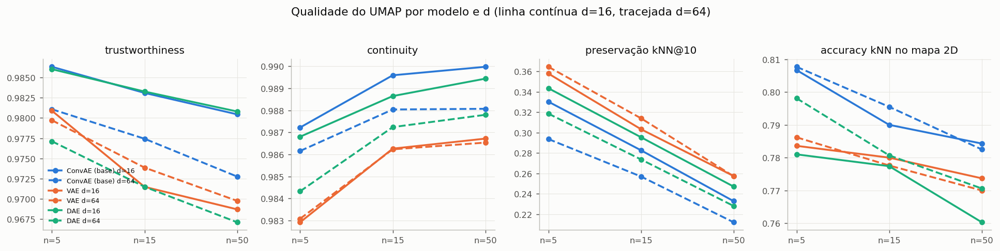

**Figura 16.** Métricas de qualidade do UMAP para ConvAE/VAE/DAE vs n_neighbors. Ficheiro `outputs/figures/viz_quality_specialized.png`. **Gerada em** `src/viz_nonlinear.py`, função `specialized_figures()`, linha 169. **Cálculo:** T, C e preservação kNN do UMAP por n_neighbors, ConvAE vs VAE vs DAE. **Dados:** `outputs/metrics/viz_quality.csv` (calculado em `src/viz_nonlinear.py`, `main()`, linha 86). **Refazer:** `python -m src.viz_nonlinear`.

In [19]:
esp = ['conv_ae_d16', 'vae_conv_d16', 'dae_conv_d16', 'conv_ae_d64', 'vae_conv_d64', 'dae_conv_d64']
qe = q[q.entrada.isin(esp) & (q.metodo == 'umap')]
display(qe.pivot_table(index=['entrada'], columns='param',
                       values=['trustworthiness', 'continuity', 'knn_preservation', 'knn_acc_2d_loo']).reindex(esp))
fig('viz_specialized.png')
fig('viz_quality_specialized.png')

### 3.4 Interpretação

- **t-SNE vs UMAP:** o t-SNE tem trustworthiness mais alta (0.989–0.995) e preserva mais vizinhos exatos (preservação kNN@10 até 0.48): é o melhor a manter a estrutura **local**. O UMAP tem continuity ligeiramente maior, sobretudo com n_neighbors alto (até 0.990), e produz grupos mais compactos e separados: dá mais peso à estrutura **global**, à custa da vizinhança fina (preservação kNN 0.22–0.35, a descer com n_neighbors). Perplexity 30 é o melhor compromisso no t-SNE; no UMAP, n_neighbors=5 maximiza a trustworthiness e 50 a continuity.
- **Espaço de entrada:** partir do PCA-50 melhora todas as métricas de preservação face aos pixels (remove ruído de baixa variância que distorce as vizinhanças). Partir do latente do ConvAE (d=32) dá mapas com **melhor separação de classes** (accuracy kNN no mapa 2D 0.84–0.85 contra 0.81–0.82), embora preserve um pouco menos as vizinhanças do espaço de entrada (que é diferente em cada caso: o AE já agrupou as imagens de outra forma).
- **Estrutura de classes:** em todos os mapas, Trouser, Bag e o grupo do calçado (Sandal, Sneaker, Ankle boot) formam ilhas bem separadas; T-shirt e Dress ficam juntos mas distinguíveis; Pullover, Coat e Shirt formam uma única região contínua e misturada, exatamente as confusões vistas na EDA. Nenhum método não supervisionado "resolve" esta região: a informação que separa estas classes (golas, fechos, botões) é fina e pouco saliente em pixels.
- **Adenda (VAE e DAE, d=16 e 64, UMAP):** a qualidade do mapa quase não depende do objetivo de treino: trustworthiness 0.97–0.99 e continuity 0.98–0.99 nos três modelos. O VAE tem trustworthiness um pouco mais baixa com n_neighbors ≥ 15 (0.97 contra 0.98 no d=16) e a preservação kNN mais alta (0.26–0.36 contra 0.21–0.33 no ConvAE), provavelmente porque usa poucas dimensões efetivas (ver 4.4). A accuracy kNN no mapa 2D favorece ligeiramente o ConvAE (0.78–0.81, contra 0.77–0.79 no VAE e 0.76–0.80 no DAE). A estrutura é a mesma: Trouser, Bag e calçado em ilhas, classes de tronco numa região contínua.

<a id='fase-4'></a>

## Fase 4: Autoencoders

**Método e código.**

Arquiteturas em `src/models.py`, construídas por `src/models.py::build_ae`. Nenhuma tem skip connections: o latente de dimensão d é a única via entre encoder e decoder.

| Modelo | Encoder | Decoder | Classe |
|---|---|---|---|
| DenseAE | 784 → 512 → 256 → d, com ReLU | d → 256 → 512 → 784, com sigmoide | `src/models.py::DenseAE` |
| ConvAE | Conv 3×3 com BatchNorm e ReLU: 1→32 (stride 2), 32→64 (stride 2), 64→64; Linear 3136 → d | Linear d → 3136; Conv 64→64; ConvTranspose 64→32 e 32→16; Conv 16→1; sigmoide | `src/models.py::ConvAE` |
| TransformerAE | patches 4×4 → 49 tokens, Linear 16 → 128, posições aprendidas, 4 blocos pre-LN (4 cabeças, MLP 256, GELU, sem dropout), pooling por atenção com query aprendida, Linear 128 → d | Linear d → 128, replicado pelos 49 tokens com posições próprias, 4 blocos, Linear 128 → 16 por patch, sigmoide | `src/models.py::TransformerAE` |

**Protocolo igual para todos** (`src/train_ae.py::fit`, parâmetros em `config.yaml`, secção `ae`):

| Parâmetro | Valor |
|---|---|
| Loss | MSE por pixel |
| Otimizador | AdamW, LR 1e-3, weight decay 0 |
| Warm-up do LR | linear, 500 passos |
| Batch / épocas | 256 / máximo 60 |
| Early stopping | patience 8 no MSE de validação, min_delta 1e-6 |
| Redução do LR | ×0.5 após 3 épocas sem melhorar |
| Precisão / seed | fp32, sem AMP / 42 |

- **Treino:** `src/train_ae.py::train_one` treina um modelo; `src/train_ae.py::grid` lança a grelha em subprocessos, 2 em paralelo; `src/train_ae.py::collect` junta as métricas. Em cada época, `fit` grava `last.pt`, `best.pt` e `history.csv`, por isso um treino interrompido retoma de onde parou.
- **Reconstrução:** `src/train_ae.py::recon_metrics` mede o MSE e o SSIM (`src/evaluate.py::ssim_pairs`, janela uniforme 7×7, equivalente aos valores por omissão do scikit-image).
- **Latentes:** `src/train_ae.py::encode_all` grava `outputs/latents/<arch>_d<d>_{train,val,test}.npy` em float32.
- **Funções obrigatórias:** `src/representation.py::ae_encode`, `src/representation.py::ae_decode` e `src/representation.py::ae_reconstruct`, que carregam o `best.pt` com `src/representation.py::load_ae`.
- **Painéis e grelha:** `src/embeddings_viz.py::reconstructions` faz os painéis. `src/embeddings_viz.py::embed2d` projeta cada latente com UMAP (n_neighbors 15, min_dist 0.1) ou usa-o diretamente se d=2.
- **Agrupamento** (`src/embeddings_viz.py::embeddings_and_clustering`, `src/evaluate.py::clustering_metrics`): silhouette, Davies-Bouldin e NMI/ARI do k-means (k=10, 10 inicializações) no latente original, nos 10k pontos; kNN com galeria = train e queries = val. O ranking é a média dos postos nestas cinco medidas (Davies-Bouldin: menor é melhor; as outras: maior é melhor). `silhouette_2d` é calculada no mapa, mas não entra no ranking.

### 4.1 Custo e erro de reconstrução dos 18 modelos

In [20]:
ae_all = csv('ae_summary.csv')
ae = ae_all[~ae_all.specialized]   # os especializados estão na secção 4.4
cols = ['arch', 'd', 'params', 'epochs_run', 'best_epoch', 'val_mse', 'val_ssim', 'test_mse', 'test_ssim',
        'train_time_s', 'time_per_epoch_s', 'peak_gpu_mem_mb']
display(ae[cols].sort_values(['arch', 'd']).reset_index(drop=True))
print('Nº de parâmetros por arquitetura e d:')
display(ae_all.pivot(index='d', columns='arch', values='params'))
print('Custo por arquitetura (todos os d):')
display(ae_all.groupby('arch').agg(params_medio=('params', 'mean'), tempo_total_min=('train_time_s', lambda s: s.sum() / 60),
                               s_por_epoca=('time_per_epoch_s', 'mean'), pico_mem_mb=('peak_gpu_mem_mb', 'max')))

**Tabela 20.** Resumo dos autoencoders: 18 base + especializados (VAE/DAE, coluna specialized); MSE/SSIM, parâmetros, tempo, memória; no VAE também KL e unidades ativas, no DAE o MSE de denoising. Ficheiro `outputs/metrics/ae_summary.csv`. **Escrita em** `src/train_ae.py`, função `collect()`, linha 367. **Cálculo:** junta os `metrics.json` dos 30 autoencoders. **Dados:** `outputs/ae/*/metrics.json` (calculado em `src/train_ae.py`, `train_one()`, linha 322). **Refazer:** `python -m src.train_ae --collect`.

,arch,d,params,epochs_run,best_epoch,val_mse,val_ssim,test_mse,test_ssim,train_time_s,time_per_epoch_s,peak_gpu_mem_mb
0,conv_ae,2,132131,60,59,0.0256,0.5709,0.0261,0.5698,171.3259,2.8554,506.3823
1,conv_ae,8,169769,60,59,0.0116,0.7432,0.0119,0.7404,172.9537,2.8826,507.0034
2,conv_ae,16,219953,60,60,0.0084,0.7926,0.0086,0.7899,175.0825,2.9180,507.8315
3,conv_ae,32,320321,60,59,0.0061,0.8373,0.0063,0.8347,174.7277,2.9121,509.4878
4,conv_ae,64,521057,60,59,0.0043,0.8836,0.0044,0.8813,176.1709,2.9362,512.8003
5,conv_ae,128,922529,60,59,0.0028,0.9245,0.0029,0.9227,180.1263,3.0021,519.6440
6,dense_ae,2,1068306,60,59,0.0237,0.5918,0.0240,0.5910,41.2742,0.6879,263.0688
7,dense_ae,8,1071384,60,58,0.0118,0.7365,0.0121,0.7346,42.1535,0.7026,263.1626
8,dense_ae,16,1075488,60,60,0.0093,0.7727,0.0096,0.7701,41.8580,0.6976,263.2876
9,dense_ae,32,1083696,60,59,0.0072,0.8125,0.0075,0.8100,43.0860,0.7181,263.5376


Nº de parâmetros por arquitetura e d:


arch,conv_ae,dae_conv,dense_ae,transformer_ae,vae_conv
d,,,,,
2,132131,132131,1068306,1143954,138405
8,169769,169769,1071384,1145496,194865
16,219953,219953,1075488,1147552,270145
32,320321,320321,1083696,1151664,420705
64,521057,521057,1100112,1159888,721825
128,922529,922529,1132944,1176336,1324065


Custo por arquitetura (todos os d):


,params_medio,tempo_total_min,s_por_epoca,pico_mem_mb
arch,,,,
conv_ae,3.8096e+05,17.5064,2.9177,519.6440
dae_conv,3.8096e+05,12.6235,2.1039,538.3315
dense_ae,1.0887e+06,4.2353,0.7059,265.0376
transformer_ae,1.1541e+06,91.0729,15.1788,938.9355
vae_conv,5.1167e+05,11.9885,2.2497,519.9287


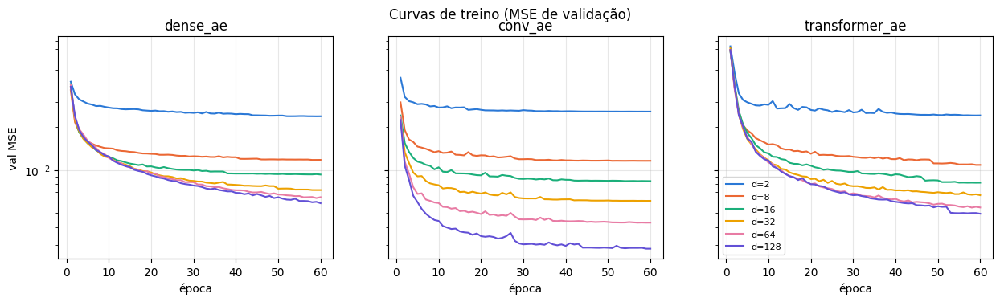

**Figura 17.** Curvas de treino (MSE de validação) dos 18 autoencoders base. **Desenhada** nesta célula, a partir de `outputs/ae/*/history.csv`. **Dados escritos em** `src/train_ae.py`, função `fit()`, linha 263. **Cálculo:** uma linha por época: loss de treino, val_mse, LR, tempo (VAE: também val_kl e β). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_ae --arch <arch> --dim <d>`.

In [21]:
fig_, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
cores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
for ax, arch in zip(axes, ['dense_ae', 'conv_ae', 'transformer_ae']):
    for i, d in enumerate([2, 8, 16, 32, 64, 128]):
        p = OUT / 'ae' / f'{arch}_d{d}' / 'history.csv'
        if p.exists():
            h = pd.read_csv(p)
            ax.plot(h.epoch, h.val_mse, color=cores[i], lw=1.5, label=f'd={d}')
    ax.set_yscale('log'); ax.set_title(arch); ax.set_xlabel('época'); ax.grid(alpha=.3)
axes[0].set_ylabel('val MSE'); axes[-1].legend(fontsize=8)
plt.suptitle('Curvas de treino (MSE de validação)'); plt.show()
fig_notebook('Curvas de treino (MSE de validação) dos 18 autoencoders base', 'outputs/ae/conv_ae_d32/history.csv')

### 4.2 Reconstruções: original, PCA e autoencoders

**Tabela 21.** MSE e SSIM de reconstrução (val/test) de PCA, dos 18 AEs base e dos especializados (VAE/DAE) por d. Ficheiro `outputs/metrics/recon_summary.csv`. **Escrita em** `src/embeddings_viz.py`, função `reconstructions()`, linha 88. **Cálculo:** MSE/SSIM do PCA (`src/representation.py::pca_recon_from_images`, `src/evaluate.py::ssim_pairs`) ao lado dos AEs. **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/metrics/ae_summary.csv` (calculado em `src/train_ae.py`, `collect()`, linha 367). **Refazer:** `python -m src.embeddings_viz`.

mse                                                      ssim                                                  
modelo conv_ae dae_conv dense_ae     pca transformer_ae vae_conv conv_ae dae_conv dense_ae     pca transformer_ae vae_conv
d                                                                                                                         
2       0.0256   0.0268   0.0237  0.0459         0.0241   0.0264  0.5709   0.5565   0.5918  0.3225         0.5802   0.5582
8       0.0116   0.0132   0.0118  0.0264         0.0109   0.0143  0.7432   0.7200   0.7365  0.4948         0.7591   0.6896
16      0.0084   0.0099   0.0093  0.0203         0.0082   0.0145  0.7926   0.7659   0.7727  0.5677         0.8005   0.6865
32      0.0061   0.0081   0.0072  0.0150         0.0067   0.0145  0.8373   0.7975   0.8125  0.6390         0.8288   0.6884
64      0.0043   0.0068   0.0064  0.0102         0.0055   0.0145  0.8836   0.8237   0.8296  0.7220         0.8567   0.6867
128     0.0028   0.0061   0.0059  0.0062         0.0050   0.0145  0.9245   0.8335   0.8414  0.8108         0.8683   0.6852

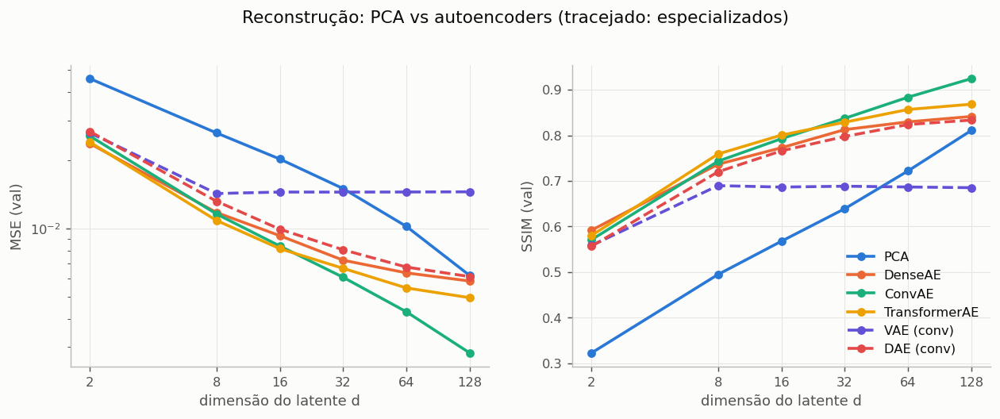

**Figura 18.** MSE e SSIM de reconstrução (val) vs d para PCA e AEs. Ficheiro `outputs/figures/recon_mse_ssim.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 105. **Cálculo:** MSE e SSIM de validação por d. **Dados:** `outputs/metrics/recon_summary.csv` (calculado em `src/embeddings_viz.py`, `reconstructions()`, linha 88). **Refazer:** `python -m src.embeddings_viz`.

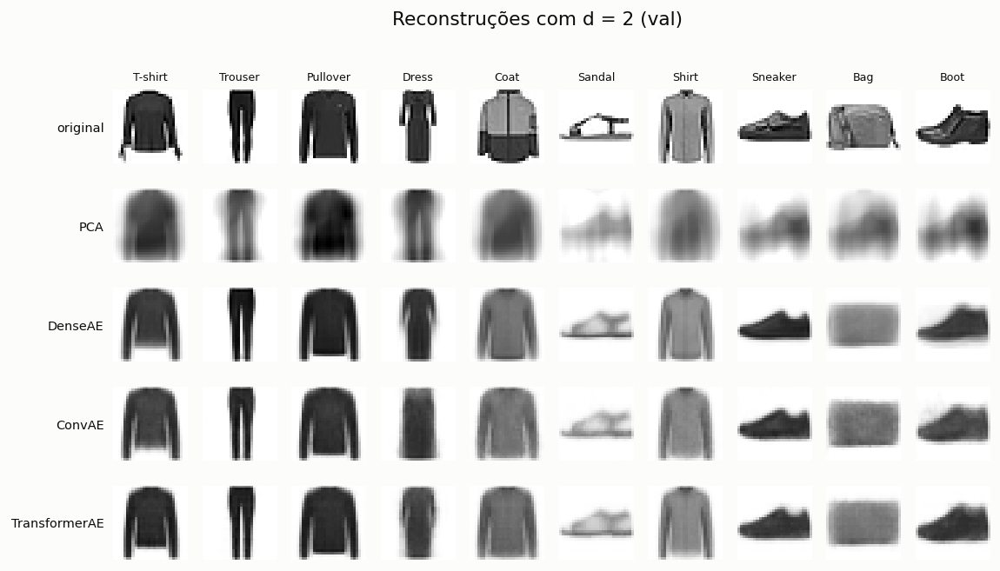

**Figura 19.** Painel original vs PCA vs AEs, d=2. Ficheiro `outputs/figures/recon_panel_d2.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 120. **Cálculo:** original vs PCA vs cada AE, 10 classes (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

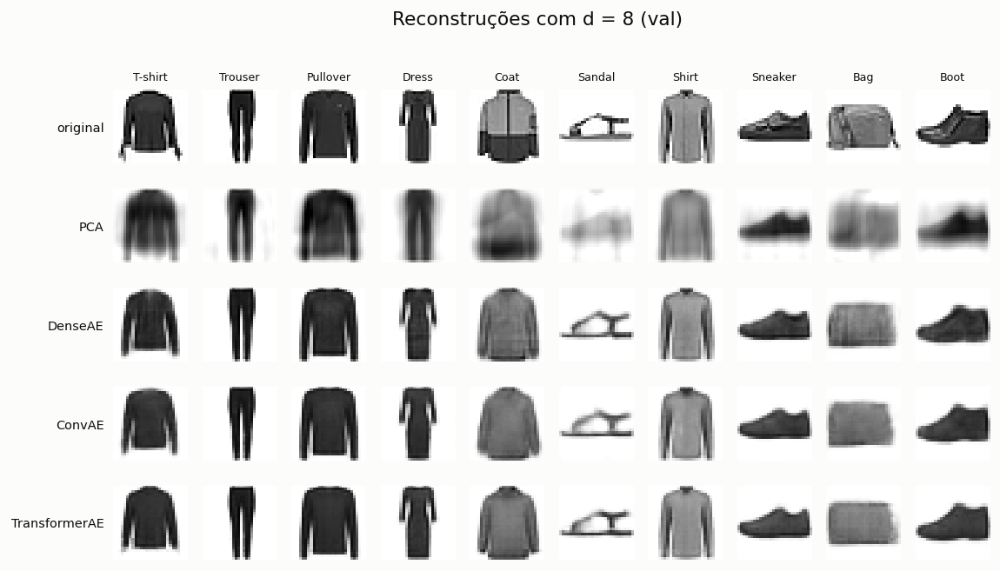

**Figura 20.** Painel original vs PCA vs AEs, d=8. Ficheiro `outputs/figures/recon_panel_d8.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 120. **Cálculo:** original vs PCA vs cada AE, 10 classes (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

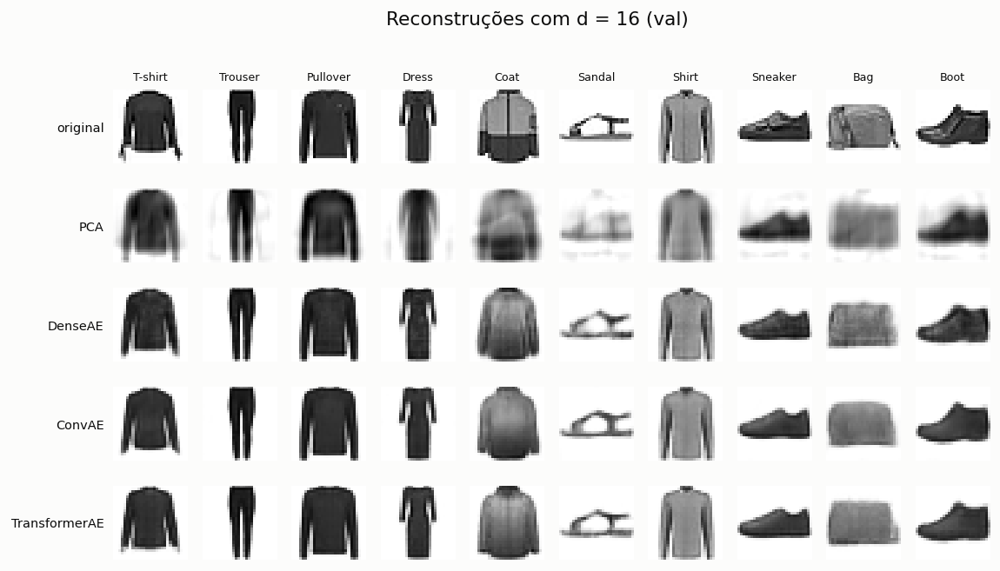

**Figura 21.** Painel original vs PCA vs AEs, d=16. Ficheiro `outputs/figures/recon_panel_d16.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 120. **Cálculo:** original vs PCA vs cada AE, 10 classes (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

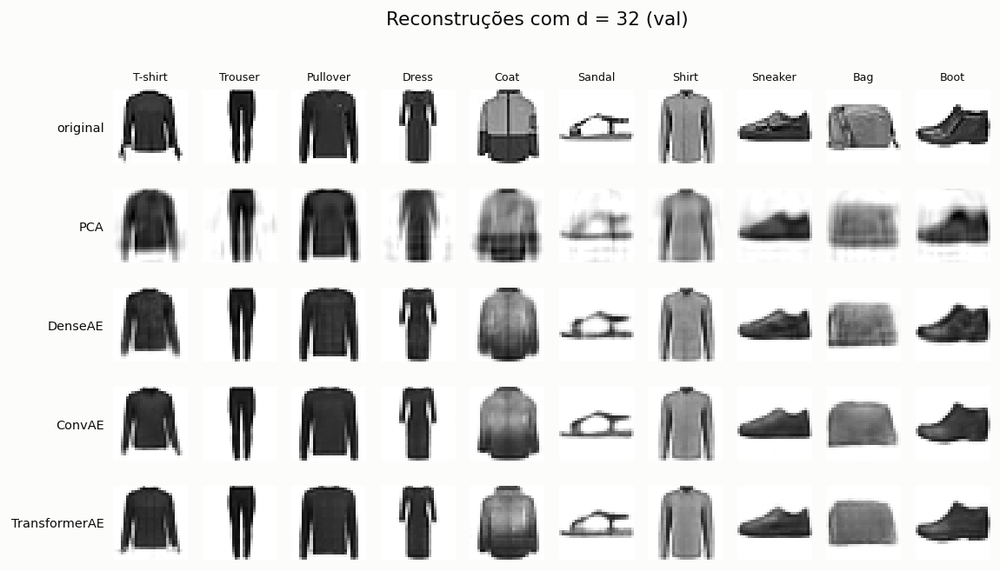

**Figura 22.** Painel original vs PCA vs AEs, d=32. Ficheiro `outputs/figures/recon_panel_d32.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 120. **Cálculo:** original vs PCA vs cada AE, 10 classes (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

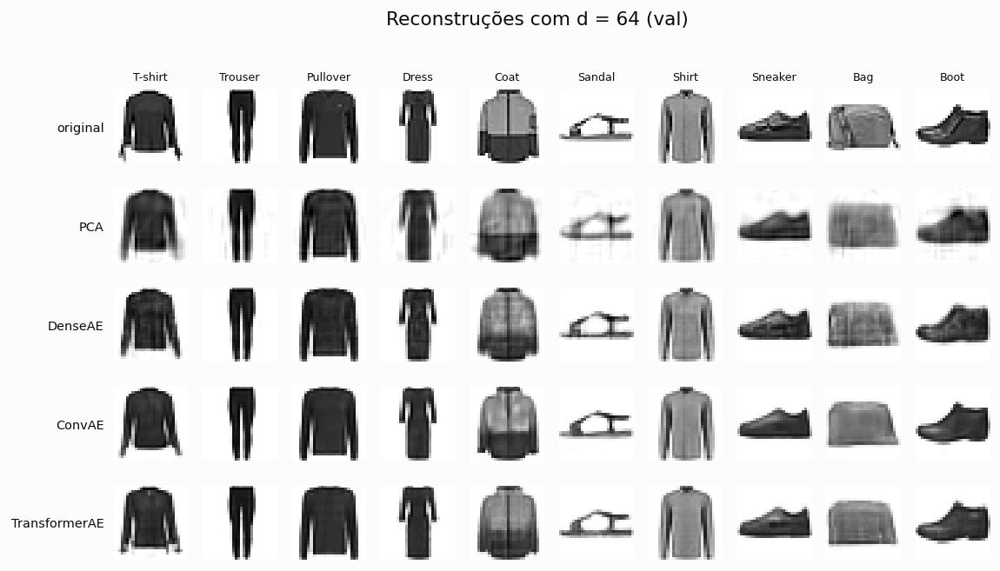

**Figura 23.** Painel original vs PCA vs AEs, d=64. Ficheiro `outputs/figures/recon_panel_d64.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 120. **Cálculo:** original vs PCA vs cada AE, 10 classes (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

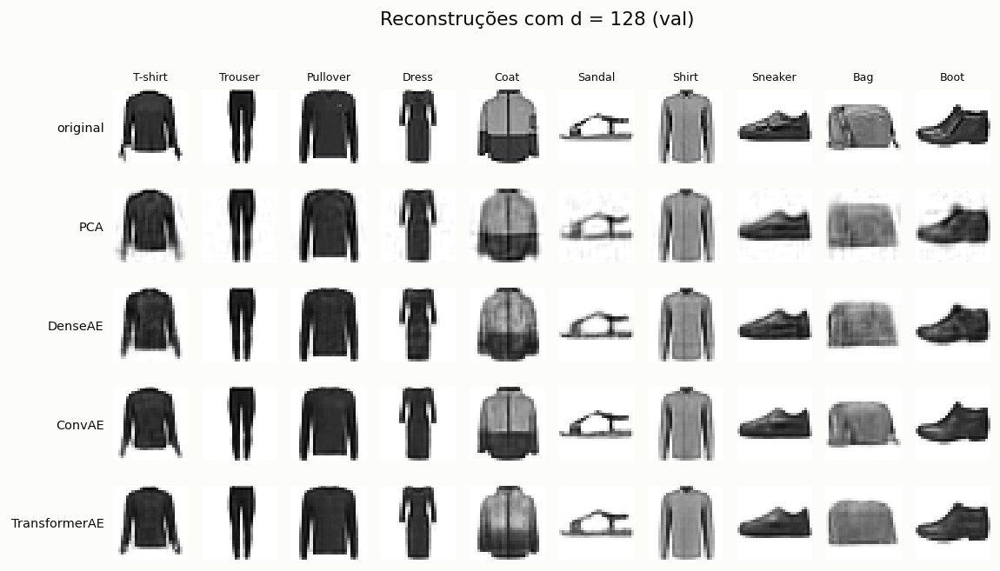

**Figura 24.** Painel original vs PCA vs AEs, d=128. Ficheiro `outputs/figures/recon_panel_d128.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 120. **Cálculo:** original vs PCA vs cada AE, 10 classes (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

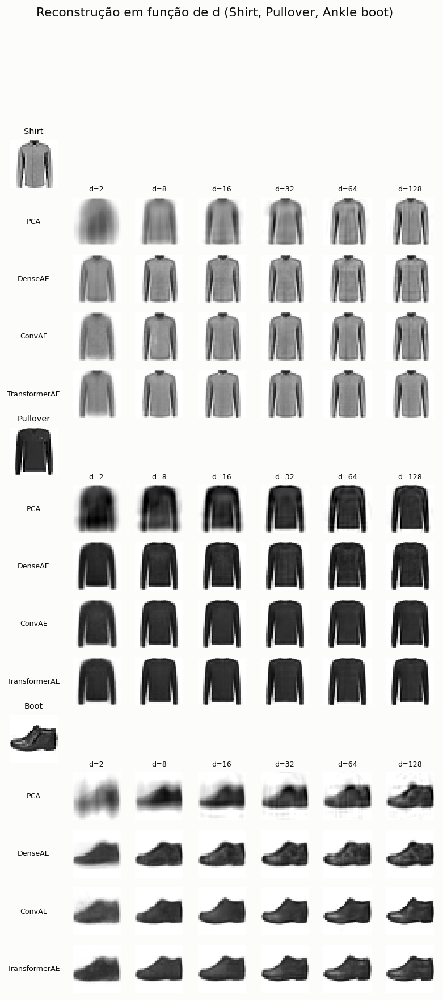

**Figura 25.** Reconstruções de 3 classes para todos os d e modelos. Ficheiro `outputs/figures/recon_panel_by_d.png`. **Gerada em** `src/embeddings_viz.py`, função `reconstructions()`, linha 140. **Cálculo:** reconstruções de 3 classes, para todos os d e modelos (`src/representation.py::ae_reconstruct`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.embeddings_viz`.

In [22]:
display(csv('recon_summary.csv').query("split == 'val'").pivot(index='d', columns='modelo', values=['mse', 'ssim']))
fig('recon_mse_ssim.png')
for d in (2, 8, 16, 32, 64, 128):
    fig(f'recon_panel_d{d}.png')
fig('recon_panel_by_d.png', width=520)

### 4.3 Separação das classes nos latentes

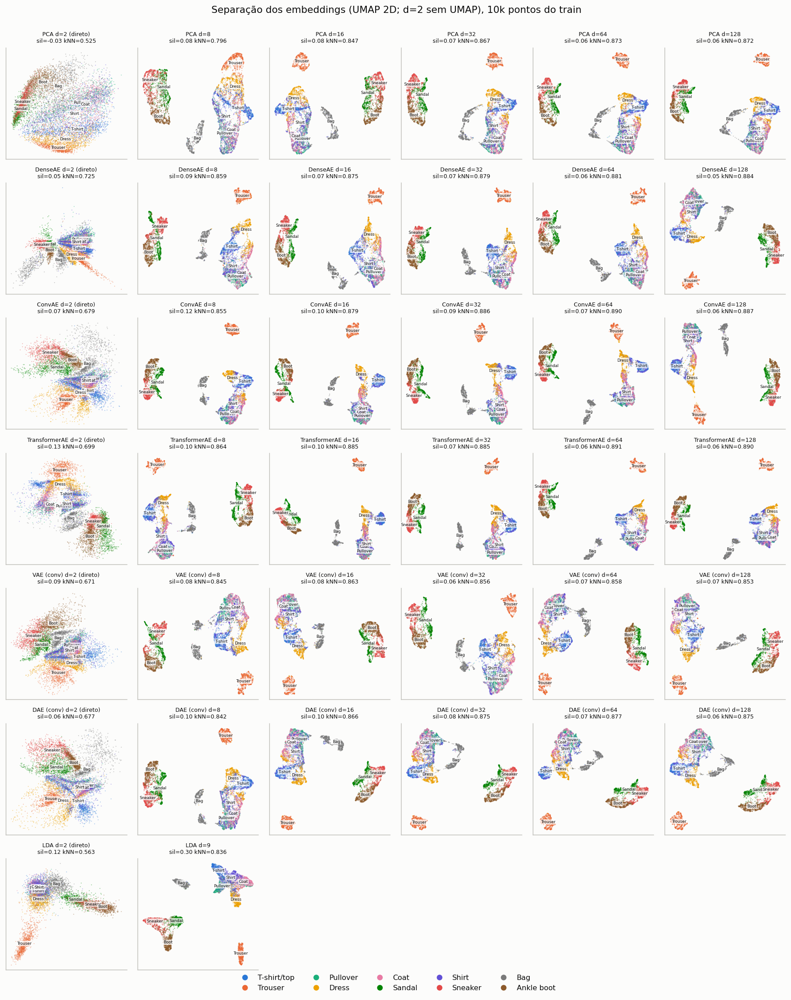

**Figura 26.** Grelha UMAP dos embeddings de todos os modelos (linhas = arquitetura, colunas = d). Ficheiro `outputs/figures/embeddings_grid.png`. **Gerada em** `src/embeddings_viz.py`, função `embeddings_and_clustering()`, linha 223. **Cálculo:** grelha linhas = modelo, colunas = d, sobre os 10k pontos. **Dados:** `outputs/viz/emb_*.npy` (calculado em `src/embeddings_viz.py`, `embed2d()`, linha 154), `outputs/metrics/embedding_clustering.csv` (calculado em `src/embeddings_viz.py`, `embeddings_and_clustering()`, linha 195). **Refazer:** `python -m src.embeddings_viz`.

In [23]:
fig('embeddings_grid.png')

**Tabela 22.** Métricas de agrupamento por classe (silhouette, Davies-Bouldin, kNN, NMI/ARI k-means) e ranking por posto médio, para PCA, LDA, os 18 AEs base e os especializados (specialized=True). Ficheiro `outputs/metrics/embedding_clustering.csv`. **Escrita em** `src/embeddings_viz.py`, função `embeddings_and_clustering()`, linha 195. **Cálculo:** silhouette, Davies-Bouldin, NMI/ARI k-means (`src/evaluate.py::clustering_metrics`), kNN val e ranking por posto médio. **Dados:** `outputs/latents/*` (calculado em `src/train_ae.py`, `train_one()`, linha 295), `outputs/pca/proj/*` (calculado em `src/pca_lda.py`, `step_ipca()`, linha 272), `outputs/lda/*` (calculado em `src/pca_lda.py`, `step_lda()`, linha 345), `outputs/splits/viz10k_idx.npy` (calculado em `src/data.py`, `prepare()`, linha 67). **Refazer:** `python -m src.embeddings_viz`.

,espaco,d,silhouette,davies_bouldin,kmeans_nmi,kmeans_ari,knn_val_acc,silhouette_2d,posto_medio,ranking,specialized
0,transformer_ae,16,0.0966,2.7417,0.6539,0.5072,0.8852,0.2731,6.2,1,False
1,lda,9,0.3049,1.2784,0.7306,0.6691,0.8355,0.4093,6.8,2,False
2,conv_ae,16,0.1047,2.4438,0.6194,0.4489,0.8792,0.2178,6.8,3,False
3,transformer_ae,8,0.0999,2.3352,0.6260,0.4521,0.8635,0.2560,7.8,4,False
4,conv_ae,32,0.0869,2.6798,0.6101,0.4310,0.8858,0.2576,8.6,5,False
5,conv_ae,8,0.1151,2.2328,0.6190,0.4464,0.8547,0.2329,9.0,6,False
6,conv_ae,64,0.0721,3.0001,0.5995,0.4180,0.8897,0.2523,12.6,7,False
7,transformer_ae,32,0.0709,3.2936,0.6368,0.4857,0.8847,0.2932,13.0,8,False
8,transformer_ae,2,0.1320,2.6664,0.5842,0.4237,0.6987,0.1320,13.0,9,False
9,dae_conv,16,0.0981,2.5914,0.5735,0.3938,0.8657,0.2345,13.0,10,True


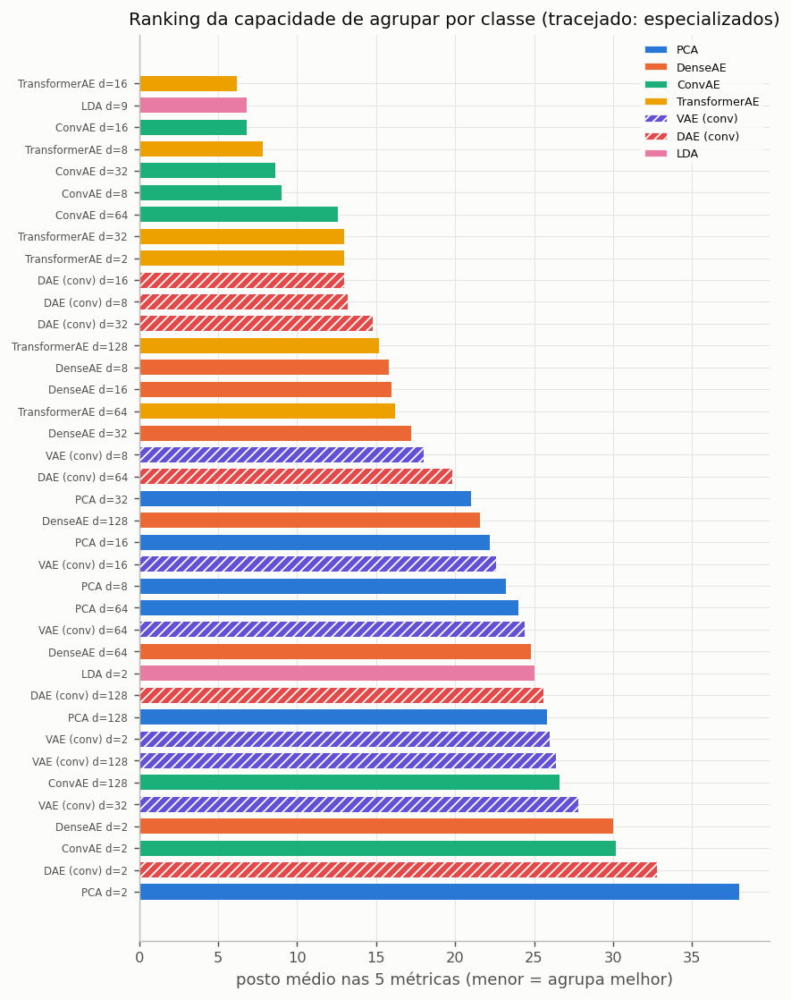

**Figura 27.** Ranking dos espaços por capacidade de agrupar por classe. Ficheiro `outputs/figures/embedding_ranking.png`. **Gerada em** `src/embeddings_viz.py`, função `embeddings_and_clustering()`, linha 237. **Cálculo:** espaços ordenados pelo posto médio. **Dados:** `outputs/metrics/embedding_clustering.csv` (calculado em `src/embeddings_viz.py`, `embeddings_and_clustering()`, linha 195). **Refazer:** `python -m src.embeddings_viz`.

In [24]:
cl = csv('embedding_clustering.csv')
display(cl)
fig('embedding_ranking.png', width=560)

### Interpretação de 4.1 a 4.3

- **Custo:** o DenseAE é o mais barato (0.7 s/época, 0.26 GB, cerca de 0.7 min por modelo), o ConvAE fica a 2.9 s/época (0.52 GB) e o TransformerAE é cerca de 20× mais lento do que o Dense (15.2 s/época, 0.94 GB, cerca de 15 min por modelo; 91 min para os 6). A atenção sobre 49 tokens com 8 blocos domina o custo, apesar de o nº de parâmetros ser parecido (cerca de 1.1M).
- **Convergência:** nenhum dos 18 modelos base parou por early stopping: todos usaram as 60 épocas e o melhor checkpoint está no fim. As comparações são, portanto, **a orçamento fixo**; o Transformer teve picos de loss pontuais com LR 1e-3, absorvidos pelo ReduceLROnPlateau.
- **Reconstrução:** com d pequeno os três AEs têm cerca de metade do erro do PCA (d=8: 0.011–0.012 contra 0.026) e ficam muito próximos entre si, porque com um bottleneck tão estreito o limite é a dimensão e não a arquitetura. Com d grande separam-se: o **ConvAE** é claramente o melhor (d=128: MSE 0.0028, SSIM 0.924), porque o viés convolucional (localidade e partilha de pesos) aproveita a capacidade extra para recuperar detalhe e textura; o **DenseAE estagna** a partir de d≈64 (0.0059, igual ao PCA-128) e o **TransformerAE** fica no meio (0.0050). Nos painéis vê-se que os AEs mantêm contornos nítidos onde o PCA produz "fantasmas" de outras classes, mas todos perdem padrões finos (riscas, logótipos), que exigem d grande.
- **Separação dos embeddings:** os AEs organizam as classes melhor do que o PCA com o mesmo d (NMI do k-means com d=8–16: 0.62–0.65 no ConvAE e no TransformerAE, cerca de 0.57 no DenseAE, 0.53 no PCA). No ranking por posto médio (38 espaços, com os especializados) o **TransformerAE d=16** fica em 1.º (6.2), seguido da **LDA-9** (6.8) e do ConvAE d=16 (6.8). A LDA, que é supervisionada, é a melhor em 4 das 5 métricas e só desce por ficar em 30.º no kNN; como o posto é relativo ao conjunto, a sua posição depende de quantos espaços entram (só com os espaços base estava em 1.º). Os especializados ficam abaixo: melhor DAE d=16 em 10.º e melhor VAE d=8 em 18.º. Há uma tensão clara com d: a accuracy kNN continua a subir até d=64–128 (0.89), mas a silhouette, o Davies-Bouldin e o k-means pioram, porque com mais dimensões o latente codifica mais variação intra-classe (estilo, brilho) que dilui os grupos. **d≈16 é o ponto em que os latentes agrupam melhor**, curiosamente perto da dimensão intrínseca estimada pelo TwoNN (cerca de 16). Com d=2 (sem UMAP) os AEs já separam calçado, calças e malas, mas sobrepõem todas as classes de tronco.

### 4.4 Autoencoders especializados (VAE e Denoising)

**Motivação.** Os autoencoders base só minimizam o erro de reconstrução, por isso nada garante que o latente seja regular nem que resista a perturbações. O **VAE** impõe uma distribuição ao latente (permite gerar amostras e, em princípio, interpolar melhor); o **DAE** obriga o modelo a recuperar a imagem limpa a partir de uma versão ruidosa (em princípio, representações mais robustas). Os dois usam o encoder e o decoder do ConvAE e o mesmo protocolo, por isso as diferenças vêm do objetivo de treino (e, no VAE, da cabeça extra de logvar).

| | ConvAE (base) | `vae_conv` | `dae_conv` |
|---|---|---|---|
| Input de treino | imagem | imagem | imagem + ruído gaussiano (σ = 0.3, clip a [0,1]) |
| Objetivo | MSE por pixel | MSE somado por imagem + β·KL (β = 1, warm-up nas 10 primeiras épocas) | MSE por pixel contra a imagem limpa |
| Latente usado | z | mu (logvar guardado à parte) | z, com input limpo |
| Critério de early stopping | MSE de validação | objetivo com β = 1 em validação | MSE de denoising em validação |

Nº de parâmetros por d:

**Método e código.**
- **VAE** (`src/models.py::ConvVAE`): usa o tronco e o decoder do ConvAE; a última camada do encoder passa a ser a cabeça de mu e junta-se outra para logvar. No treino, z = mu + ε·exp(logvar/2) (`forward_train`).
- **Loss do VAE** (`src/train_ae.py::train_loss`, `src/train_ae.py::kl_div`): MSE somado por imagem + β_t·KL, com β_t = min(1, passo/(10 × passos por época)). O KL é medido em nats. Durante o warm-up, a patience e a redução do LR ficam congeladas.
- **Validação do VAE** (`src/train_ae.py::vae_val`): reconstrói a partir de mu; o critério de paragem é o objetivo com β=1. `src/train_ae.py::vae_stats` conta as unidades ativas (Var_x[mu_j] > 0.01). `src/train_ae.py::encode_logvar` guarda logvar.
- **DAE** (a classe `src/models.py::ConvAE`, com outro input): `src/train_ae.py::add_noise` soma ruído gaussiano σ=0.3 e faz clip a [0,1]; o alvo é a imagem limpa. O critério de paragem em `src/train_ae.py::validate` usa ruído fixo no val. A avaliação final usa input limpo.
- **Análises** (`src/specialized.py`): `src/specialized.py::summary_table`, `src/specialized.py::recon_panels`, `src/specialized.py::samples` (100 vetores z amostrados de N(0, I); referência: gaussiana ajustada aos latentes do ConvAE), `src/specialized.py::interpolation` (200 pares do val, 10 pontos por par) e `src/specialized.py::hypotheses`.
- **Medidas da interpolação:** `cv_passos` é o coeficiente de variação dos passos L2 entre frames (0 = uniforme); `racio_interior_extremos` é a distância dos frames intermédios à imagem mais próxima do train, a dividir pela dos extremos.
- **Robustez** (`src/robustness.py::compute`): as 10 000 imagens do test com ruído contra a galeria limpa de 54 000. O ruído ε é gerado uma vez e é o mesmo para todos os espaços e σ. Os espaços vêm do registo de `src/retrieval.py::_registry`; a reconstrução, de `src/robustness.py::reconstruct`.

In [25]:
ss = csv('specialized_summary.csv')
display(ss.pivot(index='d', columns='modelo', values='params').rename_axis(columns='nº de parâmetros'))

**Tabela 23.** ConvAE base vs VAE vs DAE por d: parâmetros, épocas, MSE/SSIM (val/test), KL e unidades ativas (VAE), MSE de denoising σ=0.3 no test (os três), tempo/época e memória. Ficheiro `outputs/metrics/specialized_summary.csv`. **Escrita em** `src/specialized.py`, função `summary_table()`, linha 79. **Cálculo:** métricas dos `metrics.json` e MSE de denoising σ=0.3 no test para ConvAE e VAE (`src/representation.py::ae_reconstruct`). **Dados:** `outputs/ae/{conv_ae,vae_conv,dae_conv}_d*/metrics.json` (calculado em `src/train_ae.py`, `train_one()`, linha 322), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.specialized`.

nº de parâmetros,conv_ae,dae_conv,vae_conv
d,,,
2,132131,132131,138405
8,169769,169769,194865
16,219953,219953,270145
32,320321,320321,420705
64,521057,521057,721825
128,922529,922529,1324065


#### 4.4.1 Reconstrução, KL e unidades ativas

In [26]:
cols = ['val_mse', 'val_ssim', 'test_mse', 'test_ssim']
display(ss.pivot(index='d', columns='modelo', values=cols).reindex(columns=['conv_ae', 'vae_conv', 'dae_conv'], level=1))
print('VAE: KL médio por imagem (test, nats) e unidades ativas (Var[mu_j] > 0.01, val/test):')
display(ss[ss.modelo == 'vae_conv'][['d', 'test_kl', 'active_units_val', 'active_units_test', 'val_mse', 'test_mse']].reset_index(drop=True))
print('MSE de denoising no test (input com ruído σ = 0.3, alvo limpo; mesmo ruído para os três):')
display(ss.pivot(index='d', columns='modelo', values='test_denoise_mse_sigma03')[['conv_ae', 'vae_conv', 'dae_conv']])
print('Custo (s/época e pico de memória GPU):')
display(ss.pivot(index='d', columns='modelo', values=['time_per_epoch_s', 'peak_gpu_mem_mb']))

val_mse                   val_ssim                   test_mse                   test_ssim                  
modelo conv_ae vae_conv dae_conv  conv_ae vae_conv dae_conv  conv_ae vae_conv dae_conv   conv_ae vae_conv dae_conv
d                                                                                                                 
2       0.0256   0.0264   0.0268   0.5709   0.5582   0.5565   0.0261   0.0268   0.0271    0.5698   0.5568   0.5572
8       0.0116   0.0143   0.0132   0.7432   0.6896   0.7200   0.0119   0.0145   0.0135    0.7404   0.6879   0.7190
16      0.0084   0.0145   0.0099   0.7926   0.6865   0.7659   0.0086   0.0147   0.0101    0.7899   0.6852   0.7646
32      0.0061   0.0145   0.0081   0.8373   0.6884   0.7975   0.0063   0.0147   0.0082    0.8347   0.6867   0.7962
64      0.0043   0.0145   0.0068   0.8836   0.6867   0.8237   0.0044   0.0147   0.0069    0.8813   0.6847   0.8227
128     0.0028   0.0145   0.0061   0.9245   0.6852   0.8335   0.0029   0.0148   0.0063    0.9227   0.6835   0.8329

VAE: KL médio por imagem (test, nats) e unidades ativas (Var[mu_j] > 0.01, val/test):


,d,test_kl,active_units_val,active_units_test,val_mse,test_mse
0,2,5.1259,2.0,2.0,0.0264,0.0268
1,8,8.7241,8.0,8.0,0.0143,0.0145
2,16,8.7343,16.0,16.0,0.0145,0.0147
3,32,8.6139,16.0,16.0,0.0145,0.0147
4,64,8.7434,14.0,14.0,0.0145,0.0147
5,128,8.8337,12.0,12.0,0.0145,0.0148


MSE de denoising no test (input com ruído σ = 0.3, alvo limpo; mesmo ruído para os três):


modelo,conv_ae,vae_conv,dae_conv
d,,,
2,0.0661,0.0512,0.0267
8,0.0397,0.0322,0.0132
16,0.0353,0.0297,0.0104
32,0.0291,0.0281,0.0089
64,0.0253,0.0259,0.0078
128,0.0253,0.0269,0.0072


Custo (s/época e pico de memória GPU):


time_per_epoch_s                   peak_gpu_mem_mb                    
modelo          conv_ae dae_conv vae_conv         conv_ae  dae_conv  vae_conv
d                                                                            
2                2.8554   2.1711   2.1996        506.3823  524.3823  499.6533
8                2.8826   2.1325   2.2099        507.0034  525.0034  500.6084
16               2.9180   2.1079   2.1223        507.8315  525.8315  501.8818
32               2.9121   2.0882   2.1578        509.4878  527.4878  504.4287
64               2.9362   2.0258   2.5104        512.8003  530.8003  509.5225
128              3.0021   2.0981   2.2979        519.6440  538.3315  519.9287

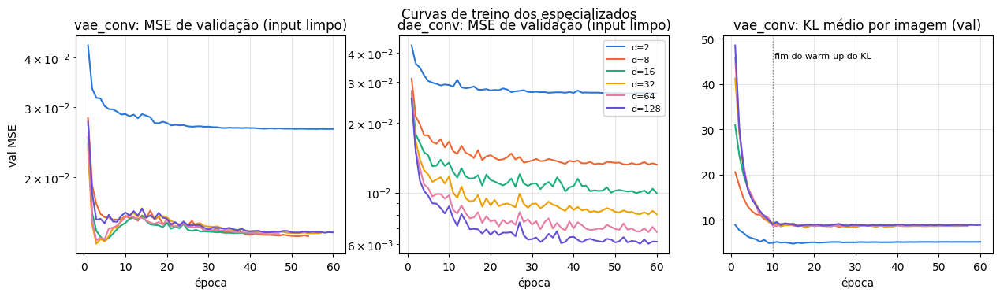

**Figura 28.** Curvas de treino do VAE e do DAE, e KL do VAE. **Desenhada** nesta célula, a partir de `outputs/ae/*/history.csv`. **Dados escritos em** `src/train_ae.py`, função `fit()`, linha 263. **Cálculo:** uma linha por época: loss de treino, val_mse, LR, tempo (VAE: também val_kl e β). **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_ae --arch <arch> --dim <d>`.

In [27]:
fig_, axes = plt.subplots(1, 3, figsize=(15, 3.6))
cores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
for ax, arch in zip(axes[:2], ['vae_conv', 'dae_conv']):
    for i, d in enumerate([2, 8, 16, 32, 64, 128]):
        p = OUT / 'ae' / f'{arch}_d{d}' / 'history.csv'
        if p.exists():
            h = pd.read_csv(p)
            ax.plot(h.epoch, h.val_mse, color=cores[i], lw=1.5, label=f'd={d}')
            if arch == 'vae_conv':
                axes[2].plot(h.epoch, h.val_kl, color=cores[i], lw=1.5, label=f'd={d}')
    ax.set_yscale('log'); ax.set_title(f'{arch}: MSE de validação (input limpo)'); ax.set_xlabel('época'); ax.grid(alpha=.3)
axes[2].axvline(10, color='#7a7a7a', ls=':', lw=1); axes[2].text(10.5, axes[2].get_ylim()[1] * 0.9, 'fim do warm-up do KL', fontsize=8)
axes[2].set_title('vae_conv: KL médio por imagem (val)'); axes[2].set_xlabel('época'); axes[2].grid(alpha=.3)
axes[0].set_ylabel('val MSE'); axes[1].legend(fontsize=8)
plt.suptitle('Curvas de treino dos especializados'); plt.show()
fig_notebook('Curvas de treino do VAE e do DAE, e KL do VAE', 'outputs/ae/vae_conv_d32/history.csv')

**Interpretação.**

- **VAE:** o MSE deixa de melhorar a partir de **d=8** (0.0143–0.0145 para d = 8 a 128; SSIM ≈ 0.69), enquanto o ConvAE continua a descer até 0.0028. A diferença vai de +3% em d=2 a 5× em d=128. O KL estabiliza em cerca de 8.7 nats por imagem seja qual for d (5.1 em d=2): com MSE somado e β = 1, cada nat só compensa se reduzir o erro somado em mais do que 1, e este equilíbrio limita a informação que passa pelo latente. Dar mais dimensões não dá mais capacidade.
- **Unidades ativas:** 2/2, 8/8, 16/16, 16/32, 14/64 e 12/128. O warm-up do KL **não evitou o colapso parcial** com d ≥ 32. A contagem também engana um pouco: com d=16 as 16 unidades passam o limiar de 0.01, mas só 12 têm variância > 0.1, e o KL total é igual ao de d=8. O VAE reparte a mesma informação por mais dimensões.
- **DAE:** com input limpo, reconstrói pior do que o ConvAE (+5% em d=2, 2.2× em d=128), o que é o preço esperado de não treinar para copiar detalhe. Em contrapartida, com input ruidoso (σ = 0.3) tem **2.5 a 3.5 vezes menos erro** do que o ConvAE ao mesmo d.
- **Convergência e custo:** 4 dos 6 VAEs pararam por early stopping (épocas 42–57; são os únicos autoencoders do projeto a parar antes do limite). Todos os DAEs chegaram às 60 épocas com a melhor época na última, por isso ainda podem ter margem: os resultados do DAE são a orçamento fixo. Custo parecido nos dois: cerca de 2.1–2.3 s/época, 12 min para os 6 modelos e 0.5 GB. O ConvAE base (2.9 s/época) foi medido com a GPU mais ocupada, por isso esse tempo não é diretamente comparável.

#### 4.4.2 Painéis, amostras do VAE e interpolação

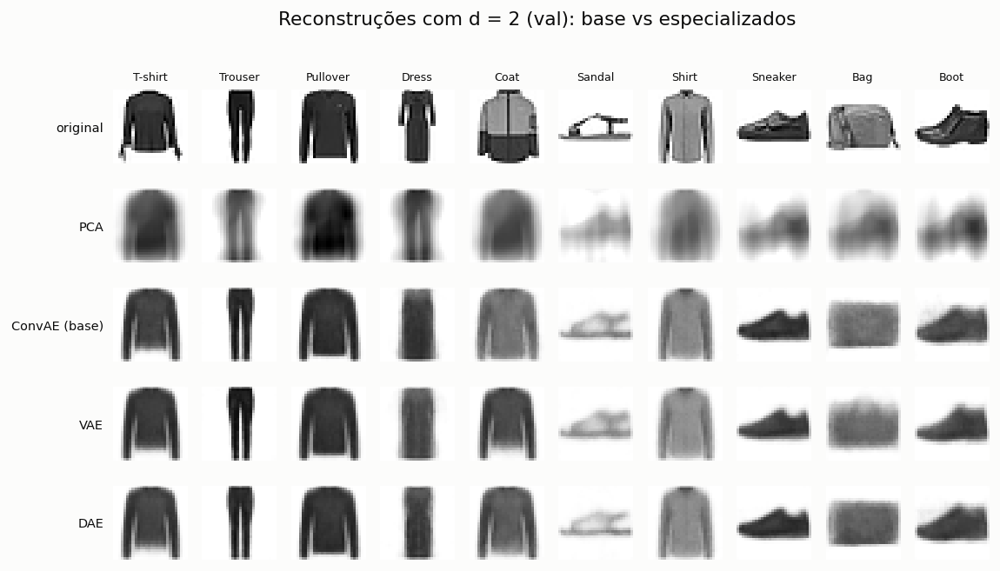

**Figura 29.** Painel original / PCA / ConvAE / VAE / DAE, d=2. Ficheiro `outputs/figures/recon_panel_specialized_d2.png`. **Gerada em** `src/specialized.py`, função `recon_panels()`, linha 98. **Cálculo:** original / PCA / ConvAE / VAE / DAE (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/{conv_ae,vae_conv,dae_conv}_d*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241). **Refazer:** `python -m src.specialized`.

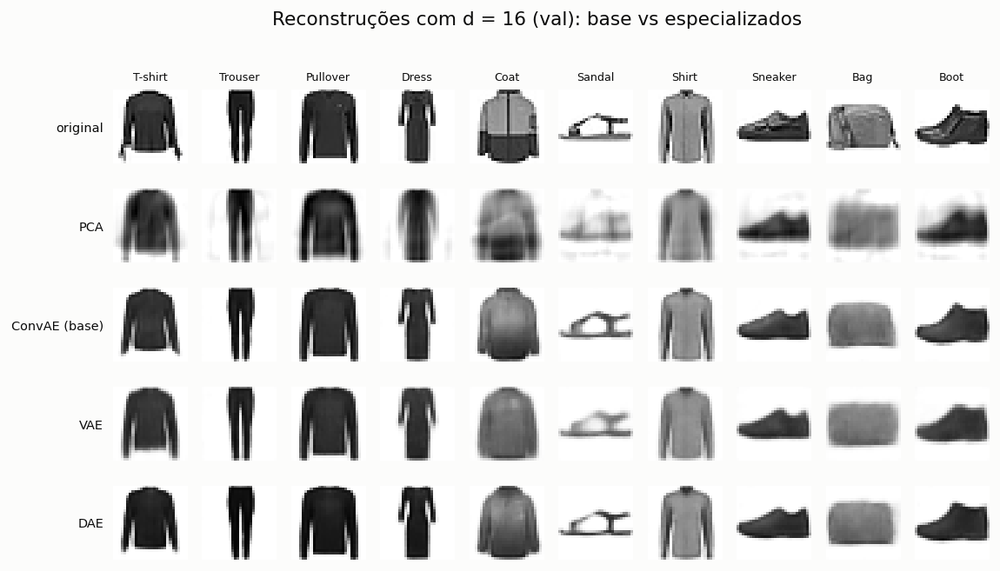

**Figura 30.** Painel original / PCA / ConvAE / VAE / DAE, d=16. Ficheiro `outputs/figures/recon_panel_specialized_d16.png`. **Gerada em** `src/specialized.py`, função `recon_panels()`, linha 98. **Cálculo:** original / PCA / ConvAE / VAE / DAE (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/{conv_ae,vae_conv,dae_conv}_d*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241). **Refazer:** `python -m src.specialized`.

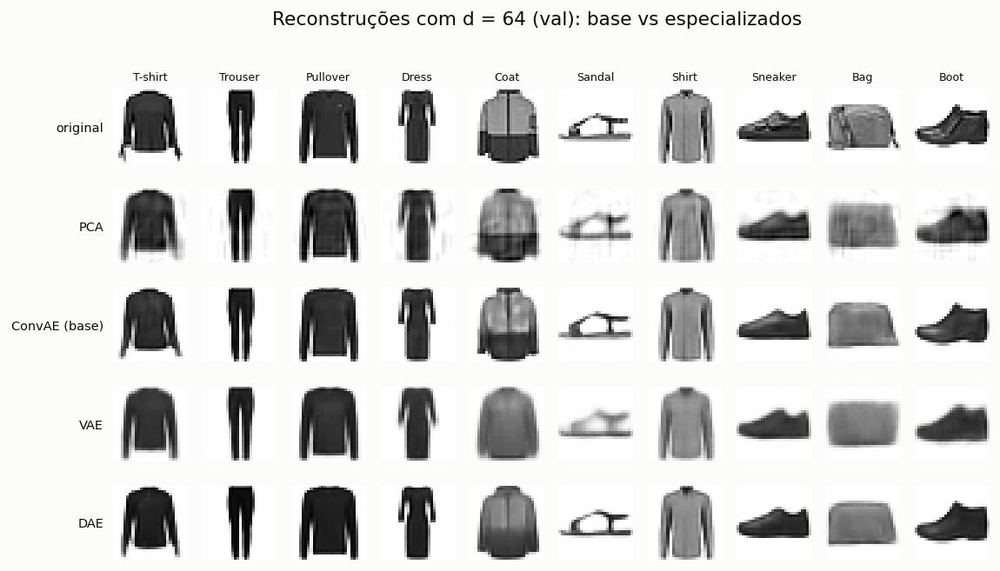

**Figura 31.** Painel original / PCA / ConvAE / VAE / DAE, d=64. Ficheiro `outputs/figures/recon_panel_specialized_d64.png`. **Gerada em** `src/specialized.py`, função `recon_panels()`, linha 98. **Cálculo:** original / PCA / ConvAE / VAE / DAE (`src/representation.py::ae_reconstruct`, `src/representation.py::pca_recon_from_images`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/{conv_ae,vae_conv,dae_conv}_d*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241). **Refazer:** `python -m src.specialized`.

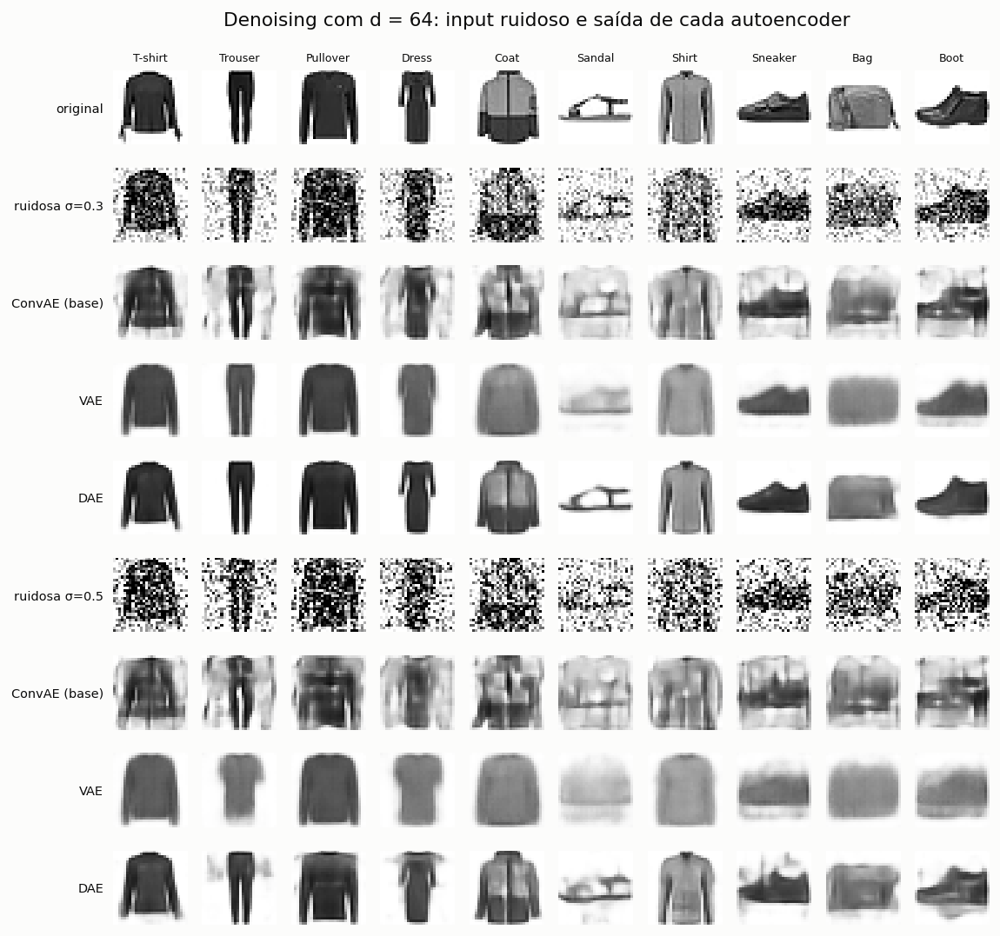

**Figura 32.** Painel de denoising (σ=0.3 e 0.5) para ConvAE, VAE e DAE com d=64. Ficheiro `outputs/figures/denoise_panel.png`. **Gerada em** `src/specialized.py`, função `recon_panels()`, linha 118. **Cálculo:** reconstrução de imagens com ruído σ=0.3 e 0.5, d=64. **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/{conv_ae,vae_conv,dae_conv}_d64/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241). **Refazer:** `python -m src.specialized`.

In [28]:
for d in (2, 16, 64):
    fig(f'recon_panel_specialized_d{d}.png')
fig('denoise_panel.png', width=640)

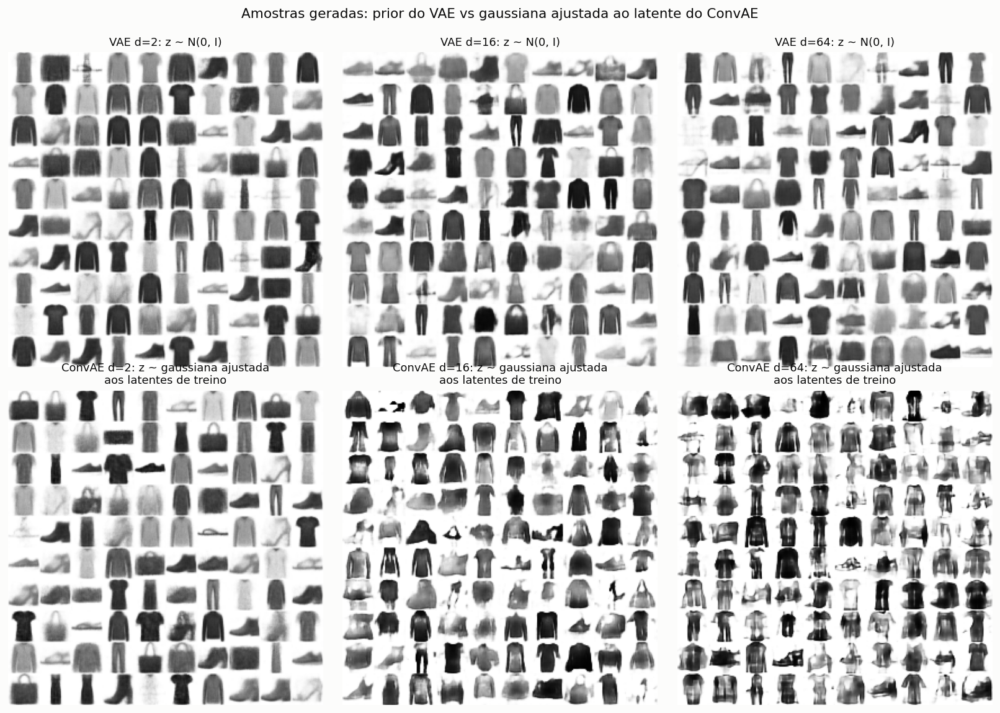

**Figura 33.** Amostras 10x10 do prior N(0,I) do VAE (d=2,16,64) e referência do ConvAE. Ficheiro `outputs/figures/vae_samples.png`. **Gerada em** `src/specialized.py`, função `samples()`, linha 139. **Cálculo:** 100 vetores z amostrados de N(0, I) e descodificados (`src/representation.py::ae_decode`); referência: gaussiana ajustada aos latentes do ConvAE. **Dados:** `outputs/ae/vae_conv_d{2,16,64}/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/latents/conv_ae_d{2,16,64}_train.npy` (calculado em `src/train_ae.py`, `train_one()`, linha 295). **Refazer:** `python -m src.specialized`.

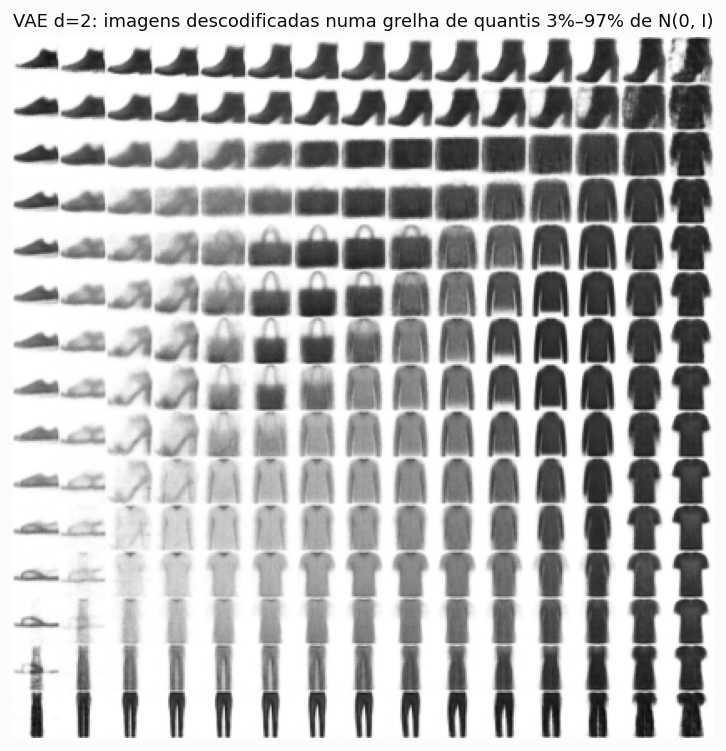

**Figura 34.** Variedade 2D descodificada do VAE d=2. Ficheiro `outputs/figures/vae_manifold_d2.png`. **Gerada em** `src/specialized.py`, função `samples()`, linha 150. **Cálculo:** descodificação de uma grelha 15×15 de quantis 3–97% de N(0, I). **Dados:** `outputs/ae/vae_conv_d2/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241). **Refazer:** `python -m src.specialized`.

In [29]:
fig('vae_samples.png')
fig('vae_manifold_d2.png', width=520)

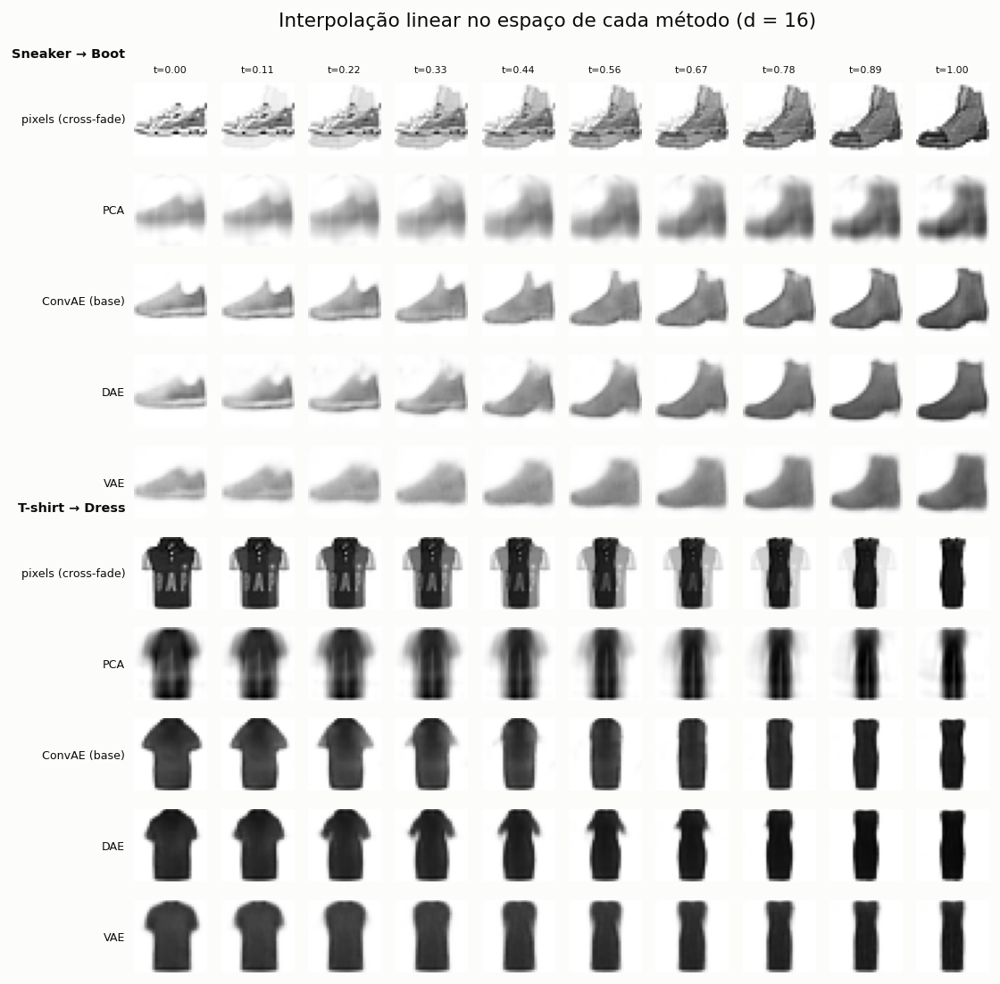

**Figura 35.** Interpolação latente pixels/PCA/ConvAE/DAE/VAE, d=16. Ficheiro `outputs/figures/interpolation_d16.png`. **Gerada em** `src/specialized.py`, função `interpolation()`, linha 189. **Cálculo:** interpolação Sneaker → Ankle boot em pixels, PCA e latente (`src/specialized.py::_paths`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.specialized`.

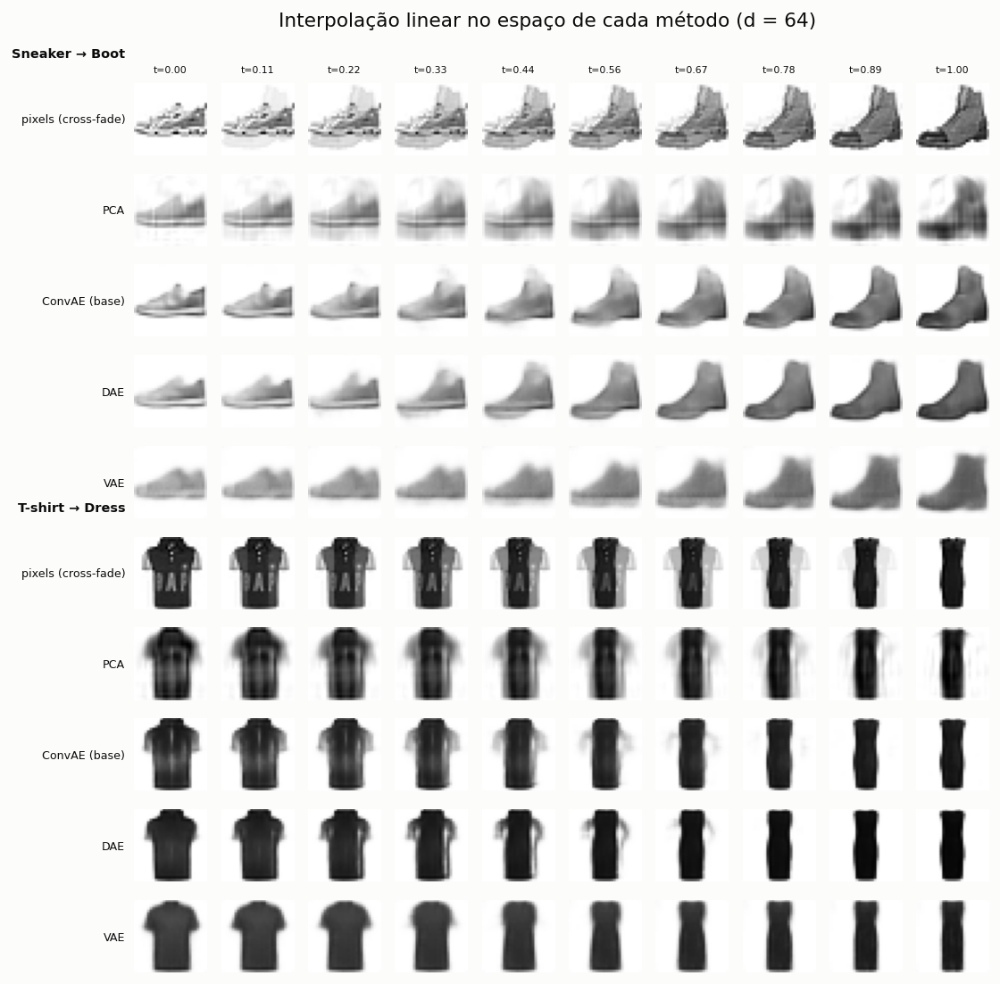

**Figura 36.** Interpolação latente pixels/PCA/ConvAE/DAE/VAE, d=64. Ficheiro `outputs/figures/interpolation_d64.png`. **Gerada em** `src/specialized.py`, função `interpolation()`, linha 189. **Cálculo:** interpolação Sneaker → Ankle boot em pixels, PCA e latente (`src/specialized.py::_paths`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241), `outputs/pca/pca_full.joblib` (calculado em `src/pca_lda.py`, `step_full()`, linha 56). **Refazer:** `python -m src.specialized`.

**Tabela 24.** Suavidade da interpolação latente em 200 pares do val: CV dos passos, fração do maior passo, distância ao vizinho real mais próximo (frames interiores vs extremos). Ficheiro `outputs/metrics/interpolation.csv`. **Escrita em** `src/specialized.py`, função `interpolation()`, linha 217. **Cálculo:** 200 pares do val: CV dos passos e distância ao vizinho do train (`src/evaluate.py::knn_search`). **Dados:** `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/ae/*/best.pt` (calculado em `src/train_ae.py`, `fit()`, linha 241). **Refazer:** `python -m src.specialized`.

,metodo,d,n_pares,cv_passos,passo_max_frac,dist_nn_interior,dist_nn_extremos,racio_interior_extremos
0,pixels,16,200,4.7828e-16,0.1111,4.0195,3.6049,1.1150
1,pca,16,200,4.0137e-02,0.1137,3.5435,3.1386,1.1290
2,conv_ae,16,200,1.0596e-01,0.1292,3.4810,2.9876,1.1651
3,dae_conv,16,200,1.7052e-01,0.1403,3.4242,2.9397,1.1648
4,vae_conv,16,200,3.8176e-01,0.1914,2.8244,2.5670,1.1003
5,pixels,64,200,4.7828e-16,0.1111,4.0195,3.6049,1.1150
6,pca,64,200,3.6026e-02,0.1133,3.6725,3.1447,1.1678
7,conv_ae,64,200,1.2482e-01,0.1280,3.6154,3.2749,1.1040
8,dae_conv,64,200,2.8633e-01,0.1583,3.4918,3.0901,1.1300
9,vae_conv,64,200,4.2215e-01,0.2028,2.7943,2.5807,1.0828


In [30]:
for d in (16, 64):
    fig(f'interpolation_d{d}.png', width=640)
display(csv('interpolation.csv'))

**Interpretação.**

- **Amostras:** com d=16 e d=64 as amostras do prior do VAE são desfocadas, mas reconhecíveis como peças de roupa, enquanto uma gaussiana ajustada aos latentes do ConvAE dá manchas e peças deformadas, cada vez piores com d maior. Com d=2 as duas fontes dão amostras razoáveis. Esta é a vantagem mais visível do VAE, mas é uma avaliação visual: não foi medida com um número nem fazia parte dos critérios de H1.
- **Interpolação (exemplos):** pixels e PCA fazem sobreposição de duas imagens (no PCA isto é garantido, porque o decoder é afim). Os três AEs deformam a peça em vez de a sobrepor.
- **Interpolação (200 pares):** as duas medidas pré-definidas discordam. O VAE tem o melhor rácio interior/extremos (d=16: 1.100 contra 1.165 no ConvAE; d=64: 1.083 contra 1.104), mas transições **menos** uniformes (CV dos passos 0.38 contra 0.11 e 0.42 contra 0.12; o maior passo concentra cerca de 19–20% do caminho, contra cerca de 13%).
- **Limites destas medidas:** o rácio distingue mal o que se vê nas figuras: o cross-fade de pixels, com sobreposições evidentes, tem 1.115, melhor do que o ConvAE d=16. A distância L2 também favorece imagens desfocadas (os extremos do VAE estão *mais perto* de imagens reais do que os do ConvAE, apesar de terem pior MSE). E o CV é praticamente 0 por construção nos métodos afins. Nenhuma das duas mede bem "parece uma peça de roupa em todos os frames".

#### 4.4.3 Robustez a queries com ruído

**Tabela 25.** Robustez a queries ruidosas: precision@10, accuracy kNN e MSE de reconstrução vs imagem limpa, por espaço e σ do ruído. Ficheiro `outputs/metrics/robustness.csv`. **Escrita em** `src/robustness.py`, função `main()`, linha 98. **Cálculo:** queries com ruído e galeria limpa: P@10, kNN e MSE vs imagem limpa (`src/robustness.py::compute`). **Dados:** `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), modelos e latentes com d=64 / k=64. **Refazer:** `python -m src.robustness`.

precision@10                         knn_acc                         mse_reconstrucao_vs_limpa                        
sigma_teste           0.0     0.1     0.3     0.5     0.0     0.1     0.3     0.5                       0.0     0.1     0.3     0.5
espaco                                                                                                                             
raw                0.8026  0.7970  0.7574  0.6204  0.8524  0.8447  0.8112  0.6689                    0.0000  0.0069  0.0527  0.1177
pca_k64            0.8055  0.8008  0.7585  0.5807  0.8563  0.8534  0.8184  0.6321                    0.0098  0.0114  0.0210  0.0379
conv_ae_d64        0.8366  0.8141  0.5303  0.1930  0.8834  0.8615  0.5679  0.1901                    0.0044  0.0073  0.0253  0.0463
dae_conv_d64       0.8160  0.8137  0.7989  0.7212  0.8633  0.8616  0.8521  0.7754                    0.0069  0.0067  0.0078  0.0176
vae_conv_d64       0.7945  0.7766  0.5890  0.2962  0.8429  0.8313  0.6474  0.3229                    0.0147  0.0157  0.0260  0.0469

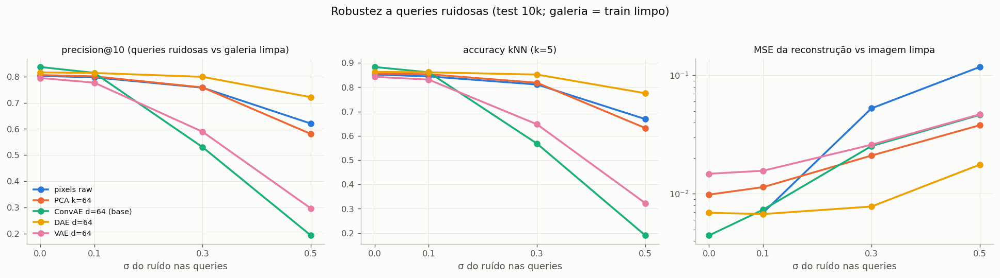

**Figura 37.** Precision@10, accuracy kNN e MSE de reconstrução vs σ do ruído nas queries. Ficheiro `outputs/figures/robustness.png`. **Gerada em** `src/robustness.py`, função `figure()`, linha 89. **Cálculo:** P@10, accuracy kNN e MSE em função de σ. **Dados:** `outputs/metrics/robustness.csv` (calculado em `src/robustness.py`, `main()`, linha 98). **Refazer:** `python -m src.robustness`.

In [31]:
rb = csv('robustness.csv')
display(rb.pivot(index='espaco', columns='sigma_teste', values=['precision@10', 'knn_acc', 'mse_reconstrucao_vs_limpa'])
          .reindex(['raw', 'pca_k64', 'conv_ae_d64', 'dae_conv_d64', 'vae_conv_d64']))
fig('robustness.png')

**Interpretação** (d=64, 10 000 queries, o mesmo ruído em todos os espaços).

- **O DAE é claramente o mais robusto:** a precision@10 quase não cai até σ = 0.3 (0.816 → 0.799) e ainda vale 0.721 com σ = 0.5, contra 0.530 e 0.193 no ConvAE base. A accuracy kNN segue o mesmo padrão (0.852 e 0.775 contra 0.568 e 0.190). O ruído de teste maior do que o de treino (σ = 0.5 > 0.3) já custa alguma coisa, mas sem colapso.
- **O ConvAE base é frágil:** com σ = 0.1 ainda está empatado com o DAE (0.814), mas a partir de σ = 0.3 fica **abaixo dos pixels raw** (0.757) e do PCA-64 (0.759). Um latente aprendido sem ruído pode ser pior a lidar com ele do que não comprimir nada.
- **O VAE ajuda pouco:** é um pouco melhor do que o ConvAE com ruído forte (0.589 e 0.296), mas pior do que raw e PCA. A regularização do latente não dá, por si só, robustez ao ruído no input.
- **Custo sem ruído:** com queries limpas, o DAE perde 2 p.p. para o ConvAE (0.816 contra 0.837), mas continua acima de raw e PCA.
- **Denoising:** o DAE é o único que limpa de facto (MSE contra a imagem limpa 0.0078 com σ = 0.3, contra 0.025–0.026 no ConvAE e no VAE). Com σ = 0.5 os painéis mostram erros de identidade no VAE (uma Trouser reconstruída como T-shirt).

#### 4.4.4 Veredicto das hipóteses H1 a H3

In [32]:
h = csv('hypotheses.csv')
with pd.option_context('display.max_colwidth', None):
    display(h)

**Tabela 26.** Hipóteses H1-H3 da adenda: critérios fixados à partida, números e veredicto. Ficheiro `outputs/metrics/hypotheses.csv`. **Escrita em** `src/specialized.py`, função `hypotheses()`, linha 305. **Cálculo:** critérios H1–H3 fixados em `docs/DECISIONS.md`, avaliados com os CSV das Fases 4–6. **Dados:** specialized_summary, interpolation, classification, retrieval, robustness, retrieval_vs_classification, retrieval_rank_agreement (CSV). **Refazer:** `python -m src.specialized --hypotheses`.

,hipotese,criterio,valor,cumprido,veredicto
0,H1,(a) MSE val do VAE > ConvAE em ≥5 de 6 d,d=2: 0.0264 vs 0.0256; d=8: 0.0143 vs 0.0116; d=16: 0.0145 vs 0.0084; d=32: 0.0145 vs 0.0061; d=64: 0.0145 vs 0.0043; d=128: 0.0145 vs 0.0028 → pior em 6/6,True,inconclusiva
1,H1,(b-i) interpolação d=16: CV dos passos menor no VAE,0.382 vs 0.106,False,inconclusiva
2,H1,(b-ii) interpolação d=16: rácio interior/extremos menor no VAE,1.100 vs 1.165,True,inconclusiva
3,H1,(b-i) interpolação d=64: CV dos passos menor no VAE,0.422 vs 0.125,False,inconclusiva
4,H1,(b-ii) interpolação d=64: rácio interior/extremos menor no VAE,1.083 vs 1.104,True,inconclusiva
5,H1,"(c, secundário) retrieval: mAP e P@10 do VAE ≥ ConvAE − 1 p.p.","d=2: mAP 0.438 vs 0.448, P@10 0.614 vs 0.628; d=8: mAP 0.395 vs 0.520, P@10 0.783 vs 0.797; d=16: mAP 0.405 vs 0.519, P@10 0.793 vs 0.828; d=32: mAP 0.385 vs 0.507, P@10 0.794 vs 0.837; d=64: mAP 0.401 vs 0.486, P@10 0.794 vs 0.839; d=128: mAP 0.403 vs 0.453, P@10 0.792 vs 0.835 → cumprido em 0/6",False,inconclusiva
6,H2,(a) accuracy test knn: DAE ≥ ConvAE − 0.5 p.p. em ≥5 de 6 d,d=2: 0.673 vs 0.683; d=8: 0.830 vs 0.845; d=16: 0.853 vs 0.870; d=32: 0.861 vs 0.882; d=64: 0.863 vs 0.883; d=128: 0.863 vs 0.876 → 0/6,False,parcialmente confirmada
7,H2,(a) accuracy test logreg: DAE ≥ ConvAE − 0.5 p.p. em ≥5 de 6 d,d=2: 0.603 vs 0.615; d=8: 0.769 vs 0.780; d=16: 0.796 vs 0.814; d=32: 0.827 vs 0.839; d=64: 0.843 vs 0.848; d=128: 0.859 vs 0.853 → 1/6,False,parcialmente confirmada
8,H2,(b) robustez σ=0.3: P@10 do DAE ≥ ConvAE + 3 p.p. e queda menor,P@10 0.799 vs 0.530 (dif. +26.9 p.p.); queda 1.7 vs 30.6 p.p.,True,parcialmente confirmada
9,H2,(b) robustez σ=0.5: P@10 do DAE ≥ ConvAE + 3 p.p. e queda menor,P@10 0.721 vs 0.193 (dif. +52.8 p.p.); queda 9.5 vs 64.4 p.p.,True,parcialmente confirmada


**Veredicto** (critérios fixados antes de treinar; a Fase 6 base já tinha dado suporte a H3).

- **H1: inconclusiva.** (a) Confirmado: o MSE do VAE é pior nos 6 valores de d (0.0145 contra 0.0028 em d=128). (b) As medidas divergem nos dois d: melhor rácio (1.100 contra 1.165) e pior CV (0.38 contra 0.11), e o critério fixado manda declarar inconclusivo nesse caso. (c) Secundário, **não** cumprido: o VAE fica mais de 1 p.p. abaixo do ConvAE no mAP ou na P@10 nos 6 d, por pouco em d=2 (P@10 −1.4 p.p.) e por 5 a 13 p.p. no mAP com d ≥ 8. O ganho claro do VAE, a geração de amostras, não estava nos critérios.
- **H2: parcialmente confirmada.** (a) **Refutado:** o DAE não iguala o ConvAE em classificação (fica dentro de 0.5 p.p. em 0/6 d no kNN, com 1.0–2.1 p.p. a menos, e em 1/6 na LogReg, onde só ganha em d=128). (b) **Confirmado, com folga:** com σ = 0.3 tem +26.9 p.p. de P@10 e queda de 1.7 p.p. contra 30.6; com σ = 0.5, +52.8 p.p. e queda de 9.5 p.p. contra 64.4.
- **H3: confirmada.** O melhor espaço a classificar é o `cnn` (LogReg val 0.942) e o melhor na proxy visual é o `conv_ae_d128` (NDCG-SSIM 0.947). A correlação entre espaços (LogReg vs Spearman com o SSIM, sem d=2) é ρ = 0.11 (p = 0.49, 44 espaços). **Ressalva:** a conclusão depende das medidas escolhidas: com o kNN em vez da LogReg ρ = 0.38 (p = 0.01), e contra o NDCG-SSIM do top-10 a correlação é moderada (0.59 LogReg, 0.68 kNN). Os rankings divergem sobretudo no topo e na concordância global, não em tudo. Os especializados não acrescentam um caso novo de divergência: são piores do que o ConvAE nas duas coisas com d ≥ 8 (com a exceção da LogReg do DAE em d=128).

<a id='fase-5'></a>

## Fase 5: Classificação nas várias representações

**Método e código** (`src/classification.py`).
- **Espaços** (`src/classification.py::spaces`): pixels, PCA(k) com e sem whitening, LDA, IncrementalPCA, KernelPCA, AE(arch, d), VAE (mu), DAE, embedding da CNN e os descritores silhueta, Sobel, HOG e LBP.
- **Classificadores** (`src/classification.py::run`), iguais em todos os espaços:
  - kNN k=5 em GPU (`src/evaluate.py::knn_predict`, `src/evaluate.py::knn_search`);
  - regressão logística com standardização, C=1, até 1000 iterações (`src/evaluate.py::logreg`);
  - MLP com 1 camada de 256, dropout 0.2, Adam 1e-3, batch 512, até 40 épocas, early stopping na accuracy de validação com patience 5 (`src/classification.py::mlp_fit_predict`).
- **Métricas:** accuracy e macro-F1 em val e test (`src/evaluate.py::cls_metrics`); uma matriz de confusão por espaço e classificador em `outputs/metrics/confusion/`.
- **Saturação** (`src/classification.py::saturation`): o menor d cuja accuracy de validação fica até 0.5 p.p. do máximo da família.
- **Teto** (`src/train_cnn.py::main`, `src/models.py::SupervisedCNN`): 5 convoluções (32-32-64-64-128) com BatchNorm, 2 max-pool, dropout 0.1–0.3, global average pooling e Linear 128→10; AdamW 1e-3, weight decay 1e-4, cosseno, batch 256, até 40 épocas, patience 6.

### 5.1 Accuracy e macro-F1 em todos os espaços

In [33]:
c = csv('classification.csv')
sem_teto = c[c.classificador != 'cnn']
tab = sem_teto.pivot_table(index=['familia', 'espaco', 'dim'], columns='classificador',
                           values=['val_acc', 'val_macro_f1', 'test_acc', 'test_macro_f1'])
display(tab.sort_index(level=['familia', 'dim']))
print('Teto de referência: a CNN classifica diretamente, sem kNN, LogReg ou MLP, por isso fica à parte.')
display(c[c.classificador == 'cnn'][['espaco', 'dim', 'val_acc', 'val_macro_f1', 'test_acc', 'test_macro_f1']].reset_index(drop=True))

**Tabela 27.** Tabela principal: accuracy e macro-F1 (val e test) por espaço, dimensão e classificador. Ficheiro `outputs/metrics/classification.csv`. **Escrita em** `src/classification.py`, função `run()`, linha 135. **Cálculo:** kNN k=5 (`src/evaluate.py::knn_predict`), LogReg (`src/evaluate.py::logreg`) e MLP (`src/classification.py::mlp_fit_predict`) em cada espaço de `src/classification.py::spaces`. **Dados:** projeções e latentes de train/val/test. **Refazer:** `python -m src.classification`.

test_acc                 test_macro_f1                 val_acc                 val_macro_f1                
classificador                                    knn  logreg     mlp           knn  logreg     mlp     knn  logreg     mlp          knn  logreg     mlp
familia            espaco              dim                                                                                                             
cnn_supervisionada cnn_emb             128    0.9320  0.9320  0.9311        0.9319  0.9320  0.9309  0.9457  0.9422  0.9448       0.9456  0.9423  0.9447
conv_ae            conv_ae_d2          2      0.6833  0.6153  0.6931        0.6779  0.6099  0.6853  0.6790  0.6280  0.7097       0.6749  0.6234  0.7035
                   conv_ae_d8          8      0.8450  0.7800  0.8350        0.8444  0.7761  0.8340  0.8547  0.7918  0.8578       0.8539  0.7888  0.8570
                   conv_ae_d16         16     0.8702  0.8135  0.8758        0.8698  0.8110  0.8762  0.8792  0.8295  0.8847       0.8787  0.8274  0.8850
                   conv_ae_d32         32     0.8818  0.8385  0.8941        0.8814  0.8375  0.8939  0.8858  0.8575  0.9040       0.8854  0.8564  0.9039
                   conv_ae_d64         64     0.8834  0.8478  0.8953        0.8829  0.8466  0.8949  0.8897  0.8643  0.9100       0.8893  0.8636  0.9097
                   conv_ae_d128        128    0.8758  0.8530  0.9019        0.8752  0.8519  0.9017  0.8868  0.8722  0.9173       0.8864  0.8714  0.9173
dae_conv           dae_conv_d2         2      0.6735  0.6034  0.6854        0.6683  0.5947  0.6766  0.6768  0.6108  0.7012       0.6721  0.6016  0.6946
                   dae_conv_d8         8      0.8299  0.7692  0.8309        0.8289  0.7671  0.8289  0.8418  0.7850  0.8513       0.8413  0.7830  0.8500
                   dae_conv_d16        16     0.8531  0.7965  0.8621        0.8526  0.7946  0.8621  0.8657  0.8142  0.8743       0.8655  0.8125  0.8743
                   dae_conv_d32        32     0.8606  0.8267  0.8777        0.8599  0.8258  0.8773  0.8748  0.8455  0.8968       0.8745  0.8443  0.8965
                   dae_conv_d64        64     0.8633  0.8427  0.8852        0.8627  0.8416  0.8849  0.8775  0.8587  0.9040       0.8773  0.8578  0.9039
                   dae_conv_d128       128    0.8629  0.8593  0.8869        0.8623  0.8584  0.8863  0.8755  0.8713  0.8990       0.8754  0.8710  0.8986
dense_ae           dense_ae_d2         2      0.7197  0.5967  0.7149        0.7166  0.5941  0.7046  0.7245  0.6095  0.7307       0.7227  0.6075  0.7216
                   dense_ae_d8         8      0.8473  0.7766  0.8451        0.8467  0.7756  0.8445  0.8588  0.7867  0.8593       0.8581  0.7854  0.8587
                   dense_ae_d16        16     0.8639  0.8069  0.8631        0.8634  0.8058  0.8618  0.8750  0.8257  0.8730       0.8745  0.8245  0.8722
                   dense_ae_d32        32     0.8717  0.8293  0.8772        0.8712  0.8286  0.8768  0.8795  0.8490  0.8950       0.8790  0.8482  0.8946
                   dense_ae_d64        64     0.8717  0.8443  0.8874        0.8711  0.8435  0.8871  0.8808  0.8630  0.9002       0.8806  0.8621  0.9000
                   dense_ae_d128       128    0.8745  0.8560  0.8958        0.8741  0.8553  0.8956  0.8838  0.8722  0.9110       0.8839  0.8717  0.9109
descritor          lbp                 160    0.8136  0.8004  0.8352        0.8118  0.7977  0.8339  0.8188  0.8110  0.8452       0.8169  0.8089  0.8448
                   silhouette          784    0.8588  0.8347  0.8806        0.8578  0.8337  0.8805  0.8718  0.8553  0.8968       0.8709  0.8541  0.8965
                   sobel               784    0.7295  0.7196  0.7934        0.7314  0.7174  0.7927  0.7332  0.7320  0.8062       0.7347  0.7294  0.8059
                   hog                 1296   0.8768  0.8706  0.9030        0.8761  0.8704  0.9027  0.8817  0.8750  0.9077       0.8806  0.8748  0.9075
ipca               ipca_k128           128    0.8581  0.8422  0.8906        0.8574  0.8411  

Teto de referência: a CNN classifica diretamente, sem kNN, LogReg ou MLP, por isso fica à parte.


,espaco,dim,val_acc,val_macro_f1,test_acc,test_macro_f1
0,cnn_ponta_a_ponta,128,0.9455,0.9455,0.933,0.9331


### 5.2 ConvAE base, VAE e DAE

In [34]:
print('Accuracy no test, por d e classificador:')
ce = c[c.familia.isin(['conv_ae', 'vae_conv', 'dae_conv'])]
display(ce.pivot_table(index='dim', columns=['classificador', 'familia'], values='test_acc')
          .reindex(columns=['conv_ae', 'vae_conv', 'dae_conv'], level=1))

Accuracy no test, por d e classificador:


classificador     knn                    logreg                       mlp                  
familia       conv_ae vae_conv dae_conv conv_ae vae_conv dae_conv conv_ae vae_conv dae_conv
dim                                                                                        
2              0.6833   0.6661   0.6735  0.6153   0.6350   0.6034  0.6931   0.6883   0.6854
8              0.8450   0.8353   0.8299  0.7800   0.7670   0.7692  0.8350   0.8319   0.8309
16             0.8702   0.8446   0.8531  0.8135   0.7941   0.7965  0.8758   0.8571   0.8621
32             0.8818   0.8447   0.8606  0.8385   0.7991   0.8267  0.8941   0.8604   0.8777
64             0.8834   0.8429   0.8633  0.8478   0.8278   0.8427  0.8953   0.8780   0.8852
128            0.8758   0.8470   0.8629  0.8530   0.8443   0.8593  0.9019   0.8846   0.8869

### 5.3 Melhores espaços e saturação

Melhores espaços por accuracy de test (LogReg):


,espaco,dim,val_acc,test_acc,test_macro_f1
79,cnn_emb,128,0.9422,0.9320,0.9320
113,hog,1296,0.8750,0.8706,0.8704
152,dae_conv_d128,128,0.8713,0.8593,0.8584
46,kpca_rbf_k128,128,0.8753,0.8572,0.8565
89,dense_ae_d128,128,0.8722,0.8560,0.8553
104,transformer_ae_d128,128,0.8710,0.8557,0.8546
95,conv_ae_d128,128,0.8722,0.8530,0.8519
101,transformer_ae_d64,64,0.8593,0.8509,0.8496
92,conv_ae_d64,64,0.8643,0.8478,0.8466
86,dense_ae_d64,64,0.8630,0.8443,0.8435


**Tabela 28.** D de saturação da accuracy (val) por família de representação e classificador. Ficheiro `outputs/metrics/saturation.csv`. **Escrita em** `src/classification.py`, função `saturation()`, linha 157. **Cálculo:** menor d com accuracy de validação até 0.5 p.p. do máximo da família. **Dados:** `outputs/metrics/classification.csv` (calculado em `src/classification.py`, `run()`, linha 135). **Refazer:** `python -m src.classification`.

,familia,classificador,acc_max_val,d_max,d_saturacao,specialized
0,pca,knn,0.8733,64,64,False
1,pca_whiten,knn,0.8683,32,32,False
2,dense_ae,knn,0.8838,128,32,False
3,conv_ae,knn,0.8897,64,32,False
4,transformer_ae,knn,0.8915,64,64,False
5,vae_conv,knn,0.8627,16,16,True
6,dae_conv,knn,0.8775,64,32,True
7,pca,logreg,0.8638,128,128,False
8,pca_whiten,logreg,0.8635,128,128,False
9,dense_ae,logreg,0.8722,128,128,False


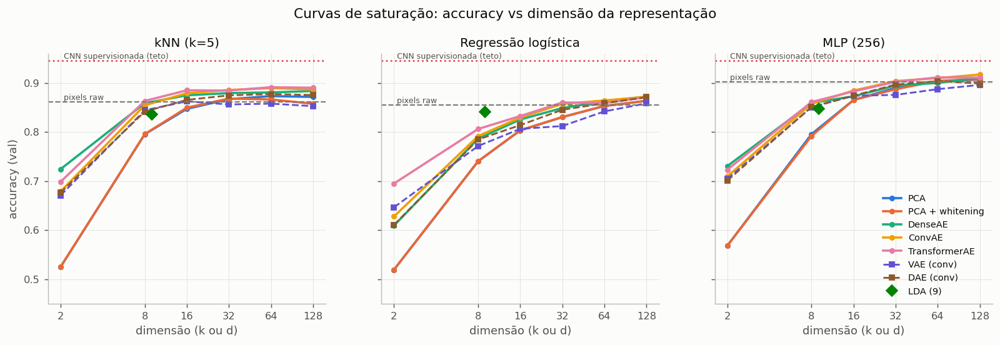

**Figura 38.** Curvas de saturação da accuracy (val) por família e classificador. Ficheiro `outputs/figures/classification_saturation.png`. **Gerada em** `src/classification.py`, função `figures()`, linha 196. **Cálculo:** accuracy de validação por d, família e classificador. **Dados:** `outputs/metrics/classification.csv` (calculado em `src/classification.py`, `run()`, linha 135). **Refazer:** `python -m src.classification`.

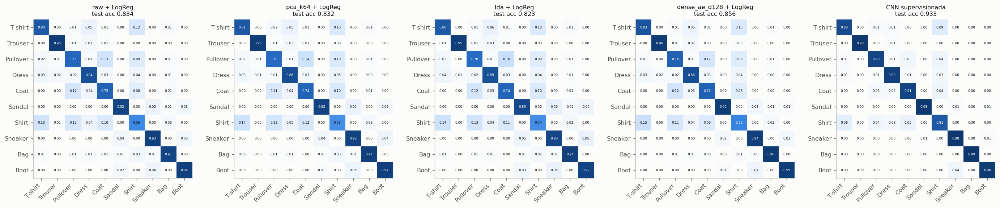

**Figura 39.** Matrizes de confusão normalizadas (test) de espaços representativos. Ficheiro `outputs/figures/classification_confusions.png`. **Gerada em** `src/classification.py`, função `figures()`, linha 213. **Cálculo:** matrizes de confusão normalizadas de espaços representativos. **Dados:** `outputs/metrics/confusion/*.csv` (calculado em `src/classification.py`, `run()`, linha 125). **Refazer:** `python -m src.classification`.

In [35]:
print('Melhores espaços por accuracy de test (LogReg):')
display(c[c.classificador == 'logreg'].nlargest(10, 'test_acc')[['espaco', 'dim', 'val_acc', 'test_acc', 'test_macro_f1']])
display(csv('saturation.csv'))
fig('classification_saturation.png')
fig('classification_confusions.png')

### 5.4 Teto de referência: CNN supervisionada

,params,epochs_run,best_epoch,train_time_s,peak_gpu_mem_mb,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
CNN,140778.0,40.0,39.0,179.1552,818.2485,0.9455,0.9455,0.933,0.9331


Métricas em `outputs/cnn/metrics.json`, **escritas em** `src/train_cnn.py`, função `main()`, linha 111. **Cálculo:** accuracy e macro-F1 em val e test, parâmetros, tempo, memória. **Dados:** `outputs/cnn/best.pt` (calculado em `src/train_cnn.py`, `main()`, linha 85), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_cnn`.

**Tabela 29.** Histórico e métricas (accuracy/macro-F1 val e test) da CNN supervisionada. Ficheiro `outputs/cnn/history.csv`. **Escrita em** `src/train_cnn.py`, função `main()`, linha 114. **Cálculo:** uma linha por época: loss, accuracy de validação, LR, tempo. **Dados:** `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_val_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.train_cnn`.

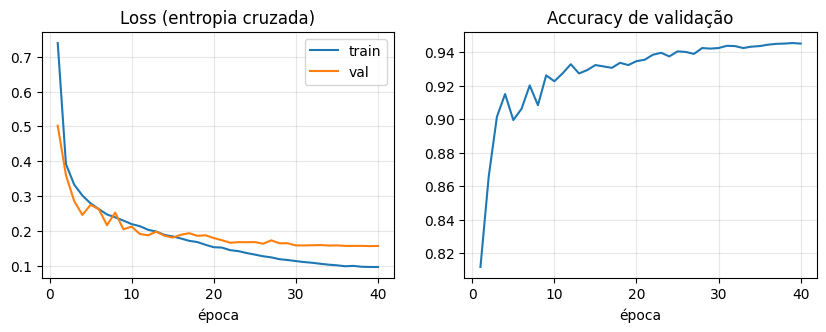

**Figura 40.** Curvas de treino da CNN. **Desenhada** nesta célula, a partir da tabela anterior.

**Tabela 30.** Matrizes de confusão da CNN. Ficheiro `outputs/metrics/cnn_confusion_test.csv`. **Escrita em** `src/train_cnn.py`, função `main()`, linha 109. **Cálculo:** matriz de confusão da CNN (`src/evaluate.py::confusion`). **Dados:** `outputs/cnn/best.pt` (calculado em `src/train_cnn.py`, `main()`, linha 85). **Refazer:** `python -m src.train_cnn`.

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,879,0,14,12,1,0,91,0,3,0
Trouser,0,984,0,11,0,0,3,0,2,0
Pullover,12,1,903,8,32,0,44,0,0,0
Dress,12,3,7,934,15,0,28,0,1,0
Coat,0,0,26,17,913,0,43,0,1,0
Sandal,0,0,0,0,0,980,0,14,0,6
Shirt,77,1,37,25,53,0,805,0,2,0
Sneaker,0,0,0,0,0,6,0,982,0,12
Bag,1,1,2,2,0,2,2,0,990,0
Ankle boot,0,0,0,0,0,3,0,36,1,960


**Tabela 31.** Matrizes de confusão da CNN. Ficheiro `outputs/metrics/cnn_confusion_val.csv`. **Escrita em** `src/train_cnn.py`, função `main()`, linha 109. **Cálculo:** matriz de confusão da CNN (`src/evaluate.py::confusion`). **Dados:** `outputs/cnn/best.pt` (calculado em `src/train_cnn.py`, `main()`, linha 85). **Refazer:** `python -m src.train_cnn`.

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt/top,549,1,3,4,0,0,40,0,3,0
Trouser,0,594,0,4,1,0,1,0,0,0
Pullover,5,0,545,9,20,0,21,0,0,0
Dress,9,3,4,562,12,0,10,0,0,0
Coat,0,1,16,14,545,0,24,0,0,0
Sandal,0,0,0,0,0,594,0,3,0,3
Shirt,42,1,15,5,27,0,508,0,2,0
Sneaker,0,0,0,0,0,2,0,593,0,5
Bag,0,0,1,1,1,1,1,0,595,0
Ankle boot,0,0,0,0,0,2,0,10,0,588


In [36]:
cm = json.loads((OUT / 'cnn' / 'metrics.json').read_text())
MOSTRADAS['tabela']['outputs/cnn/metrics.json'] = 'abaixo'
onde, r = _origem('outputs/cnn/metrics.json')
display(pd.Series(cm).round(4).to_frame('CNN').T)
display(Markdown(f"Métricas em `outputs/cnn/metrics.json`, **escritas em** {onde}. {_texto(r)}."))
hc = csv('cnn/history.csv')
fig_, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hc.epoch, hc.train_loss, label='train'); ax[0].plot(hc.epoch, hc.val_loss, label='val')
ax[0].set_xlabel('época'); ax[0].set_title('Loss (entropia cruzada)'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(hc.epoch, hc.val_acc); ax[1].set_xlabel('época'); ax[1].set_title('Accuracy de validação'); ax[1].grid(alpha=.3)
plt.show()
N['figura'] += 1
MOSTRADAS['figura']['(notebook) curvas da CNN'] = N['figura']
display(Markdown(f"**Figura {N['figura']}.** Curvas de treino da CNN. **Desenhada** nesta célula, a partir da tabela anterior."))
display(csv('cnn_confusion_test.csv', index_col=0))
display(csv('cnn_confusion_val.csv', index_col=0))

### 5.5 Accuracy por classe

In [37]:
espacos = ['raw', 'pca_k64', 'lda', 'hog', 'conv_ae_d32', 'vae_conv_d32', 'dae_conv_d32', 'transformer_ae_d64', 'cnn_emb']
por_classe = {}
for e in espacos:
    M = csv(f'confusion/{e}_knn_test.csv', legenda=False, index_col=0)
    por_classe[e] = M.values.diagonal() / M.values.sum(1)
N['tabela'] += 1
MOSTRADAS['tabela']['outputs/metrics/confusion/ (kNN)'] = N['tabela']
onde, r = _origem(f'outputs/metrics/confusion/{espacos[0]}_knn_test.csv')
display(Markdown(f"**Tabela {N['tabela']}.** Accuracy por classe do kNN no test (diagonal da confusão a dividir pelo total da classe; calculada aqui). Ficheiros `outputs/metrics/confusion/<espaço>_knn_test.csv`, **escritos em** {onde}. {_texto(r)}."))
display(pd.DataFrame(por_classe, index=CLASSES).round(3))

**Tabela 32.** Accuracy por classe do kNN no test (diagonal da confusão a dividir pelo total da classe; calculada aqui). Ficheiros `outputs/metrics/confusion/<espaço>_knn_test.csv`, **escritos em** `src/classification.py`, função `run()`, linha 125. **Cálculo:** matriz de confusão no test, por espaço e classificador (`src/evaluate.py::confusion`). **Dados:** previsões de `src/classification.py::run`. **Refazer:** `python -m src.classification`.

,raw,pca_k64,lda,hog,conv_ae_d32,vae_conv_d32,dae_conv_d32,transformer_ae_d64,cnn_emb
T-shirt/top,0.853,0.834,0.820,0.857,0.857,0.813,0.824,0.854,0.882
Trouser,0.968,0.966,0.962,0.979,0.974,0.963,0.969,0.975,0.982
Pullover,0.813,0.776,0.766,0.825,0.809,0.769,0.795,0.825,0.902
Dress,0.860,0.876,0.844,0.864,0.902,0.867,0.882,0.909,0.930
Coat,0.763,0.778,0.710,0.816,0.801,0.755,0.764,0.799,0.913
Sandal,0.812,0.893,0.879,0.896,0.930,0.900,0.912,0.934,0.986
Shirt,0.577,0.573,0.493,0.633,0.637,0.544,0.594,0.635,0.787
Sneaker,0.961,0.946,0.911,0.972,0.972,0.929,0.951,0.967,0.981
Bag,0.950,0.958,0.941,0.968,0.972,0.959,0.965,0.973,0.992
Ankle boot,0.967,0.963,0.928,0.958,0.964,0.948,0.950,0.968,0.965


**Interpretação.** Shirt é a pior classe em todos estes espaços: a accuracy vai de 0.49 (LDA) a 0.79 (embedding da CNN). É também onde as labels mais ajudam: a CNN ganha 15 p.p. ao ConvAE d=32 (0.79 contra 0.64). O VAE perde mais em Shirt (0.54 contra 0.64 do ConvAE d=32). Trouser e Bag ficam acima de 0.94 em todos estes espaços.

### 5.6 Interpretação

**Interpretação** (os mesmos três classificadores em todos os espaços; o que muda é só a representação).

- **Teto e base:** a CNN supervisionada chega a **0.933** de accuracy no test (0.946 no val). Os pixels raw dão 0.852 (kNN), 0.834 (LogReg) e 0.885 (MLP).
- **Melhor representação não supervisionada:** os latentes dos AEs batem o PCA com o mesmo d nos três classificadores, sobretudo com d pequeno (d=8, kNN no test: 0.845–0.849 nos AEs contra 0.784 no PCA; d=2: 0.68–0.72 contra 0.50). Os melhores resultados no test são do **TransformerAE d=128 no kNN (0.885)** e do **ConvAE d=128 no MLP (0.902)**. Mesmo assim ficam 3–5 p.p. abaixo do teto supervisionado: a reconstrução não obriga o latente a separar as classes de tronco.
- **Classificador × geometria:** no kNN os AEs são claramente superiores (a vizinhança no latente é semanticamente melhor); na regressão logística a vantagem é menor e com d grande quase desaparece (0.853–0.856 nos AEs contra 0.840 no PCA-128 e 0.857 no KernelPCA), porque os latentes são organizados de forma não linear. O MLP recupera essa não linearidade e volta a favorecer os AEs.
- **Saturação:** no kNN a accuracy deixa de subir em **d≈32** no DenseAE e no ConvAE e em d≈64 no PCA e no TransformerAE (na curva fina da Fase 2 o PCA satura em k≈40). Na LogReg e no MLP ainda sobe ligeiramente até 128, mas com ganhos < 1 p.p. a partir de 64. Ou seja, para classificar não vale a pena ir além de d≈32–64.
- **Whitening:** indiferente na LogReg (como previsto, por causa do StandardScaler), ligeiramente melhor no kNN até k=32 e pior a partir de 64.
- **LDA:** com apenas 9 dimensões chega a 0.82–0.83 no test. Na LogReg é melhor do que qualquer representação não supervisionada com d=8 (0.73–0.80), mas no kNN e no MLP os AEs com d=8 já a ultrapassam (0.84–0.85).
- **Confusões:** em todos os espaços, incluindo a CNN, os erros concentram-se em Shirt↔T-shirt/Pullover/Coat; as representações melhores reduzem esses erros, mas não os eliminam.
- **Descritores clássicos (extra):** o **HOG** é surpreendentemente forte (test: kNN 0.877, LogReg 0.871, MLP 0.903), ao nível dos melhores AEs e com a melhor LogReg de todos os espaços não supervisionados: os histogramas de orientação de arestas captam detalhes (golas, carcelas, fechos) que distinguem as classes de tronco. A silhueta binarizada fica perto dos pixels (0.859 no kNN), a LBP abaixo (0.814) e a magnitude Sobel é o pior espaço com dimensão alta (0.730).

**Adenda (VAE e DAE).** O ConvAE base é melhor ou igual em quase todos os casos no test. **kNN:** ConvAE até 0.883, DAE até 0.863, VAE até 0.847. **MLP:** 0.902, 0.887 e 0.885. **LogReg:** há duas exceções, o VAE em d=2 (0.635 contra 0.615) e o DAE em d=128 (0.859 contra 0.853). **Saturação (kNN, val):** o VAE satura mais cedo (d=16), coerente com a capacidade limitada vista em 4.4; DAE e ConvAE em d=32. Na LogReg o VAE ainda sobe até d=128 (0.794 → 0.844 de d=16 a d=128) com o MSE parado, provavelmente porque o StandardScaler amplifica dimensões de pouca variância que ainda têm alguma informação. Nenhum especializado altera o melhor resultado não supervisionado.

<a id='fase-6'></a>

## Fase 6: Retrieval por semelhança

**Método e código** (`src/retrieval.py`).
- **Função pedida:** `src/retrieval.py::retrieve` recebe `(query_image, space, k, metric)`, projeta a query com o `embed` do espaço e devolve os índices e as distâncias na galeria (train, 54 000). `src/retrieval.py::available_spaces` lista os espaços; `src/retrieval.py::_registry` regista-os e carrega os `.npy` e os modelos de `outputs/`. Os latentes dos AEs vêm de `src/representation.py::ae_encode`. As labels nunca entram no ranking.
- **Perspetivas:**
  - *shape:* pixels, silhueta binária com limiar 0.1 (`src/retrieval.py::feat_silhouette`), PCA, IPCA e KPCA;
  - *texture/edges:* magnitude de Sobel (`src/retrieval.py::feat_sobel`), HOG com 9 orientações, células 4×4 e blocos 2×2, 1296 dimensões (`src/retrieval.py::feat_hog`), LBP uniforme P=8 R=1 em 4×4 células, 160 dimensões (`src/retrieval.py::feat_lbp`);
  - *learned:* latentes dos AEs;
  - *supervised:* LDA e embedding da CNN, só como referência, porque usam labels no ajuste.
- **Distâncias:** euclidiana com `torch.cdist` e cosseno, em blocos na GPU (`src/evaluate.py::pairwise_dist`).
- **Queries** (`src/retrieval.py::query_indices`): 2000 estratificadas do test; 500 delas para a proxy visual.
- **Métricas com labels** (`src/retrieval.py::label_metrics`), para k ∈ {1, 5, 10, 20}:
  - `precision@k`: fração do top-k com a classe da query;
  - `consistency@k`: 1 se a classe maioritária do top-k for a da query;
  - `map@k`: soma de P(i)·rel(i) até k, a dividir por k;
  - `map`: precisão média em toda a galeria.
- **Proxy visual sem labels** (`src/retrieval.py::proxy_cache`, `src/retrieval.py::proxy_metrics`): SSIM (`src/evaluate.py::SSIMGallery`) e IoU de silhueta (`src/evaluate.py::silhouette_iou`) de cada query contra toda a galeria. Daqui saem SSIM e IoU médios do top-k, NDCG@10 com ganho = SSIM ou IoU e Spearman entre −distância e a proxy, em 1000 imagens aleatórias por query.
- **Classificar vs semelhança** (`src/retrieval.py::compare_with_classification`): Spearman e Kendall entre os rankings de espaços, com e sem d=2.
- **Painéis** (`src/retrieval.py::panels`): top-8 de 6 queries em 12 espaços, com distância euclidiana; moldura vermelha = classe diferente.

### 6.1 Resultados por espaço e distância

In [38]:
r = csv('retrieval.csv')
cols = ['espaco', 'perspetiva', 'dim', 'metrica', 'precision@1', 'precision@10', 'consistency@10', 'map@10', 'map',
        'ssim@10', 'iou@10', 'ndcg@10_ssim', 'spearman_ssim']
display(r[cols].sort_values(['metrica', 'map'], ascending=[True, False]).reset_index(drop=True))

**Tabela 33.** Métricas de retrieval por (espaço, métrica): precision@k, class-consistency@k, mAP@k, mAP, SSIM/IoU@k, NDCG@10 e Spearman com a proxy visual (coluna specialized = VAE/DAE da adenda). Ficheiro `outputs/metrics/retrieval.csv`. **Escrita em** `src/retrieval.py`, função `evaluate_all()`, linha 302. **Cálculo:** P@k, consistency@k, mAP (`src/retrieval.py::label_metrics`) e proxy visual (`src/retrieval.py::proxy_metrics`), por espaço e distância. **Dados:** espaços de `src/retrieval.py::_registry`, `outputs/retrieval/*.npy` (calculado em `src/retrieval.py`, `proxy_cache()`, linha 229). **Refazer:** `python -m src.retrieval`.

,espaco,perspetiva,dim,metrica,precision@1,precision@10,consistency@10,map@10,map,ssim@10,iou@10,ndcg@10_ssim,spearman_ssim
0,cnn,supervised,128,cosine,0.9240,0.9219,0.9290,0.9083,0.8755,0.4617,0.7588,0.6507,0.4647
1,lda,supervised,9,cosine,0.7810,0.7854,0.8305,0.7290,0.7167,0.4497,0.7393,0.6272,0.6217
2,conv_ae_d8,learned,8,cosine,0.8200,0.8001,0.8500,0.7459,0.5509,0.5936,0.8512,0.8480,0.6756
3,conv_ae_d16,learned,16,cosine,0.8750,0.8299,0.8700,0.7851,0.5470,0.6209,0.8611,0.8930,0.7346
4,dae_conv_d16,learned,16,cosine,0.8440,0.8164,0.8630,0.7686,0.5382,0.6255,0.8482,0.8990,0.7669
...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,pca_k2,shape,2,euclidean,0.4490,0.4539,0.5335,0.3269,0.3391,0.3752,0.6897,0.5235,0.5613
98,pca_k32_whiten,shape,32,euclidean,0.8485,0.8025,0.8590,0.7491,0.3087,0.6252,0.8409,0.9013,0.2233
99,sobel,texture,784,euclidean,0.6920,0.6296,0.7300,0.5405,0.2753,0.5009,0.7698,0.7095,0.3255
100,pca_k64_whiten,shape,64,euclidean,0.8605,0.8113,0.8645,0.7622,0.2423,0.6316,0.8420,0.9112,0.1546


In [39]:
print('Todos os k pedidos (k = 1, 5, 10, 20): os 12 melhores espaços por mAP, distância euclidiana:')
topk = r[r.metrica == 'euclidean'].nlargest(12, 'map').set_index('espaco')
display(topk[[f'{m}@{k}' for m in ('precision', 'consistency', 'map') for k in (1, 5, 10, 20)]].round(3))
print('O CSV tem as mesmas colunas para todos os espaços e para as duas distâncias.')

Todos os k pedidos (k = 1, 5, 10, 20): os 12 melhores espaços por mAP, distância euclidiana:


,precision@1,precision@5,precision@10,precision@20,consistency@1,consistency@5,consistency@10,consistency@20,map@1,map@5,map@10,map@20
espaco,,,,,,,,,,,,
cnn,0.927,0.922,0.921,0.920,0.927,0.928,0.928,0.929,0.927,0.912,0.906,0.902
lda,0.784,0.792,0.787,0.783,0.784,0.835,0.836,0.836,0.784,0.745,0.730,0.718
conv_ae_d8,0.814,0.803,0.797,0.788,0.814,0.842,0.844,0.840,0.814,0.761,0.740,0.720
conv_ae_d16,0.860,0.838,0.828,0.814,0.860,0.870,0.872,0.872,0.860,0.805,0.781,0.756
transformer_ae_d16,0.854,0.832,0.822,0.810,0.854,0.865,0.883,0.873,0.854,0.797,0.772,0.749
conv_ae_d32,0.873,0.849,0.837,0.823,0.873,0.890,0.888,0.876,0.873,0.818,0.793,0.769
silhouette,0.844,0.828,0.814,0.801,0.844,0.858,0.854,0.849,0.844,0.792,0.766,0.743
hog,0.858,0.847,0.834,0.820,0.858,0.886,0.886,0.878,0.858,0.811,0.787,0.763
transformer_ae_d8,0.832,0.813,0.804,0.797,0.832,0.854,0.852,0.858,0.832,0.772,0.749,0.730


O CSV tem as mesmas colunas para todos os espaços e para as duas distâncias.


### 6.2 O melhor a classificar é o melhor em semelhança visual?

precision@10     map  ndcg@10_ssim  spearman_ssim
perspetiva metrica                                                     
learned    cosine           0.8437  0.5509        0.9517         0.7903
           euclidean        0.8388  0.5199        0.9466         0.7162
shape      cosine           0.8302  0.4782        0.9418         0.6909
           euclidean        0.8143  0.5043        0.9439         0.7924
supervised cosine           0.9219  0.8755        0.6507         0.6217
           euclidean        0.9211  0.8469        0.6459         0.4590
texture    cosine           0.8347  0.4952        0.8355         0.6711
           euclidean        0.8344  0.4972        0.8354         0.6911

**Tabela 34.** Retrieval vs classificação por espaço e correlação entre os rankings de espaços. Ficheiro `outputs/metrics/retrieval_vs_classification.csv`. **Escrita em** `src/retrieval.py`, função `compare_with_classification()`, linha 330. **Cálculo:** junta a accuracy de classificação às métricas de retrieval (euclidiana). **Dados:** `outputs/metrics/retrieval.csv` (calculado em `src/retrieval.py`, `evaluate_all()`, linha 302), `outputs/metrics/classification.csv` (calculado em `src/classification.py`, `run()`, linha 135). **Refazer:** `python -m src.retrieval`.

,espaco,perspetiva,dim,knn,logreg,precision@10,map,ndcg@10_ssim,ndcg@10_iou,spearman_ssim,spearman_iou,ssim@10,iou@10,specialized
0,cnn,supervised,128,0.9457,0.9422,0.9211,0.8469,0.6459,0.8427,0.4201,0.4585,0.4579,0.7565,False
1,kpca_rbf_k128,shape,128,0.8732,0.8753,0.8101,0.4593,0.9216,0.9501,0.6001,0.5602,0.6390,0.8470,False
2,hog,texture,1296,0.8817,0.8750,0.8344,0.4972,0.8354,0.9319,0.6187,0.7545,0.5820,0.8309,False
3,dense_ae_d128,learned,128,0.8838,0.8722,0.8284,0.4398,0.9339,0.9590,0.5796,0.7403,0.6460,0.8545,False
4,conv_ae_d128,learned,128,0.8868,0.8722,0.8346,0.4532,0.9466,0.9621,0.5828,0.5755,0.6536,0.8571,False
5,dae_conv_d128,learned,128,0.8755,0.8713,0.8179,0.4302,0.9175,0.9480,0.4763,0.4196,0.6367,0.8463,True
6,transformer_ae_d128,learned,128,0.8903,0.8710,0.8379,0.4843,0.9420,0.9603,0.6800,0.7214,0.6511,0.8555,False
7,conv_ae_d64,learned,64,0.8897,0.8643,0.8388,0.4863,0.9370,0.9618,0.6256,0.6652,0.6478,0.8567,False
8,pca_k128,shape,128,0.8717,0.8638,0.8116,0.4510,0.9361,0.9556,0.6100,0.5591,0.6474,0.8518,False
9,pca_k128_whiten,shape,128,0.8577,0.8635,0.7974,0.1905,0.8969,0.9350,0.1196,0.1137,0.6215,0.8317,False


**Tabela 35.** Retrieval vs classificação por espaço e correlação entre os rankings de espaços. Ficheiro `outputs/metrics/retrieval_rank_agreement.csv`. **Escrita em** `src/retrieval.py`, função `compare_with_classification()`, linha 343. **Cálculo:** Spearman e Kendall entre rankings de espaços, com e sem d=2. **Dados:** `outputs/metrics/retrieval_vs_classification.csv` (calculado em `src/retrieval.py`, `compare_with_classification()`, linha 330). **Refazer:** `python -m src.retrieval`.

,subconjunto,n_espacos,criterio_a,criterio_b,spearman_entre_espacos,p_valor,kendall
0,todos,51,knn,ndcg@10_ssim,0.7713,3.5193e-11,0.6706
1,todos,51,knn,spearman_ssim,0.3918,4.4690e-03,0.2627
2,todos,50,knn,ndcg@10_iou,0.8205,3.0392e-13,0.7094
3,todos,50,knn,spearman_iou,0.2550,7.3872e-02,0.1445
4,todos,51,logreg,ndcg@10_ssim,0.7057,7.3073e-09,0.5973
5,todos,51,logreg,spearman_ssim,0.1855,1.9253e-01,0.1154
6,todos,50,logreg,ndcg@10_iou,0.6808,5.3095e-08,0.5417
7,todos,50,logreg,spearman_iou,0.0443,7.5988e-01,0.0319
8,todos,51,precision@10,ndcg@10_ssim,0.7656,5.9867e-11,0.6596
9,todos,51,precision@10,spearman_ssim,0.3885,4.8428e-03,0.2455


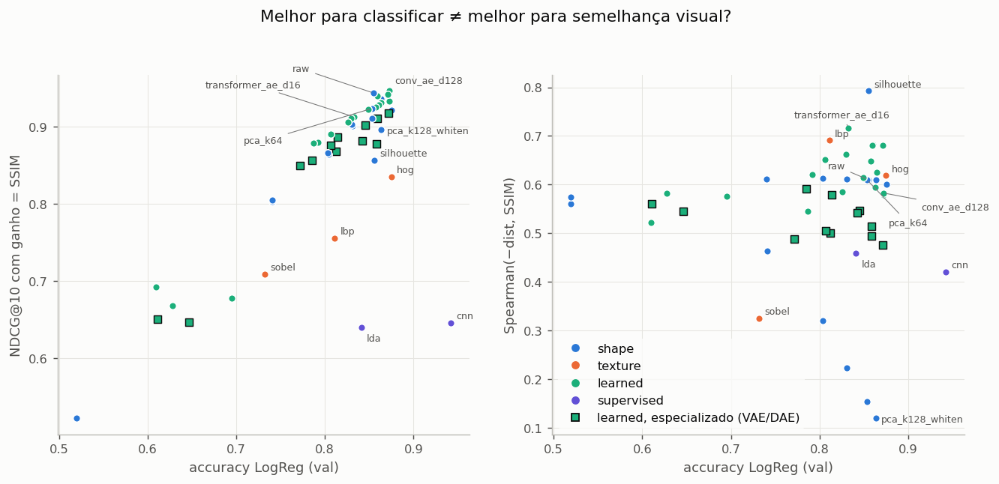

**Figura 41.** Accuracy de classificação vs concordância com a proxy visual. Ficheiro `outputs/figures/retrieval_vs_classification.png`. **Gerada em** `src/retrieval.py`, função `compare_with_classification()`, linha 371. **Cálculo:** accuracy de classificação vs concordância com a proxy visual, por espaço. **Dados:** `outputs/metrics/retrieval_vs_classification.csv` (calculado em `src/retrieval.py`, `compare_with_classification()`, linha 330). **Refazer:** `python -m src.retrieval`.

In [40]:
display(r.groupby(['perspetiva', 'metrica'])[['precision@10', 'map', 'ndcg@10_ssim', 'spearman_ssim']].max())
rc = csv('retrieval_vs_classification.csv'); display(rc)
display(csv('retrieval_rank_agreement.csv'))
fig('retrieval_vs_classification.png')

### 6.3 ConvAE base, VAE e DAE

In [41]:
print('Retrieval com distância euclidiana, por d:')
re_ = r[(r.metrica == 'euclidean') & r.espaco.str.match(r'(conv_ae|vae_conv|dae_conv)_d')].copy()
re_['modelo'] = re_.espaco.str.rsplit('_d', n=1).str[0]
display(re_.pivot(index='dim', columns='modelo', values=['precision@10', 'map', 'ndcg@10_ssim', 'spearman_ssim'])
           .reindex(columns=['conv_ae', 'vae_conv', 'dae_conv'], level=1))

Retrieval com distância euclidiana, por d:


precision@10                       map                   ndcg@10_ssim                   spearman_ssim                  
modelo      conv_ae vae_conv dae_conv conv_ae vae_conv dae_conv      conv_ae vae_conv dae_conv       conv_ae vae_conv dae_conv
dim                                                                                                                           
2            0.6285   0.6138   0.6174  0.4477   0.4382   0.4423       0.6684   0.6473   0.6510        0.5816   0.5450   0.5604
8            0.7966   0.7830   0.7812  0.5199   0.3955   0.4869       0.8803   0.8497   0.8566        0.6201   0.4889   0.5916
16           0.8275   0.7926   0.8061  0.5192   0.4049   0.4827       0.9107   0.8766   0.8873        0.6618   0.5058   0.5791
32           0.8369   0.7940   0.8155  0.5075   0.3849   0.4661       0.9261   0.8687   0.9026        0.6480   0.5011   0.5472
64           0.8388   0.7940   0.8176  0.4863   0.4010   0.4435       0.9370   0.8823   0.9115        0.6256   0.5420   0.4942
128          0.8346   0.7918   0.8179  0.4532   0.4025   0.4302       0.9466   0.8784   0.9175        0.5828   0.5137   0.4763

### 6.4 Exemplos de queries

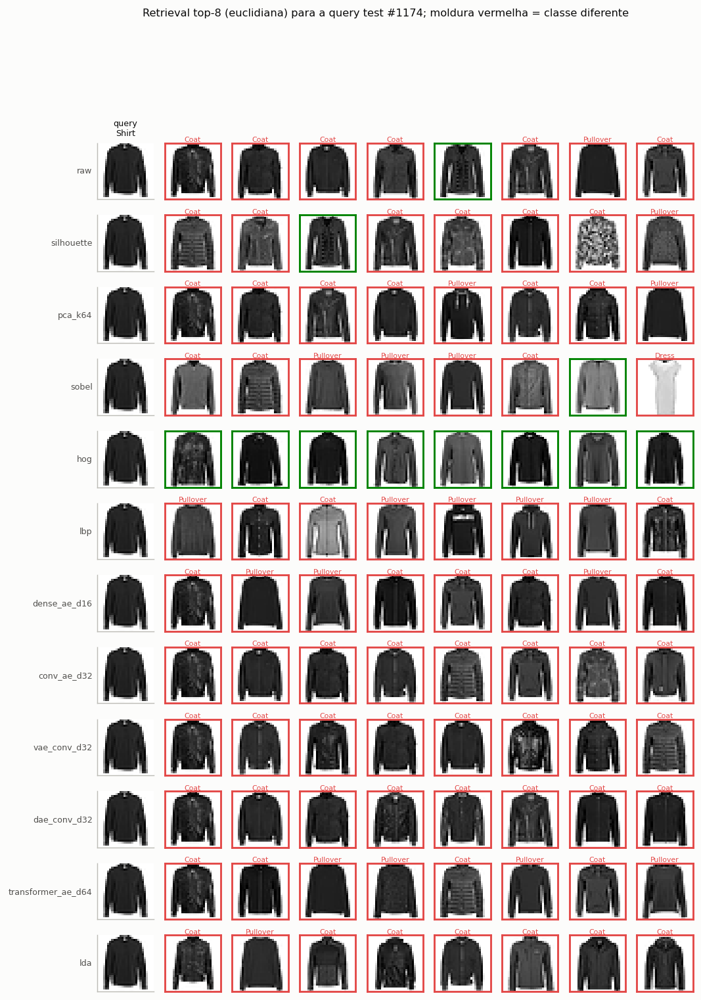

**Figura 42.** Painel de retrieval (query test 1174) em vários espaços. Ficheiro `outputs/figures/retrieval_panel_q1174.png`. **Gerada em** `src/retrieval.py`, função `panels()`, linha 410. **Cálculo:** query e top-8 em 12 espaços, com `src/retrieval.py::retrieve` (euclidiana). **Dados:** `outputs/retrieval/query_idx_test.npy` (calculado em `src/retrieval.py`, `query_indices()`, linha 186), espaços de `src/retrieval.py::_registry`. **Refazer:** `python -m src.retrieval`.

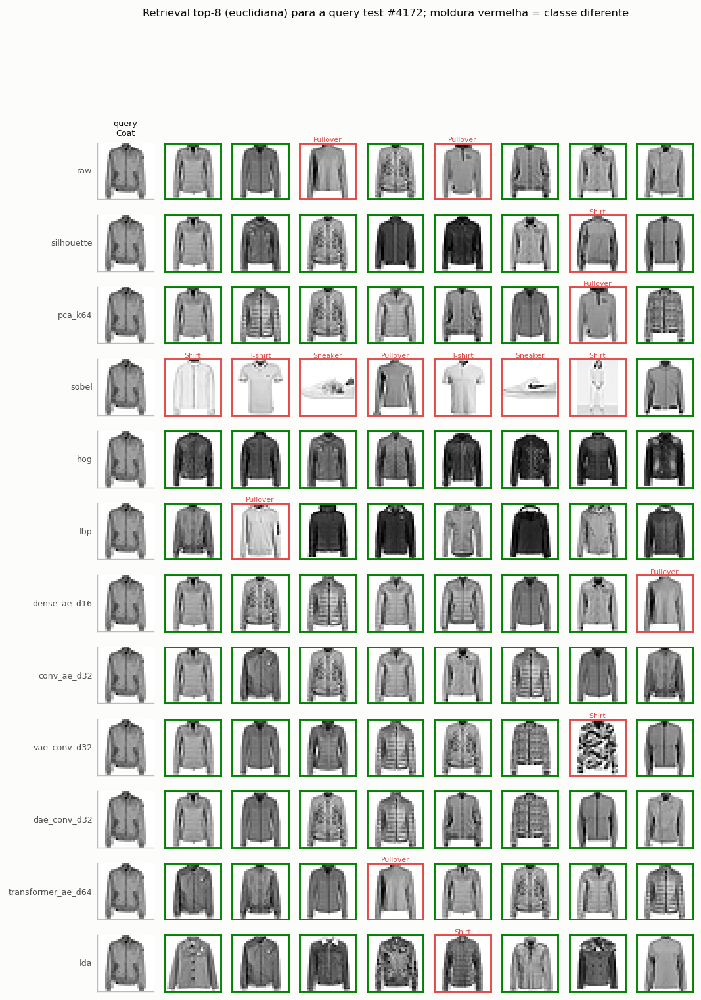

**Figura 43.** Painel de retrieval (query test 4172) em vários espaços. Ficheiro `outputs/figures/retrieval_panel_q4172.png`. **Gerada em** `src/retrieval.py`, função `panels()`, linha 410. **Cálculo:** query e top-8 em 12 espaços, com `src/retrieval.py::retrieve` (euclidiana). **Dados:** `outputs/retrieval/query_idx_test.npy` (calculado em `src/retrieval.py`, `query_indices()`, linha 186), espaços de `src/retrieval.py::_registry`. **Refazer:** `python -m src.retrieval`.

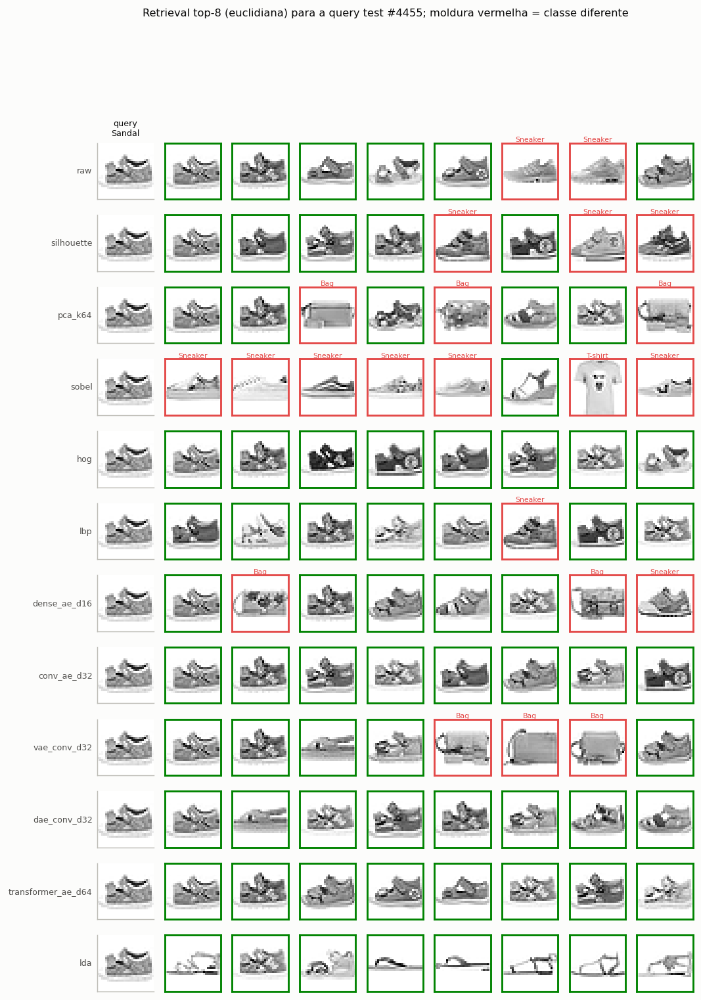

**Figura 44.** Painel de retrieval (query test 4455) em vários espaços. Ficheiro `outputs/figures/retrieval_panel_q4455.png`. **Gerada em** `src/retrieval.py`, função `panels()`, linha 410. **Cálculo:** query e top-8 em 12 espaços, com `src/retrieval.py::retrieve` (euclidiana). **Dados:** `outputs/retrieval/query_idx_test.npy` (calculado em `src/retrieval.py`, `query_indices()`, linha 186), espaços de `src/retrieval.py::_registry`. **Refazer:** `python -m src.retrieval`.

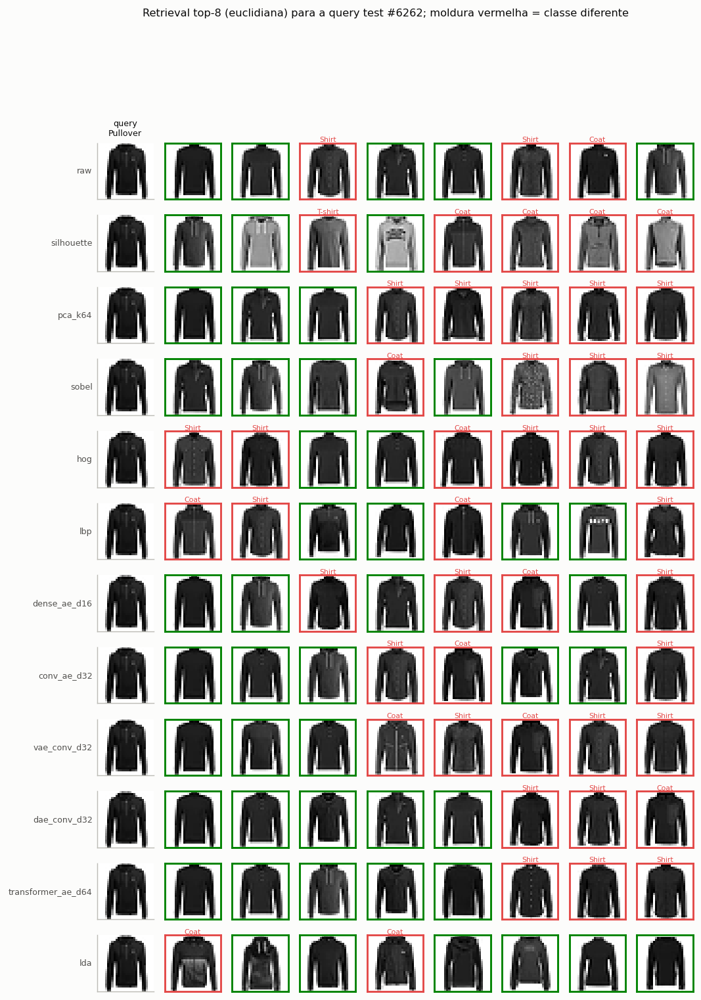

**Figura 45.** Painel de retrieval (query test 6262) em vários espaços. Ficheiro `outputs/figures/retrieval_panel_q6262.png`. **Gerada em** `src/retrieval.py`, função `panels()`, linha 410. **Cálculo:** query e top-8 em 12 espaços, com `src/retrieval.py::retrieve` (euclidiana). **Dados:** `outputs/retrieval/query_idx_test.npy` (calculado em `src/retrieval.py`, `query_indices()`, linha 186), espaços de `src/retrieval.py::_registry`. **Refazer:** `python -m src.retrieval`.

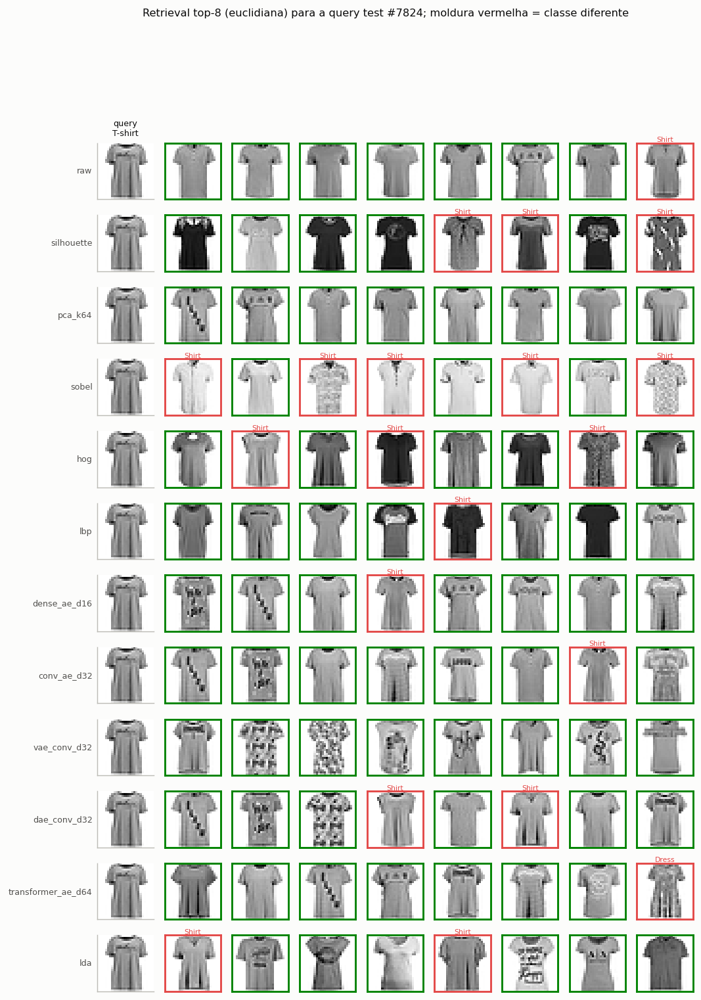

**Figura 46.** Painel de retrieval (query test 7824) em vários espaços. Ficheiro `outputs/figures/retrieval_panel_q7824.png`. **Gerada em** `src/retrieval.py`, função `panels()`, linha 410. **Cálculo:** query e top-8 em 12 espaços, com `src/retrieval.py::retrieve` (euclidiana). **Dados:** `outputs/retrieval/query_idx_test.npy` (calculado em `src/retrieval.py`, `query_indices()`, linha 186), espaços de `src/retrieval.py::_registry`. **Refazer:** `python -m src.retrieval`.

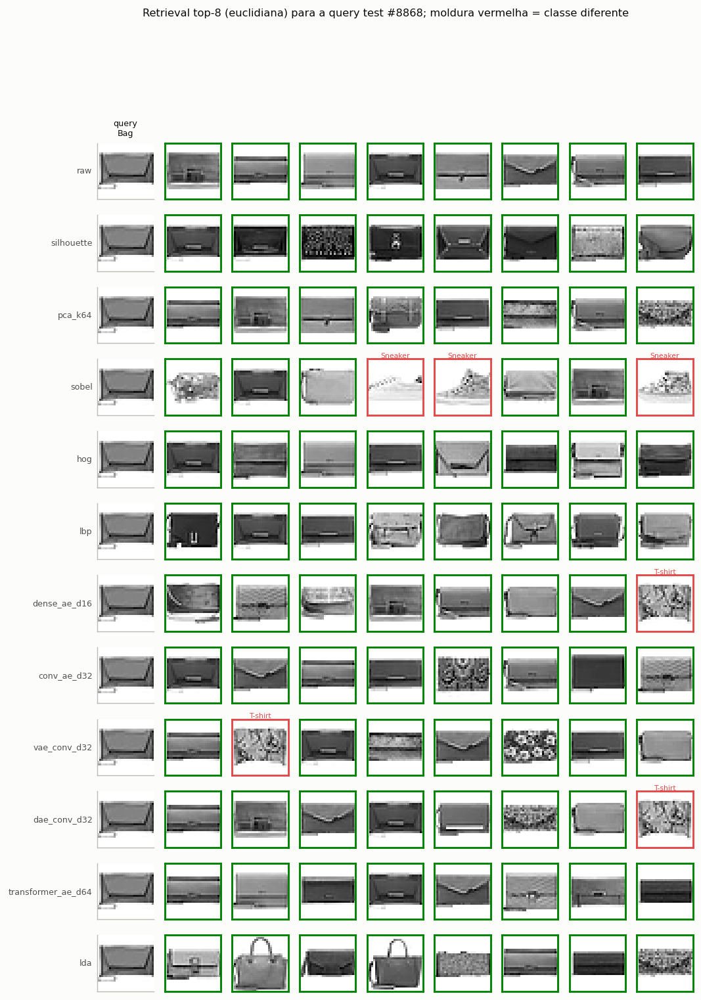

**Figura 47.** Painel de retrieval (query test 8868) em vários espaços. Ficheiro `outputs/figures/retrieval_panel_q8868.png`. **Gerada em** `src/retrieval.py`, função `panels()`, linha 410. **Cálculo:** query e top-8 em 12 espaços, com `src/retrieval.py::retrieve` (euclidiana). **Dados:** `outputs/retrieval/query_idx_test.npy` (calculado em `src/retrieval.py`, `query_indices()`, linha 186), espaços de `src/retrieval.py::_registry`. **Refazer:** `python -m src.retrieval`.

In [42]:
for p in sorted(FIG.glob('retrieval_panel_q*.png')):
    fig(p.name, width=640)

### 6.5 Interpretação

Galeria = train (54k), 2 000 queries do test; as labels só entram na avaliação.

- **Retrieval por classe (precision@k, mAP):** os espaços supervisionados dominam (CNN: P@10 0.92, mAP 0.85; LDA: mAP 0.68). Entre os não supervisionados, os AEs com d intermédio têm o melhor mAP (ConvAE d=8/16: 0.52; TransformerAE d=16: 0.52), acima de raw (0.45), PCA (0.45–0.46) e HOG (0.50); no top-10 o ConvAE d=64 e o TransformerAE d=128 chegam a P@10 0.84, empatados com o HOG (0.83). O mAP sobre a galeria inteira é muito mais baixo do que o P@10 em todos os espaços não supervisionados: a vizinhança próxima é boa, mas a estrutura global não segue as classes.
- **Distância:** o cosseno melhora o mAP em 41 de 51 espaços (sobretudo PCA com whitening, +0.08, e DenseAE, +0.05). Piora nos espaços com d=2 (até −15 p.p., porque aí a norma carrega muita da informação), na silhueta (−2.8 p.p.) e, de forma marginal (< 0.5 p.p.), no HOG, na LBP e no TransformerAE d=8.
- **Whitening:** quase não altera o P@10, mas destrói a ordenação global (mAP 0.45 → 0.19 e Spearman com o SSIM 0.61 → 0.12 em k=128): ao dar o mesmo peso a componentes de ruído, as distâncias grandes deixam de ter significado.
- **Perspetivas:** pixels, PCA (sem whitening, k ≥ 32) e AEs base com d ≥ 16 recuperam as imagens visualmente mais parecidas (NDCG@10 com ganho SSIM 0.90–0.95); a silhueta binarizada perde o interior das peças (0.86); *texture/edges* recupera imagens da mesma classe com aspeto diferente (HOG: P@10 alto mas NDCG-SSIM 0.84); a magnitude Sobel isolada é fraca em tudo. Nos painéis vê-se bem a diferença: para uma Shirt escura com ar de casaco, pixels, PCA e AEs devolvem Coats escuros (visualmente certos, semanticamente errados), enquanto o HOG devolve 8/8 Shirts.
- **Melhor para classificar ≠ melhor para retrieval visual:** a CNN supervisionada e a LDA, que são os melhores espaços para classificar e para o retrieval por classe, são os **piores na proxy visual** (NDCG-SSIM 0.65 e 0.64, ao nível dos espaços com d=2): agrupam imagens da mesma classe que não se parecem. Sem os espaços d=2 (44 espaços, com os especializados), a correlação entre espaços da accuracy LogReg com a concordância global com o SSIM é baixa e não significativa (Spearman ρ = 0.11, p = 0.49; só com os espaços base era 0.03), e o mAP por classe não se relaciona com o NDCG-SSIM (ρ = −0.02, p = 0.93). Há correlação moderada da accuracy com o NDCG-SSIM do top-10 (ρ = 0.59 na LogReg, 0.68 no kNN), porque espaços muito maus (PCA-8, Sobel) falham nas duas coisas; mas no topo os rankings divergem. **Os melhores compromissos são os AEs**: o ConvAE d=32 tem mAP 0.51 e NDCG-SSIM 0.93, e o TransformerAE d=16 tem o melhor Spearman com o SSIM entre os espaços aprendidos (0.72).
- **Ressalvas da proxy:** o SSIM e a IoU são calculados em pixels, por isso favorecem raw (SSIM) e, de forma circular, a silhueta binarizada (IoU): a silhueta é excluída das correlações com a IoU. Mesmo assim, a conclusão sobre os espaços supervisionados não depende disso.

**Adenda (VAE e DAE).** Com d ≥ 8 e distância euclidiana, o ConvAE base é melhor nas quatro medidas: P@10 0.80–0.84, mAP 0.45–0.52, NDCG-SSIM 0.88–0.95 e Spearman 0.58–0.66. O DAE fica no meio (P@10 0.78–0.82, mAP 0.43–0.49, NDCG-SSIM 0.86–0.92; Spearman 0.48–0.59) e o VAE atrás (P@10 de cerca de 0.79, mAP 0.39–0.41, NDCG-SSIM 0.85–0.88; Spearman 0.49–0.54). A única vantagem clara do DAE no retrieval é com queries ruidosas (ver 4.4); com queries limpas, o ConvAE é a melhor escolha. O latente regular do VAE não trouxe ganho no retrieval, ao contrário do que H1 admitia como possível.

<a id="fase-7"></a>

## Fase 7: Extensão de cor (não realizada)

O enunciado exclui esta fase. Não foi descarregado nenhum dataset de cor.

<a id="fase-8"></a>

## Fase 8: Análise de falhas

**Método e código** (`src/failures.py`; espaços em `config.yaml`, secção `failures`).
- **Mineração** (`src/failures.py::mine`), sem escolha manual:
  - *vizinho de classe diferente:* para cada imagem do test, o 1-NN no train (`src/evaluate.py::knn_search`); ficam os 12 pares errados de menor distância, sem repetir a imagem do train;
  - *mesma classe distante:* para cada classe, o par do test mais afastado (`src/evaluate.py::pairwise_dist`), 10 pares por espaço.
- **Causa provável** (`src/failures.py::cause`), por regras, sem olhar para o modelo:
  - classes de tronco trocadas → ambiguidade entre classes de tronco;
  - Sandal, Sneaker e Ankle boot trocados → calçado de forma semelhante;
  - outra troca com IoU ≥ 0.75 → silhueta semelhante; caso contrário, outra troca entre classes;
  - mesma classe com brilho médio mais de 2× diferente → brilho/contraste;
  - mesma classe com IoU < 0.5 → forma ou estilo diferente; caso contrário, padrão ou textura. A IoU vem de `src/failures.py::iou`.
- **Figuras** (`src/failures.py::figure_by_cause`): uma por causa, com até 16 pares.
- **Comparação na adenda** (`src/failures.py::compare_spaces`): usa todos os erros 1-NN das 10 000 imagens do test, não só os casos minados; conta os pares de classes e calcula o Jaccard entre conjuntos de imagens falhadas.

Estas causas são hipóteses dadas por regras simples. Servem para agrupar os casos, não provam a causa de cada erro.

### 8.1 Casos minados e causas prováveis

**Tabela 36.** Casos de falha minados automaticamente (índices, classes, distâncias, causa provável), resumo por causa e casos partilhados entre espaços. Ficheiro `outputs/failures/failure_cases.csv`. **Escrita em** `src/failures.py`, função `main()`, linha 179. **Cálculo:** mineração automática (`src/failures.py::mine`) e causa provável (`src/failures.py::cause`). **Dados:** features de train/test dos 6 espaços. **Refazer:** `python -m src.failures`.

**Tabela 37.** Casos de falha minados automaticamente (índices, classes, distâncias, causa provável), resumo por causa e casos partilhados entre espaços. Ficheiro `outputs/failures/failure_causes_summary.csv`. **Escrita em** `src/failures.py`, função `main()`, linha 182. **Cálculo:** nº de casos por tipo e causa. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179). **Refazer:** `python -m src.failures`.

,tipo,causa,n
0,mesma_classe_distante,diferença de brilho/contraste,15
1,mesma_classe_distante,forma/estilo diferente dentro da classe,40
2,mesma_classe_distante,padrão/textura diferente,5
3,vizinho_classe_diferente,ambiguidade entre classes de tronco,47
4,vizinho_classe_diferente,calçado de forma semelhante,2
5,vizinho_classe_diferente,outra troca entre classes,7
6,vizinho_classe_diferente,silhueta semelhante entre classes,16


causa                                  ambiguidade entre classes de tronco  calçado de forma semelhante  diferença de brilho/contraste  forma/estilo diferente dentro da classe  \
espaco       tipo                                                                                                                                                                 
conv_ae_d32  mesma_classe_distante                                       0                            0                              0                                       10   
             vizinho_classe_diferente                                   10                            0                              0                                        0   
dae_conv_d32 mesma_classe_distante                                       0                            0                              0                                        9   
             vizinho_classe_diferente                                    9                            0                              0                                        0   
hog          mesma_classe_distante                                       0                            0                              0                                        8   
             vizinho_classe_diferente                                    0                            0                              0                                        0   
pca_k64      mesma_classe_distante                                       0                            0                              8                                        2   
             vizinho_classe_diferente                                    9                            1                              0                                        0   
raw          mesma_classe_distante                                       0                            0                              7                                        3   
             vizinho_classe_diferente                                   10                            0                              0                                        0   
vae_conv_d32 mesma_classe_distante                                       0                            0                              0                                        8   
             vizinho_classe_diferente                                    9                            1                              0                                        0   

causa                                  outra troca entre classes  padrão/textura diferente  silhueta semelhante entre classes  
espaco       tipo                                                                                                              
conv_ae_d32  mesma_classe_distante                             0                         0                                  0  
             vizinho_classe_diferente                          0                         0                                  2  
dae_conv_d32 mesma_classe_distante                             0                         1                                  0  
             vizinho_classe_diferente                          2                         0                                  1  
hog          mesma_classe_distante                             0                         2                                  0  
             vizinho_classe_diferente                          4                         0                                  8  
pca_k64      mesma_classe_distante                             0                         0                                  0  
             vizinho_classe_diferente                          0                         0                                  2  
raw          mesma_classe_distante                             0                         0                                  0  
             vizinho_classe_diferente                          0                     

,espaco,tipo,idx_a,idx_b,nome_a,nome_b,distancia,iou_silhueta,causa
0,raw,vizinho_classe_diferente,8007,41176,T-shirt,Shirt,1.6894,0.8105,ambiguidade entre classes de tronco
1,raw,vizinho_classe_diferente,4453,19820,Shirt,T-shirt,1.7132,0.9465,ambiguidade entre classes de tronco
2,raw,vizinho_classe_diferente,4024,7387,T-shirt,Shirt,1.7552,0.2941,ambiguidade entre classes de tronco
3,raw,vizinho_classe_diferente,926,15572,T-shirt,Shirt,1.7565,0.8286,ambiguidade entre classes de tronco
4,raw,vizinho_classe_diferente,4469,12893,T-shirt,Coat,1.8069,0.0704,ambiguidade entre classes de tronco
5,raw,vizinho_classe_diferente,9859,35371,Shirt,T-shirt,1.8320,0.4726,ambiguidade entre classes de tronco
6,raw,vizinho_classe_diferente,3531,14867,T-shirt,Dress,1.9399,0.9537,silhueta semelhante entre classes
7,raw,vizinho_classe_diferente,6103,15394,Coat,Shirt,1.9411,0.3563,ambiguidade entre classes de tronco
8,raw,vizinho_classe_diferente,2290,34996,Shirt,T-shirt,1.9838,0.9589,ambiguidade entre classes de tronco
9,raw,vizinho_classe_diferente,293,1653,Shirt,T-shirt,1.9839,0.7943,ambiguidade entre classes de tronco


**Tabela 38.** Casos de falha minados automaticamente (índices, classes, distâncias, causa provável), resumo por causa e casos partilhados entre espaços. Ficheiro `outputs/failures/failures_shared_across_spaces.csv`. **Escrita em** `src/failures.py`, função `main()`, linha 186. **Cálculo:** imagens do test minadas em mais do que um espaço. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179). **Refazer:** `python -m src.failures`.

,idx_a,n_espacos
3,2290,5
11,8007,5
1,926,3
5,3531,3
7,4453,3
10,6444,3
6,4024,3
0,787,2
2,1731,2
4,2309,2


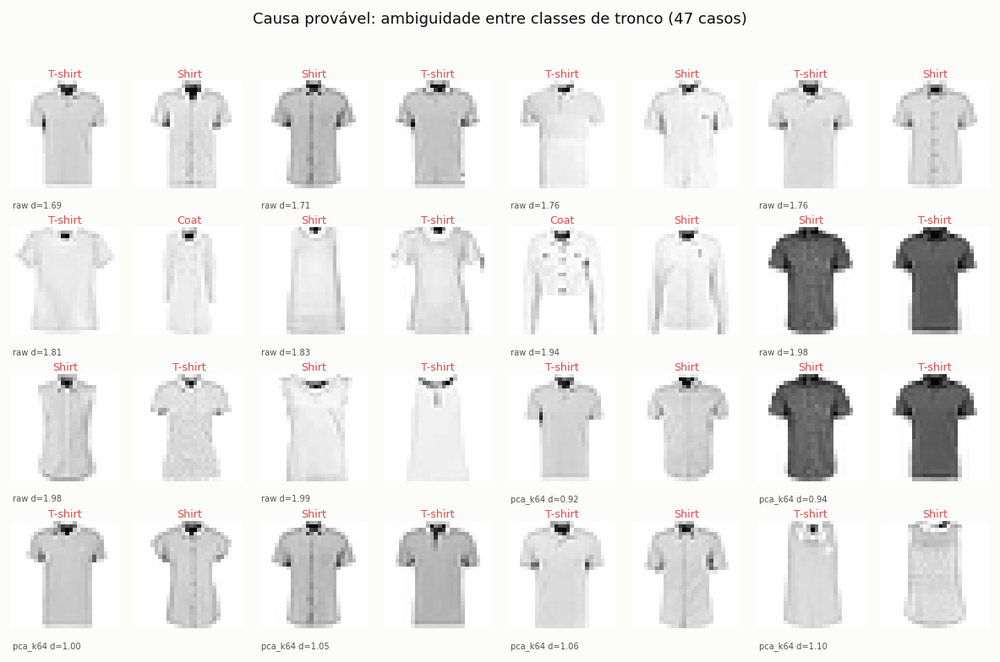

**Figura 48.** Casos de falha agrupados pela causa provável: ambiguidade entre classes de tronco. Ficheiro `outputs/figures/failures_ambiguidade_entre_classes_de_tronco.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

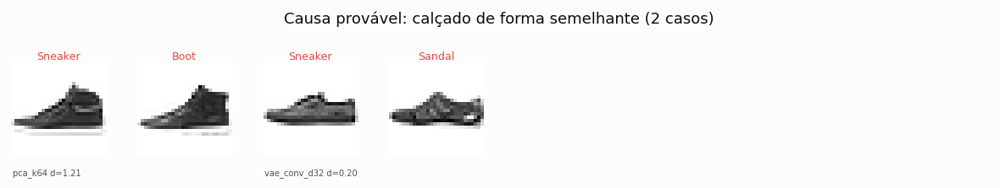

**Figura 49.** Casos de falha agrupados pela causa provável: calçado de forma semelhante. Ficheiro `outputs/figures/failures_calçado_de_forma_semelhante.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

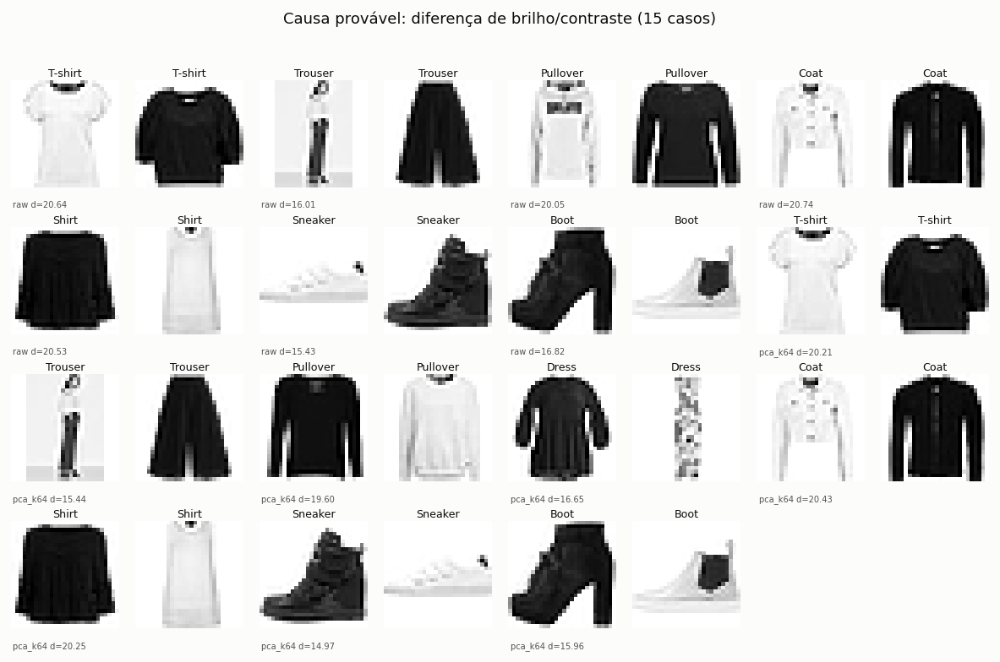

**Figura 50.** Casos de falha agrupados pela causa provável: diferença de brilho/contraste. Ficheiro `outputs/figures/failures_diferença_de_brilho_contraste.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

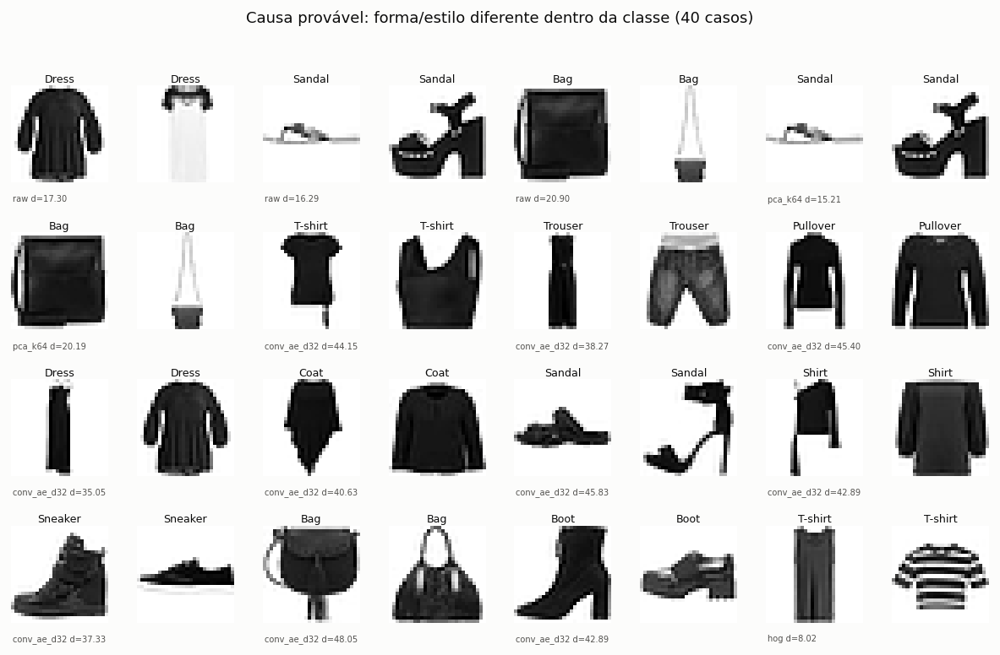

**Figura 51.** Casos de falha agrupados pela causa provável: forma/estilo diferente dentro da classe. Ficheiro `outputs/figures/failures_forma_estilo_diferente_dentro_da_classe.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

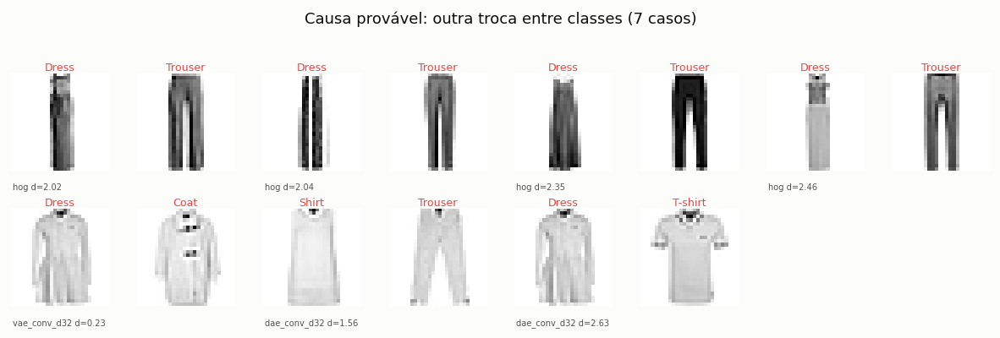

**Figura 52.** Casos de falha agrupados pela causa provável: outra troca entre classes. Ficheiro `outputs/figures/failures_outra_troca_entre_classes.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

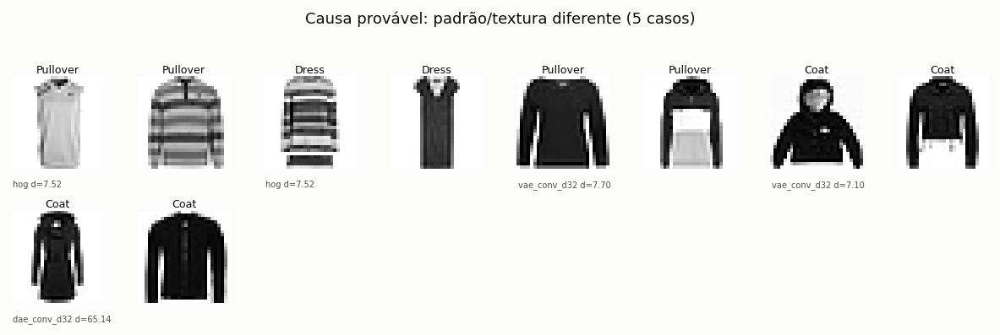

**Figura 53.** Casos de falha agrupados pela causa provável: padrão/textura diferente. Ficheiro `outputs/figures/failures_padrão_textura_diferente.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

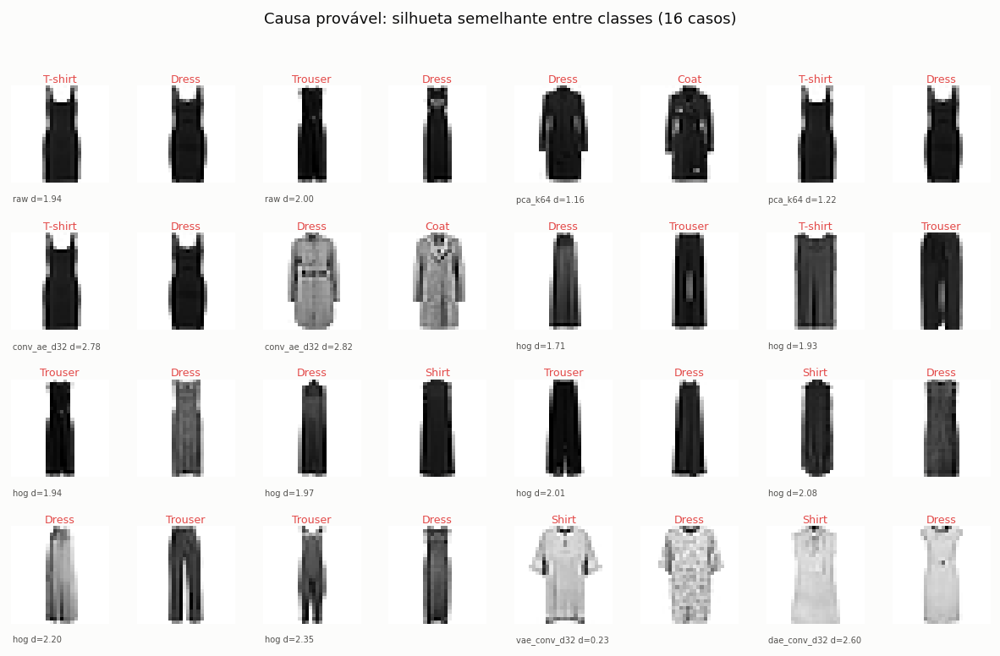

**Figura 54.** Casos de falha agrupados pela causa provável: silhueta semelhante entre classes. Ficheiro `outputs/figures/failures_silhueta_semelhante_entre_classes.png`. **Gerada em** `src/failures.py`, função `figure_by_cause()`, linha 117. **Cálculo:** pares minados, agrupados pela causa de `src/failures.py::cause`. **Dados:** `outputs/failures/failure_cases.csv` (calculado em `src/failures.py`, `main()`, linha 179), `outputs/data/X_train_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73), `outputs/data/X_test_flat.npy` (calculado em `src/data.py`, `prepare()`, linha 73). **Refazer:** `python -m src.failures`.

In [43]:
f = csv('failures/failure_cases.csv')
display(csv('failures/failure_causes_summary.csv'))
display(f.groupby(['espaco', 'tipo', 'causa']).size().rename('n').unstack('causa', fill_value=0))
display(f[['espaco', 'tipo', 'idx_a', 'idx_b', 'nome_a', 'nome_b', 'distancia', 'iou_silhueta', 'causa']].head(30))
display(csv('failures/failures_shared_across_spaces.csv').sort_values('n_espacos', ascending=False).head(10))
for p in sorted(FIG.glob('failures_*.png')):
    if p.name != 'failures_specialized_comparison.png':
        fig(p.name, width=640)

**Interpretação.** Foram minados automaticamente 132 casos, em 6 espaços (22 por espaço: 12 vizinhos mais próximos com classe diferente + 10 pares da mesma classe muito afastados), sem escolha manual. Imagens do test que falham em vários espaços estão em `outputs/failures/failures_shared_across_spaces.csv`.

- **Vizinhos com classe diferente:** em raw, PCA-64 e ConvAE d=32 são quase todos **T-shirt↔Shirt** e **Pullover↔Coat**: polos e camisas de manga curta, ou casacos de malha e camisolas, praticamente idênticos em pixels (IoU de silhueta médio 0.63–0.94). Muitos destes pares são **ambiguidade (ou ruído) de anotação** do próprio dataset; nenhuma representação não supervisionada os pode separar. O ConvAE junta pares com silhuetas ainda mais parecidas (IoU 0.94), o que mostra que o latente codifica sobretudo a forma. O HOG falha de outra maneira: os seus vizinhos errados são sobretudo **Dress↔Trouser**, porque peças longas e verticais têm histogramas de orientação de arestas parecidos, mesmo com silhuetas diferentes.
- **Mesma classe, muito afastados:** em raw e PCA-64 a causa dominante é **brilho/contraste** (uma peça clara e outra escura da mesma classe estão longe em distância euclidiana de pixels). No ConvAE e no HOG (que normaliza blocos) a causa passa a ser **forma/estilo** (ex.: Bag com e sem alça, Sandal aberta vs fechada, Dress curto vs comprido). Ou seja, a representação aprendida e a de arestas são invariantes ao brilho, mas não à variabilidade de estilo dentro da classe.
- **Taxa de erro do 1-NN no test:** ConvAE d=32 13.1%, HOG 14.0%, DAE d=32 15.2%, raw 15.3%, PCA-64 15.4%, VAE d=32 18.0%.

### 8.2 As falhas mudam com o VAE e o DAE?

**Tabela 39.** Todos os erros 1-NN do test por espaço: contagem por par de classes trocado e sobreposição (Jaccard) dos conjuntos de imagens falhadas entre espaços. Ficheiro `outputs/failures/failure_pairs_by_space.csv`. **Escrita em** `src/failures.py`, função `compare_spaces()`, linha 140. **Cálculo:** todos os erros 1-NN do test, por par de classes. **Dados:** features de train/test dos 6 espaços. **Refazer:** `python -m src.failures`.

Taxa de erro do 1-NN no test por espaço:


,taxa_erro_1nn
espaco,
conv_ae_d32,0.1305
hog,0.1400
dae_conv_d32,0.1518
raw,0.1525
pca_k64,0.1535
vae_conv_d32,0.1804


espaco,conv_ae_d32,vae_conv_d32,dae_conv_d32
par,,,
Shirt ↔ T-shirt,297.0,325.0,301.0
Coat ↔ Pullover,204.0,268.0,225.0
Pullover ↔ Shirt,194.0,267.0,223.0
Coat ↔ Shirt,155.0,223.0,180.0
Coat ↔ Dress,77.0,84.0,77.0
Boot ↔ Sneaker,65.0,109.0,60.0
Dress ↔ T-shirt,54.0,95.0,65.0
Sandal ↔ Sneaker,36.0,99.0,62.0
Dress ↔ Shirt,57.0,64.0,67.0


Sobreposição (Jaccard) dos conjuntos de imagens falhadas:


**Tabela 40.** Todos os erros 1-NN do test por espaço: contagem por par de classes trocado e sobreposição (Jaccard) dos conjuntos de imagens falhadas entre espaços. Ficheiro `outputs/failures/failure_overlap_jaccard.csv`. **Escrita em** `src/failures.py`, função `compare_spaces()`, linha 141. **Cálculo:** Jaccard dos conjuntos de imagens falhadas entre espaços. **Dados:** features de train/test dos 6 espaços. **Refazer:** `python -m src.failures`.

,raw,pca_k64,conv_ae_d32,hog,vae_conv_d32,dae_conv_d32
raw,1.0000,0.6114,0.5231,0.3387,0.4239,0.5299
pca_k64,0.6114,1.0000,0.5293,0.3203,0.4524,0.5656
conv_ae_d32,0.5231,0.5293,1.0000,0.3351,0.4281,0.5502
hog,0.3387,0.3203,0.3351,1.0000,0.3078,0.3246
vae_conv_d32,0.4239,0.4524,0.4281,0.3078,1.0000,0.4545
dae_conv_d32,0.5299,0.5656,0.5502,0.3246,0.4545,1.0000


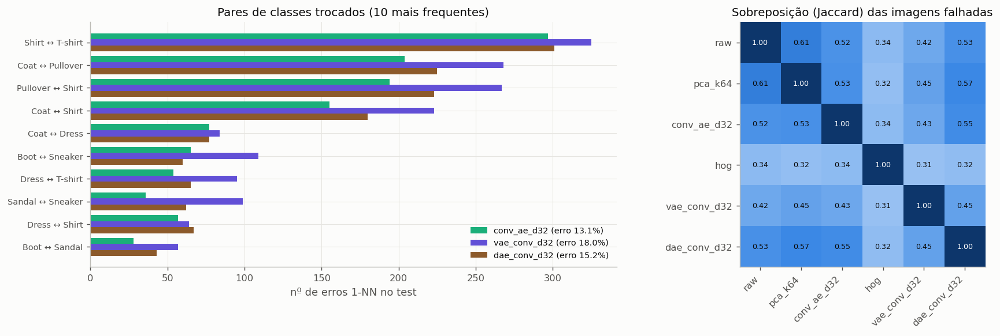

**Figura 55.** Pares de classes trocados (ConvAE vs VAE vs DAE, d=32) e Jaccard das imagens falhadas entre espaços. Ficheiro `outputs/figures/failures_specialized_comparison.png`. **Gerada em** `src/failures.py`, função `compare_spaces()`, linha 160. **Cálculo:** pares mais trocados (ConvAE, VAE, DAE, d=32) e Jaccard. **Dados:** `outputs/failures/failure_pairs_by_space.csv` (calculado em `src/failures.py`, `compare_spaces()`, linha 140), `outputs/failures/failure_overlap_jaccard.csv` (calculado em `src/failures.py`, `compare_spaces()`, linha 141). **Refazer:** `python -m src.failures`.

In [44]:
fp = csv('failures/failure_pairs_by_space.csv')
print('Taxa de erro do 1-NN no test por espaço:')
display(fp.groupby('espaco').taxa_erro_1nn.first().sort_values().to_frame())
sel = ['conv_ae_d32', 'vae_conv_d32', 'dae_conv_d32']
top = fp[fp.espaco.isin(sel)].groupby('par').n_erros.sum().nlargest(10).index
display(fp[fp.espaco.isin(sel)].pivot(index='par', columns='espaco', values='n_erros').reindex(top)[sel])
print('Sobreposição (Jaccard) dos conjuntos de imagens falhadas:')
display(csv('failures/failure_overlap_jaccard.csv', index_col=0))
fig('failures_specialized_comparison.png')

**Interpretação.** Considerando todos os erros 1-NN do test (não só os casos minados):

- **Os pares dominantes não mudam:** Shirt↔T-shirt, Coat↔Pullover, Pullover↔Shirt e Coat↔Shirt são os 4 primeiros nos três modelos e valem 60–65% dos erros. O problema das classes de tronco não depende do objetivo de treino.
- **O VAE erra mais em todos os pares principais, e sobretudo no calçado:** Sandal↔Sneaker passa de 36 para 99 erros, Ankle boot↔Sneaker de 65 para 109 e Ankle boot↔Sandal de 28 para 57. O calçado passa de 9.9% para 14.7% dos erros. É coerente com as reconstruções desfocadas: tiras e formas finas, que distinguem uma sandália de uma sapatilha, são o que o VAE perde (uma leitura plausível, não testada à parte).
- **O DAE fica perto do ConvAE:** tem um pouco mais de erros na maioria dos pares, com alguma subida em Sandal↔Sneaker (62) e Ankle boot↔Sandal (43).
- **Sobreposição:** as imagens falhadas pelo VAE são mais distintas (Jaccard 0.43 com o ConvAE) do que as do DAE (0.55, o mesmo nível de ConvAE vs raw ou PCA, 0.52–0.53). Parte dessa diferença vem de o VAE ter mais erros, o que por si só reduz o Jaccard. O HOG continua a ser o que falha de forma mais diferente (0.31–0.34).
- **Causas prováveis:** os casos minados no VAE e no DAE distribuem-se quase como no ConvAE (9 de 12 vizinhos errados por ambiguidade de tronco; forma/estilo domina os pares da mesma classe).

<a id='conclusoes'></a>

## Conclusões

1. **Dimensão:** o Fashion-MNIST vive numa variedade de dimensão intrínseca de cerca de 16 (TwoNN), mas um subespaço linear precisa de cerca de 40 componentes para saturar o kNN e de 188 para 95% da variância. Os AEs aproveitam a não linearidade: com d=16 já batem o PCA com 64–128 componentes no kNN (0.875–0.885 contra 0.873 no val), e com o mesmo d reconstroem com cerca de metade do erro.
2. **Arquiteturas (a 60 épocas):** com d pequeno as três arquiteturas equivalem-se; com d grande o ConvAE é o melhor a reconstruir (MSE 0.0028, SSIM 0.92 com d=128). O TransformerAE dá os latentes que melhor agrupam e o melhor kNN (0.885 no test, praticamente empatado com o ConvAE d=64, 0.883), mas custa cerca de 5× o ConvAE e 20× o DenseAE em tempo. O DenseAE é o mais barato e estagna com d ≥ 64.
3. **Classificação:** nenhuma representação não supervisionada chega ao teto supervisionado (CNN 0.933): a melhor fica em 0.90 (ConvAE d=128 + MLP, HOG + MLP). A accuracy satura em d≈32–64; as confusões entre as classes de tronco (Shirt, T-shirt, Pullover, Coat) persistem em todos os espaços e parte delas é ambiguidade do próprio dataset.
4. **Retrieval:** o espaço certo depende do objetivo. Para "mesma classe" os espaços supervisionados são os melhores; para "parece-se com a query" ganham os AEs com d intermédio, os pixels e o PCA sem whitening; o HOG fica no meio (classe certa com aspeto diferente). O whitening é prejudicial para a ordenação global, e o cosseno é em geral preferível à distância euclidiana.
5. **Visualização:** o t-SNE preserva melhor as vizinhanças locais e o UMAP a estrutura global; partir de PCA-50 ou de um latente de AE melhora os mapas face aos pixels.

A extensão de cor (Fase 7) não foi usada. Detalhes das decisões em `docs/DECISIONS.md` e diário em `docs/LOG.md`.

### O que ganhámos com objetivos de treino especializados

**Ganhámos propriedades específicas, não uma representação melhor em geral.** Com queries limpas, o ConvAE base supera os dois especializados em reconstrução, retrieval e classificação (com exceções pontuais na LogReg). O DAE dá o ganho mais claro e mensurável: precision@10 de 0.72 contra 0.19 com σ = 0.5, ao custo de cerca de 2 p.p. em dados limpos; é a escolha certa se as queries puderem vir com ruído. O VAE dá um latente de onde se pode amostrar diretamente, e as amostras são claramente mais plausíveis do que as do ConvAE com d ≥ 16, mas isto foi avaliado só visualmente. Em troca fica com a pior reconstrução dos três com d ≥ 8 e, em geral, a pior accuracy e o pior retrieval (com exceções pontuais face ao DAE, como no kNN em d=8), porque com β = 1 e MSE somado usa só cerca de 9 nats, seja qual for d. Valores de β mais baixos deverão mudar este equilíbrio, mas não foram testados: mantive o β pedido. A interpolação "mais suave" do VAE ficou por demonstrar: as medidas escolhidas discordam entre si e têm limitações. A melhor escolha depende, portanto, do que se quer: fidelidade e retrieval (ConvAE), robustez (DAE) ou geração (VAE).

<a id="anexos"></a>

## Anexo A: requisitos do enunciado e da adenda no código

Para cada requisito: as funções que o implementam, os artefactos e a secção deste relatório. O `src/provenance.py` confirma que as funções e os artefactos existem. A coluna `nota` assinala o que não é um simples "feito".

In [45]:
largo(csv('requisitos.csv'))

**Tabela 41.** Requisitos do enunciado e da adenda: código, artefactos e secção do relatório. Ficheiro `outputs/metrics/requisitos.csv`. **Escrita em** `src/provenance.py`, função `main()`, linha 542. **Cálculo:** lista de `src/provenance.py::tabela_requisitos`; confirma que as funções e os artefactos citados existem. **Dados:** src/*.py, outputs/. **Refazer:** `python -m src.provenance`.

,fase,requisito,codigo,artefactos,secao,nota
0,Regras,seed global 42 em python/numpy/torch,`src/utils.py::set_seed`,config.yaml,Fase 0,
1,Regras,versões dos pacotes guardadas,run_all.sh,outputs/env.txt,Fase 0,
2,Regras,"DECISIONS, LOG, manifesto e um log por script","`src/utils.py::register`, `src/utils.py::get_logger`","docs/DECISIONS.md, docs/LOG.md, outputs/manifest.json, outputs/logs/*",Mapa do código,
3,Regras,tudo retomável e idempotente,"`src/utils.py::exists`, `src/train_ae.py::fit` (last.pt)",run_all.sh,Mapa do código,run_all.sh não foi corrido do zero numa pasta limpa; cada passo correu pelos mesmos comandos
4,Fase 0,splits estratificados 54k/6k; test intocável,`src/data.py::prepare`,outputs/splits/*_idx.npy,Fase 0,
5,Fase 0,"normalização [0,1], versões flatten 784 e 1×28×28","`src/data.py::prepare`, `src/data.py::load_split`",outputs/data/*,Fase 0,
6,Fase 1,imagem média por classe,`src/eda.py::main`,outputs/figures/eda_mean_images.png,Fase 1,
7,Fase 1,distâncias intra vs inter-classe (10×10),`src/eda.py::class_distance_matrix`,"outputs/metrics/eda_class_distances.csv, outputs/figures/eda_class_distances.png",Fase 1,
8,Fase 1,"kNN em pixels, confusão e hipótese das classes de tronco","`src/eda.py::main`, `src/evaluate.py::knn_predict`","outputs/metrics/eda_knn_raw_confusion.csv, outputs/metrics/eda_confused_pairs.csv, outputs/metrics/eda_summary.json",Fase 1,
9,GPU,nvidia-smi e plano registados no LOG,`src/train_ae.py::probe`,docs/LOG.md,Fase 0 (0.2),


## Anexo B: índice das figuras

Todas as figuras, pela ordem deste relatório. Os ficheiros estão em `outputs/figures/`.

In [46]:
ix = [{'figura': n, 'ficheiro': k, **({'script': PROV.loc[f'outputs/figures/{k}'].script, 'funcao': PROV.loc[f'outputs/figures/{k}'].funcao,
       'linha': PROV.loc[f'outputs/figures/{k}'].linha, 'comando': PROV.loc[f'outputs/figures/{k}'].comando}
       if not k.startswith('(notebook)') else {'script': 'notebooks/report.ipynb', 'funcao': '-', 'linha': '-', 'comando': '-'})}
      for k, n in MOSTRADAS['figura'].items()]
largo(pd.DataFrame(ix))

,figura,ficheiro,script,funcao,linha,comando
0,1,eda_mean_images.png,src/eda.py,main,55,python -m src.eda
1,2,eda_class_distances.png,src/eda.py,main,68,python -m src.eda
2,3,eda_knn_raw_confusion.png,src/eda.py,main,91,python -m src.eda
3,4,pca_variance.png,src/pca_lda.py,step_full,80,python -m src.pca_lda
4,5,pca_reconstruction_mse.png,src/pca_lda.py,step_reconstruction,129,python -m src.pca_lda
5,6,pca_reconstructions.png,src/pca_lda.py,step_reconstruction,109,python -m src.pca_lda
6,7,pca_eigenfashion.png,src/pca_lda.py,step_reconstruction,120,python -m src.pca_lda
7,8,pca_knn_whitening.png,src/pca_lda.py,step_whitening,172,python -m src.pca_lda
8,9,lda_vs_pca.png,src/pca_lda.py,step_lda,372,python -m src.pca_lda
9,10,twonn.png,src/pca_lda.py,step_twonn,401,python -m src.pca_lda


## Anexo C: índice das tabelas

In [47]:
tb = PROV[PROV.index.str.contains('outputs/metrics/|outputs/failures/') & ~PROV.index.str.contains('metrics/confusion/')]
linhas = tb.reset_index()[['artefacto', 'fase', 'origem', 'script', 'funcao', 'linha', 'comando']]
linhas.insert(1, 'tabela', linhas.artefacto.map(lambda a: MOSTRADAS['tabela'].get(a, '-')))
largo(linhas)

,artefacto,tabela,fase,origem,script,funcao,linha,comando
0,outputs/failures/failure_cases.csv,36,Fase 8,enunciado,src/failures.py,main,179,python -m src.failures
1,outputs/failures/failure_causes_summary.csv,37,Fase 8,enunciado,src/failures.py,main,182,python -m src.failures
2,outputs/failures/failure_overlap_jaccard.csv,40,Fase 8,adenda,src/failures.py,compare_spaces,141,python -m src.failures
3,outputs/failures/failure_pairs_by_space.csv,39,Fase 8,adenda,src/failures.py,compare_spaces,140,python -m src.failures
4,outputs/failures/failures_shared_across_spaces.csv,38,Fase 8,extra,src/failures.py,main,186,python -m src.failures
5,outputs/metrics/ae_summary.csv,20,Fase 4,enunciado,src/train_ae.py,collect,367,python -m src.train_ae --collect
6,outputs/metrics/batch_convergence.csv,5,Teste de GPU,enunciado,src/train_ae.py,probe,507,python -m src.train_ae --probe
7,outputs/metrics/classification.csv,27,Fase 5,enunciado,src/classification.py,run,135,python -m src.classification
8,outputs/metrics/cnn_confusion_test.csv,30,Fase 5,enunciado,src/train_cnn.py,main,109,python -m src.train_cnn
9,outputs/metrics/cnn_confusion_val.csv,31,Fase 5,enunciado,src/train_cnn.py,main,109,python -m src.train_cnn


## Anexo D: modelos, projeções e latentes

Agrupados por tipo, porque são centenas de ficheiros (uma linha por script e função).

In [48]:
resto = PROV[~PROV.index.str.contains('outputs/figures/|outputs/metrics/|outputs/failures/')].reset_index()
resto['pasta'] = resto.artefacto.str.rsplit('/', n=1).str[0].str.replace(r'_d\d+$', '_d*', regex=True)
largo(resto.groupby(['pasta', 'script', 'funcao', 'linha'], sort=False).agg(n_ficheiros=('artefacto', 'size'), exemplo=('artefacto', 'first'), comando=('comando', 'first'), calculo=('calculo', 'first')).reset_index())

,pasta,script,funcao,linha,n_ficheiros,exemplo,comando,calculo
0,outputs/ae/conv_ae_d*,src/train_ae.py,fit,241,6,outputs/ae/conv_ae_d128/best.pt,python -m src.train_ae --arch <arch> --dim <d>,"pesos da época com melhor critério de validação (`src/train_ae.py::fit`, `src/train_ae.py::validate`)"
1,outputs/ae/conv_ae_d*,src/train_ae.py,fit,263,6,outputs/ae/conv_ae_d128/history.csv,python -m src.train_ae --arch <arch> --dim <d>,"uma linha por época: loss de treino, val_mse, LR, tempo (VAE: também val_kl e β)"
2,outputs/ae/conv_ae_d*,src/train_ae.py,train_one,322,6,outputs/ae/conv_ae_d128/metrics.json,python -m src.train_ae --arch <arch> --dim <d>,"MSE/SSIM val e test (`src/train_ae.py::recon_metrics`, `src/evaluate.py::ssim_pairs`), parâmetros, tempo, pico de memória; VAE: `src/train_ae.py::vae_stats`"
3,outputs/ae/dae_conv_d*,src/train_ae.py,fit,241,6,outputs/ae/dae_conv_d128/best.pt,python -m src.train_ae --arch <arch> --dim <d>,"pesos da época com melhor critério de validação (`src/train_ae.py::fit`, `src/train_ae.py::validate`)"
4,outputs/ae/dae_conv_d*,src/train_ae.py,fit,263,6,outputs/ae/dae_conv_d128/history.csv,python -m src.train_ae --arch <arch> --dim <d>,"uma linha por época: loss de treino, val_mse, LR, tempo (VAE: também val_kl e β)"
5,outputs/ae/dae_conv_d*,src/train_ae.py,train_one,322,6,outputs/ae/dae_conv_d128/metrics.json,python -m src.train_ae --arch <arch> --dim <d>,"MSE/SSIM val e test (`src/train_ae.py::recon_metrics`, `src/evaluate.py::ssim_pairs`), parâmetros, tempo, pico de memória; VAE: `src/train_ae.py::vae_stats`"
6,outputs/ae/dense_ae_d*,src/train_ae.py,fit,241,6,outputs/ae/dense_ae_d128/best.pt,python -m src.train_ae --arch <arch> --dim <d>,"pesos da época com melhor critério de validação (`src/train_ae.py::fit`, `src/train_ae.py::validate`)"
7,outputs/ae/dense_ae_d*,src/train_ae.py,fit,263,6,outputs/ae/dense_ae_d128/history.csv,python -m src.train_ae --arch <arch> --dim <d>,"uma linha por época: loss de treino, val_mse, LR, tempo (VAE: também val_kl e β)"
8,outputs/ae/dense_ae_d*,src/train_ae.py,train_one,322,6,outputs/ae/dense_ae_d128/metrics.json,python -m src.train_ae --arch <arch> --dim <d>,"MSE/SSIM val e test (`src/train_ae.py::recon_metrics`, `src/evaluate.py::ssim_pairs`), parâmetros, tempo, pico de memória; VAE: `src/train_ae.py::vae_stats`"
9,outputs/ae/transformer_ae_d*,src/train_ae.py,fit,241,6,outputs/ae/transformer_ae_d128/best.pt,python -m src.train_ae --arch <arch> --dim <d>,"pesos da época com melhor critério de validação (`src/train_ae.py::fit`, `src/train_ae.py::validate`)"


## Verificação final

In [49]:
no_disco = {p.name for p in FIG.glob('*.png')}
FORA_FIG, FORA_TAB = {'pca_per_class.png'}, {'outputs/metrics/pca_per_class.csv'}   # calculados, retirados do relatório por opção
faltam_fig = sorted(no_disco - set(MOSTRADAS['figura']) - FORA_FIG)
tabs = {a for a in PROV.index if a.startswith(('outputs/metrics/', 'outputs/failures/')) and 'metrics/confusion/' not in a and a.endswith(('.csv', '.json'))}
faltam_tab = sorted(tabs - set(MOSTRADAS['tabela']) - FORA_TAB)
print(f"Figuras em outputs/figures: {len(no_disco)}; mostradas aqui: {len(no_disco) - len(faltam_fig) - len(FORA_FIG)}; em falta: {faltam_fig}")
print(f"Figuras desenhadas no próprio notebook: {sum(k.startswith('(notebook)') for k in MOSTRADAS['figura'])}")
print(f"Tabelas CSV/JSON: {len(tabs)}; mostradas aqui: {len(tabs) - len(faltam_tab) - len(FORA_TAB)}; em falta: {faltam_tab}")
print(f"Calculados, mas fora do relatório por opção: {sorted(FORA_FIG | FORA_TAB)}")
print(f"Artefactos com origem registada: {len(PROV)}")
print(f"Scripts no mapa: {len(pd.read_csv(MET / 'scripts.csv'))}")
assert not faltam_fig and not faltam_tab

Figuras em outputs/figures: 53; mostradas aqui: 52; em falta: []
Figuras desenhadas no próprio notebook: 3
Tabelas CSV/JSON: 42; mostradas aqui: 41; em falta: []
Calculados, mas fora do relatório por opção: ['outputs/metrics/pca_per_class.csv', 'pca_per_class.png']
Artefactos com origem registada: 620
Scripts no mapa: 22
